# Capstone Project Module 2
## Menyehatkan Cashflow Iuran Pemeliharaan Lingkungan (IPL) Sinarmas Land
### Pendekatan Hypothesis-Driven
**Nama: Astro Lihardo Aloysius**

Sumber: *Sinarmasland_Brief_Peserta.pdf*, *SinarmasLand_ERD.png*, dan *Panduan_Koneksi_pymysql.docx*. Analisis dijalankan pada **snapshot CSV mentah** hasil ekstraksi database `sinarmasland` (lima tabel, sebelum cleaning).

| Tahap | Isi |
|---|---|
| 1.0 Memahami Masalah | Latar belakang, stakeholder, definisi NPI, **problem statement SMART**, tujuan analisis |
| 2.0 Penyusunan Hipotesis | Komponen masalah, daftar hipotesis, filter hipotesis, hipotesis yang akan diuji |
| 3.0 Data Collection | Arsip koneksi dan ekstraksi MySQL, pembacaan snapshot CSV mentah, tanggal snapshot, ERD |
| 4.0 Data Understanding & Data Cleaning | Memastikan data yang dibutuhkan hipotesis dapat dipercaya, kemudian membersihkannya |
| 5.0 Pengujian Hipotesis | Menguji setiap hipotesis dengan selisih NPI, interval kepercayaan, besar efek, dan pengendalian faktor pengganggu |
| 6.0 EDA Sesuai Stakeholder | Analisis lanjutan untuk Head of Township Management, Collection, Finance, dan IT/ERP |
| 7.0 Kesimpulan & Rekomendasi | Kesimpulan, estimasi dampak, rekomendasi **Actor + Action + Time + Impact**, KPI, serta metodologi dan batasan |

Hipotesis disusun **sebelum** data dieksplorasi (Tahap 2). Pengujiannya (Tahap 5) dilakukan setelah data dibaca dan dibersihkan (Tahap 3–4), karena hipotesis hanya dapat diuji dengan data yang dapat dipercaya. Seluruh hasil uji dibaca sebagai **asosiasi**, bukan hubungan sebab-akibat, karena data bersifat observasional.

# 1.0 Memahami Masalah
## 1.1 Latar Belakang
Sinarmas Land (SML) mengelola lima kota mandiri di Jabodetabek, yaitu BSD City, Grand Wisata, Kota Wisata, Deltamas, dan NavaPark. Selain dari penjualan unit, SML memperoleh pemasukan rutin dari **Iuran Pemeliharaan Lingkungan (IPL)** yang dibayarkan pemilik unit setiap bulan untuk membiayai keamanan, kebersihan, dan perawatan fasilitas umum.

Brief menyebutkan beberapa kondisi berikut:
- Porsi tagihan yang tidak dibayar (**Non-Performing Invoice / NPI**, yaitu gabungan status Unpaid dan Overdue) **diperkirakan** telah melebihi seperempat tagihan.
- Sebagian unit dibeli sebagai investasi dan dibiarkan kosong (**vacant**).
- Metode pembayaran ditulis dengan banyak variasi, sehingga rekonsiliasi tim Finance menjadi sulit.
- Sebagian nomor telepon pemilik tidak lengkap, sehingga tim Collection sulit menjangkau pemilik.
- Terdapat indikasi kesalahan input meteran air dan kemungkinan duplikasi tagihan.

Apabila tidak ditangani, kondisi tersebut menjadi **risiko cashflow** bagi Estate Management dan berpotensi meningkatkan ketergantungan pada subsidi perusahaan induk. Besarnya defisit kas yang sebenarnya belum dapat diukur dari data tagihan, karena data biaya operasional, subsidi, dan realisasi kas tidak tersedia. Head of Township Management memerlukan rekomendasi untuk menurunkan NPI dalam **2 kuartal ke depan**.

## 1.2 Stakeholder
| Stakeholder | Peran | Kebutuhan informasi |
|---|---|---|
| **Head of Township Management** | Pengambil keputusan | Baseline dan target NPI, segmen penyumbang tunggakan, rencana 2 kuartal |
| Tim Collection | Pelaksana penagihan | Unit yang perlu ditagih lebih dahulu dan cara penagihan yang efektif |
| Tim Finance | Rekonsiliasi dan cashflow | Standar metode pembayaran, nominal tagihan bermasalah, program autodebit |
| Tim IT/ERP | Pengelola sistem billing | Daftar kesalahan data dan validasi yang perlu ditambahkan |

## 1.3 Definisi NPI dan Problem Statement SMART
**Metrik inti: NPI rate** = jumlah invoice berstatus Unpaid + Overdue ÷ jumlah invoice yang diterbitkan × 100% (semakin kecil semakin baik).

| Aspek definisi | Ketentuan yang digunakan |
|---|---|
| *Grain* | Satu baris = satu **invoice utama** per unit per bulan tagihan |
| Periode penerbitan | Seluruh `billing_month` yang tersedia pada data (dihitung pada bagian 3.4) |
| Status | `payment_status` **per tanggal snapshot**; data hanya menyimpan status terakhir, bukan riwayat status |
| Invoice ganda | Salinan invoice yang terbit dua kali untuk unit dan bulan yang sama **ditandai dan dikeluarkan** dari perhitungan NPI, tetapi barisnya tetap disimpan untuk audit (bagian 4.4) |
| Unpaid yang belum jatuh tempo | Diperiksa terhadap tanggal snapshot (bagian 4.7); apabila ada, dipisahkan pada analisis umur tunggakan |
| Nominal | `total_amount` invoice NPI merupakan **nominal tagihan bermasalah**, bukan kerugian permanen dan bukan kas yang pasti tertagih |

| Huruf | Arti | Isi untuk kasus Sinarmas Land |
|---|---|---|
| **S** – Specific | Satu metrik, satu objek, cakupan jelas | NPI rate tagihan IPL bulanan di 5 township, 111 cluster, dan 28.881 unit |
| **M** – Measurable | Ada rumus, data, dan baseline | Dihitung dari `sml_ipl_billings.payment_status`; baseline dihitung pada bagian 5.1 |
| **A** – Actionable | Ada tindakan konkret | Prioritas penagihan, program autodebit, kanal pengiriman tagihan, verifikasi kontak, perbaikan sistem billing |
| **R** – Relevant | Terhubung dengan bisnis | IPL adalah sumber kas operasional kawasan; NPI tinggi merupakan risiko cashflow |
| **T** – Time-bound | Ada batas waktu | Hasil penurunan NPI harus terlihat dalam **2 kuartal ke depan** |

**Problem statement SMART:**
> *Bagaimana Head of Township Management dapat menurunkan NPI rate tagihan IPL di 5 township Sinarmas Land dari baseline saat ini ke level target dalam 2 kuartal ke depan, melalui tindakan yang dapat dijalankan tim Collection, Finance, dan IT/ERP?*

Angka baseline (5.1) dan target usulan (6.1.2) dilengkapi setelah data dihitung, sehingga keduanya berasal dari data. Target tersebut berstatus **usulan** dan perlu disetujui manajemen setelah pilot serta validasi biaya dan kapasitas.

## 1.4 Tujuan Analisis (sesuai brief)
1. Mengidentifikasi karakteristik dan segmen unit/kawasan yang paling berkontribusi terhadap tunggakan IPL.
2. Mengestimasi pendapatan yang tertahan akibat tunggakan berkepanjangan.
3. Merumuskan standar pencatatan metode pembayaran untuk tim Finance.
4. Mengevaluasi kualitas data tagihan sebagai dasar rekomendasi kepada tim IT/ERP.

# 2.0 Penyusunan Hipotesis
## 2.1 Komponen Masalah
Mengikuti pola analisis NPL (peminjam, pemberi pinjaman, layanan pinjaman, dan cabang), masalah NPI dipecah menjadi komponen yang terlibat dalam satu tagihan IPL. Kolom data diambil dari ERD.

| # | Komponen | Isi | Kolom data (ERD) |
|---|---|---|---|
| A | **Pemilik unit (pembayar)** | Status hunian, domisili, kontak | `sml_units.is_vacant`, `owner_domicile`, `contact_number`, `contact_verified` |
| B | **Tagihan & cara bayar** | Nominal, autodebit, kanal pengiriman, jatuh tempo, pengingat | `sml_ipl_billings.ipl_base_fee`, `is_autodebit_enrolled`, `billing_channel`, `due_date`, `reminder_sent_count` |
| C | **Kawasan / cluster (tempat)** | Township, fase peluncuran, model kantor pengelola | `sml_clusters.township_name`, `launch_phase`, `management_office_distance_category` |
| D | **Penagih (tim Collection)** | Jenis aksi dan hasilnya | `sml_collection_actions.action_type`, `response_status` |
| E | **Sistem & data tagihan** | Tagihan ganda, input meteran, sengketa | `sml_ipl_billings.invoice_id`, `water_meter_input_method`, `sml_payment_disputes.*` |

## 2.2 Daftar Seluruh Hipotesis
Pola penulisan: **[kelompok A] memiliki NPI lebih tinggi dibandingkan [kelompok B]**. Seluruh dugaan ditulis terlebih dahulu, termasuk yang mungkin tidak dapat diuji.

| Kode | Komponen | Hipotesis |
|---|---|---|
| H1 | A | Unit **vacant** memiliki NPI lebih tinggi dibandingkan unit yang dihuni |
| H2 | A | Unit milik pemilik **Luar Kota/Luar Negeri** memiliki NPI lebih tinggi dibandingkan pemilik Dalam Kota |
| H3 | A | Unit **tanpa nomor kontak / belum terverifikasi** memiliki NPI lebih tinggi |
| H4 | A | Pemilik yang sedang **mengalami kesulitan ekonomi** lebih sering menunggak |
| H5 | A | Pemilik yang **tidak puas terhadap layanan kawasan** sengaja tidak membayar |
| H6 | B | Tagihan **tanpa autodebit** memiliki NPI lebih tinggi |
| H7 | B | Tagihan melalui **Cetak & Antar Fisik** memiliki NPI lebih tinggi dibandingkan Portal Online |
| H8 | B | Unit dengan **tarif IPL tinggi** memiliki NPI lebih tinggi |
| H9 | B | Tagihan dengan **jarak ke jatuh tempo yang pendek** memiliki NPI lebih tinggi |
| H10 | B | Tagihan yang **lebih sering menerima pengingat** lebih jarang menunggak |
| H11 | C | Cluster **New Phase (2021–2023)** memiliki NPI lebih tinggi dibandingkan cluster Established |
| H12 | C | Cluster yang dikelola dari **Regional Hub** memiliki NPI lebih tinggi dibandingkan kantor Onsite |
| H13 | C | Tunggakan **terkonsentrasi**: ≤ 20% cluster menyumbang ≥ 50% nilai tunggakan |
| H14 | D | Aksi **Telepon** lebih sering diikuti pelunasan dibandingkan SMS dan Surat |
| H15 | D | **Penampilan petugas** penagih memengaruhi kemauan membayar |
| H16 | E | Tagihan dengan **input meteran Manual** lebih sering tidak dibayar |
| H17 | E | Tagihan yang **disengketakan** warga lebih sering tidak dibayar |
| H18 | E | **Tagihan ganda** membuat NPI terlihat lebih tinggi dari kondisi sebenarnya |

Ditambah dua **pertanyaan ukur** (belum memiliki dugaan arah): **P1** berapa NPI rate dan bagaimana polanya per cohort; **P2** berapa nominal tagihan bermasalah dan berapa yang telah melewati 90 hari.

## 2.3 Filter Hipotesis
Setiap hipotesis disaring dengan empat pertanyaan:
1. **Apa asumsinya?**
2. **Apa dasar hipotesisnya?** (brief, logika bisnis, atau pengetahuan umum)
3. **Bagaimana mengetahui bahwa asumsinya salah?** Apabila terdapat hasil data yang dapat membantahnya, hipotesis **dapat diuji**.
4. **Apakah datanya tersedia?** (diperiksa pada ERD)

| Kode | Asumsi | Dasar hipotesis | Bagaimana mengetahui salah | Data tersedia? | Hasil |
|---|---|---|---|---|---|
| H1 | Pemilik yang tidak tinggal di unit tidak merasakan layanan dan tidak menerima tagihan fisik | Brief: unit investasi dibiarkan kosong | NPI vacant ≤ NPI dihuni | ✅ `is_vacant` | **Lolos** |
| H2 | Pemilik yang jauh sulit dijangkau dan kurang peduli pada kondisi kawasan | Logika bisnis | NPI luar kota/negeri ≤ dalam kota | ✅ `owner_domicile` | **Lolos** |
| H3 | Tanpa kontak yang valid, penagihan tidak sampai | Brief: kontak tidak lengkap menyulitkan Collection | NPI tanpa kontak ≤ terverifikasi | ✅ `contact_number`, `contact_verified` | **Lolos** |
| H4 | Kondisi ekonomi menentukan kemampuan bayar | Pengetahuan umum | Memerlukan data penghasilan pemilik | ❌ tidak ada pada ERD | Tidak lolos |
| H5 | Warga yang tidak puas memprotes dengan tidak membayar | Logika | Memerlukan data kepuasan | ❌ tidak ada pada ERD | Tidak lolos (didekati melalui H17) |
| H6 | Autodebit membayar secara otomatis tanpa perlu diingat | Logika bisnis | NPI autodebit ≥ tanpa autodebit | ✅ `is_autodebit_enrolled` | **Lolos** |
| H7 | Tagihan kertas dapat tidak sampai, terutama ke unit kosong | Logika operasional | NPI cetak fisik ≤ portal | ✅ `billing_channel` | **Lolos** |
| H8 | Tagihan besar lebih berat dibayar | Brief: IPL premium dapat melebihi Rp1 juta | NPI tarif tinggi ≤ tarif standar | ✅ `ipl_base_fee` | **Lolos** |
| H9 | Waktu bayar yang pendek membuat warga terlambat | Logika | NPI jatuh tempo pendek ≤ panjang | ✅ `billing_month`, `due_date` | **Lolos** |
| H10 | Pengingat membuat warga ingat membayar | Logika | Pengingat dikirim **karena** tagihan belum dibayar, sehingga arah hubungannya terbalik (*reverse causality*) | ⚠️ tersedia, tetapi memerlukan riwayat waktu pengingat dan status sebelum/sesudah pengiriman | Tidak lolos |
| H11 | Warga cluster baru belum terbiasa membayar IPL | Logika bisnis | NPI New Phase ≤ Established | ✅ `launch_phase` | **Lolos** |
| H12 | Tanpa kantor di lokasi, warga merasa kurang dilayani | Logika operasional | NPI Regional Hub ≤ Onsite | ✅ `management_office_distance_category` | **Lolos** |
| H13 | Tarif dan fasilitas berbeda per cluster | Logika bisnis; brief §6 | > 20% cluster diperlukan untuk mencapai 50% tunggakan | ✅ `total_amount`, `cluster_id` | **Lolos** (diukur sebagai **metrik konsentrasi**, bukan uji statistik) |
| H14 | Kontak langsung lebih sulit diabaikan | Logika operasional | Pelunasan setelah Telepon ≤ SMS/Surat | ✅ `action_type`, `payment_date` | **Lolos** (outcome = pembayaran aktual pada billing) |
| H15 | Petugas yang rapi lebih dipercaya | Dugaan umum | Memerlukan data penampilan petugas | ❌ tidak ada dan sulit diukur | Tidak lolos |
| H16 | Meteran manual sering salah, sehingga warga enggan membayar tagihan yang salah | Brief: indikasi salah input manual | NPI Manual ≤ Otomatis | ✅ `water_meter_input_method` | **Lolos** |
| H17 | Warga yang keberatan menahan pembayaran | Brief: sengketa air berminggu-minggu | NPI disengketakan ≤ tidak disengketakan | ✅ `sml_payment_disputes.invoice_id` | **Lolos** |
| H18 | Tagihan ganda ikut terhitung sebagai tunggakan | Brief: kemungkinan duplikasi | NPI tidak berubah setelah salinan dikeluarkan | ✅ `unit_id` + `billing_month` | **Lolos** (disajikan sebagai **rekonsiliasi sebelum/sesudah**, bukan uji kausal) |

**Hasil filter:** 14 hipotesis lolos. H4, H5, H10, dan H15 tidak lolos dan dicatat sebagai keterbatasan.

## 2.4 Hipotesis yang Akan Diuji & Data yang Dibutuhkan
| Kode | Prioritas | Tabel yang digabung (relasi ERD) | Kolom yang harus diperiksa di Tahap 4 |
|---|---|---|---|
| P1, H18 | ★ | billings | `payment_status`, duplikat `unit_id + billing_month` |
| H1, H2, H3 | ★ | billings ⟶ units (`unit_id`) | `is_vacant`, `owner_domicile`, format `contact_number` |
| H6, H7, H8, H9 | ★ (H6, H7) | billings | `is_autodebit_enrolled`, `billing_channel`, `ipl_base_fee`, `due_date` |
| H11, H12, H13 | ★ (H13) | billings ⟶ units ⟶ clusters (`cluster_id`) | `launch_phase`, nilai `total_amount` yang tidak wajar |
| H14 | | actions ⟶ billings (`invoice_id`) | `action_type`, `action_date`, `payment_date`, sinkronisasi dengan status tagihan |
| H16, H17, P2 | | billings, disputes ⟶ billings (`invoice_id`) | `water_usage_m3`, `water_meter_input_method`, `due_date`, `amount_adjusted` |

Prioritas (★) dipilih karena hasilnya langsung memengaruhi keputusan Head of Township Management: penagihan difokuskan pada segmen tertentu atau perbaikan dilakukan secara merata. Hipotesis dikelompokkan menjadi tiga jenis agar tidak tercampur: **dugaan penyebab tunggakan** (H1–H17), **temuan kualitas billing** (H18, bagian 4), dan **ukuran dampak finansial** (P2, bagian 6).

# 3.0 Data Collection
Data diambil dari database MySQL `sinarmasland` mengikuti *Panduan Koneksi pymysql*:
1. Uji koneksi menggunakan **pymysql** dengan pola `with`, sehingga koneksi otomatis tertutup walaupun terjadi error.
2. Pembacaan tabel menggunakan **pandas + SQLAlchemy engine** (`URL.create`), karena pandas memerlukan engine dan `URL.create` aman untuk password yang mengandung karakter khusus seperti `@` atau `#`.
3. Password **tidak ditulis di notebook**, melainkan diketik saat sel dijalankan melalui `getpass`.

Ekstraksi telah dilakukan **satu kali** dan hasilnya disimpan sebagai **snapshot CSV mentah** (lima file `*_raw.csv`). Kode koneksi dan ekstraksi diarsipkan dalam bentuk komentar, sehingga menjalankan ulang notebook (*Restart & Run All*) **tidak mengekstrak ulang database** dan seluruh analisis berjalan pada data yang sama. Query `SELECT *` digunakan karena seluruh kolom diperlukan untuk capstone; pada lingkungan produksi, kolom yang diambil sebaiknya dibatasi pada kolom yang dipakai.

## 3.1 Import Library

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

import warnings
warnings.filterwarnings("ignore")                       # menyembunyikan peringatan agar output tetap ringkas
pd.set_option("display.max_columns", None)               # menampilkan seluruh kolom DataFrame

BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#9aa5b1"     # warna grafik yang dipakai di seluruh notebook

## 3.2 Arsip Uji Koneksi dengan pymysql
Sel berikut adalah arsip uji koneksi yang telah dijalankan pada saat ekstraksi. Sel dinonaktifkan (dijadikan komentar) agar notebook tidak meminta password dan tidak terhubung ke database setiap kali dijalankan.

In [ ]:
# ARSIP UJI KONEKSI (telah dijalankan satu kali; dinonaktifkan agar tidak terhubung ulang ke database)
# import pymysql
# from getpass import getpass
#
# password_db = getpass("Password database: ")    # diketik saat sel dijalankan, tidak tersimpan di notebook
#
# with pymysql.connect(host="vmlp.pwdlearning.cloud", user="student_ds", password=password_db,
#                      database="sinarmasland", port=3306) as connection:
#     with connection.cursor() as cursor:
#         cursor.execute("SHOW TABLES;")
#         print(cursor.fetchall())

## 3.3 Arsip Ekstraksi Tabel dengan pandas + SQLAlchemy
Kelima tabel dibaca dengan `pd.read_sql`, kemudian langsung disimpan sebagai snapshot CSV mentah sebelum proses cleaning apa pun. Snapshot inilah yang dibaca pada bagian 3.4.

In [ ]:
# ARSIP EKSTRAKSI (telah dijalankan satu kali; dinonaktifkan agar tidak mengekstrak ulang database)
# from sqlalchemy import create_engine, URL
#
# url = URL.create(drivername="mysql+pymysql", username="student_ds", password=password_db,
#                  host="vmlp.pwdlearning.cloud", port=3306, database="sinarmasland")
# engine = create_engine(url)
#
# for nama_tabel in ["sml_clusters", "sml_units", "sml_ipl_billings", "sml_collection_actions", "sml_payment_disputes"]:
#     tabel = pd.read_sql(f"SELECT * FROM {nama_tabel}", con=engine)     # hanya perintah baca (SELECT)
#     tabel.to_csv(f"{nama_tabel}_raw.csv", index=False)                 # snapshot mentah, sebelum cleaning

## 3.4 Membaca Snapshot CSV Mentah
Kelima file mentah dibaca dengan dua pengaturan penting:
- `keep_default_na=False, na_values=[""]`: hanya sel yang benar-benar kosong yang dibaca sebagai data kosong (NaN), sama seperti `NULL` pada database.
- `dtype={"contact_number": str}`: nomor telepon dibaca sebagai teks agar formatnya tidak berubah saat dibaca.

File dicari pada folder notebook atau subfolder `data/`, sehingga notebook dapat dijalankan selama kelima file berada di salah satu lokasi tersebut.

In [ ]:
def baca_mentah(nama_file):
    # Mencari file snapshot mentah pada folder notebook atau subfolder data yang umum dipakai
    for folder in ["", "data/", "data_raw/", "data_extract/1_sebelum_cleaning/"]:
        if os.path.exists(folder + nama_file):
            return pd.read_csv(folder + nama_file, keep_default_na=False, na_values=[""], dtype={"contact_number": str})
    raise FileNotFoundError(f"{nama_file} tidak ditemukan. Letakkan file pada folder yang sama dengan notebook.")

clusters = baca_mentah("sml_clusters_raw.csv")
units    = baca_mentah("sml_units_raw.csv")
billings = baca_mentah("sml_ipl_billings_raw.csv")
actions  = baca_mentah("sml_collection_actions_raw.csv")
disputes = baca_mentah("sml_payment_disputes_raw.csv")

tables = {"clusters": clusters, "units": units, "billings": billings, "actions": actions, "disputes": disputes}

In [ ]:
# Kolom tanggal pada data mentah masih berupa teks, sehingga diubah ke datetime untuk kebutuhan pemeriksaan
for kolom in ["billing_month", "due_date", "payment_date"]:
    billings[kolom] = pd.to_datetime(billings[kolom])
units["handover_date"] = pd.to_datetime(units["handover_date"])
actions["action_date"] = pd.to_datetime(actions["action_date"])
disputes["dispute_date"] = pd.to_datetime(disputes["dispute_date"])

# ASUMSI: tanggal snapshot = tanggal kejadian terakhir yang tercatat pada data (log ekstraksi resmi tidak tersedia)
TANGGAL_SNAPSHOT = max(billings["payment_date"].max(), actions["action_date"].max(), disputes["dispute_date"].max())

# Ringkasan sumber data: jumlah baris, kolom, dan rentang tanggal setiap tabel
kolom_tanggal = {"clusters": None, "units": "handover_date", "billings": "billing_month",
                 "actions": "action_date", "disputes": "dispute_date"}
ringkasan_sumber = pd.DataFrame({
    "file": [f"sml_{n}_raw.csv" if n in ["clusters", "units"] else
             {"billings": "sml_ipl_billings_raw.csv", "actions": "sml_collection_actions_raw.csv",
              "disputes": "sml_payment_disputes_raw.csv"}[n] for n in tables],
    "baris": [len(t) for t in tables.values()],
    "kolom": [t.shape[1] for t in tables.values()],
    "tanggal_awal": [tables[n][k].min().date() if k else "-" for n, k in kolom_tanggal.items()],
    "tanggal_akhir": [tables[n][k].max().date() if k else "-" for n, k in kolom_tanggal.items()],
}, index=list(tables))
display(ringkasan_sumber)
bulan_awal, bulan_akhir = billings["billing_month"].min(), billings["billing_month"].max()
print(f"Periode tagihan (billing_month): {bulan_awal:%B %Y} s.d. {bulan_akhir:%B %Y}")
print(f"TANGGAL_SNAPSHOT (asumsi, kejadian terakhir pada data): {TANGGAL_SNAPSHOT.date()}")

,file,baris,kolom,tanggal_awal,tanggal_akhir
clusters,sml_clusters_raw.csv,111,8,-,-
units,sml_units_raw.csv,28881,11,2018-09-01,2024-11-01
billings,sml_ipl_billings_raw.csv,807427,15,2022-07-01,2024-12-01
actions,sml_collection_actions_raw.csv,126772,7,2022-08-16,2025-01-10
disputes,sml_payment_disputes_raw.csv,23928,9,2022-07-04,2025-01-09


Periode tagihan (billing_month): July 2022 s.d. December 2024
TANGGAL_SNAPSHOT (asumsi, kejadian terakhir pada data): 2025-01-27


In [ ]:
# Contoh tiga baris pertama setiap tabel; nomor telepon disamarkan agar data pribadi tidak tampil di output
def samarkan(df):
    tampil = df.head(3).copy()
    if "contact_number" in tampil.columns:
        tampil["contact_number"] = tampil["contact_number"].str[:4] + "******"
    if "owner_name" in tampil.columns:
        tampil["owner_name"] = tampil["owner_name"].str[0] + "***"
    return tampil

for nama, tabel in tables.items():
    print(f"Tabel {nama}:")
    display(samarkan(tabel))

Tabel clusters:


,cluster_id,township_name,cluster_category,launch_phase,facility_tier,zone_type,handover_completion_pct,management_office_distance_category
0,CLS-BSD-18-01,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite
1,CLS-BSD-18-02,BSD City,Middle Residential,2018-2020 (Established),Plus,Residential Core,99.4,Regional Hub
2,CLS-BSD-18-03,BSD City,Middle Residential,2018-2020 (Established),Plus,Residential Core,87.6,Regional Hub


Tabel units:


,unit_id,cluster_id,owner_name,contact_number,owner_domicile,is_vacant,unit_size_m2,ipl_base_fee,handover_date,unit_type,contact_verified
0,UNT-BSD1801-0001,CLS-BSD-18-01,B***,8820******,Dalam Kota,0,115.5,500000,2019-05-24,Rumah Tapak,1
1,UNT-BSD1801-0002,CLS-BSD-18-01,F***,8146******,Dalam Kota,0,90.5,350000,2018-12-15,Rumah Tapak,0
2,UNT-BSD1801-0003,CLS-BSD-18-01,J***,8544******,Luar Kota,1,126.4,500000,2018-11-10,Rumah Tapak,1


Tabel billings:


,invoice_id,unit_id,billing_month,water_usage_m3,water_meter_input_method,ipl_base_fee,late_fee_penalty,total_amount,payment_status,payment_method,payment_date,due_date,billing_channel,reminder_sent_count,is_autodebit_enrolled
0,INV/BSD/202207/00001,UNT-BSD1801-0001,2022-07-01,24.9,Manual,500000,0,686750.0,Overdue,NaN,NaT,2022-08-07,SMS Blast,3,0
1,INV/BSD/202207/00002,UNT-BSD1801-0002,2022-07-01,16.0,Manual,350000,0,470000.0,Paid,KAS,2022-07-11,2022-08-06,SMS Blast,0,0
2,INV/BSD/202207/00003,UNT-BSD1801-0003,2022-07-01,5.5,Manual,500000,0,541250.0,Paid,VA BCA,2022-07-24,2022-08-14,Cetak & Antar Fisik,1,0


Tabel actions:


,action_id,invoice_id,unit_id,action_date,action_type,agent_id,response_status
0,TKT-BGR-20220816-0001,INV/KWS/202208/00087,UNT-KWS1801-0087,2022-08-16,Telepon,AG-BGR-005,Tidak Respon
1,TKT-BGR-20220816-0002,INV/KWS/202208/00695,UNT-KWS1804-0096,2022-08-16,Telepon,AG-BGR-006,Tidak Respon
2,TKT-BGR-20220816-0003,INV/KWS/202208/00900,UNT-KWS1806-0045,2022-08-16,Telepon,AG-BGR-004,Tidak Respon


Tabel disputes:


,dispute_id,invoice_id,unit_id,dispute_date,dispute_channel,dispute_reason,resolution_status,days_to_resolve,amount_adjusted
0,DSP/220704/3644,INV/BSD/202207/04627,UNT-BSD2119-0248,2022-07-04,Call Center,Sudah Bayar Tapi Tercatat Belum Lunas,Ditolak - Tagihan Sah,3.0,0.0
1,DSP/220704/6327,INV/KWS/202207/04881,UNT-KWS2018-0068,2022-07-04,Kantor Pengelola,Kesalahan Nominal Lainnya,Ditolak - Tagihan Sah,5.0,0.0
2,DSP/220704/7272,INV/DLT/202207/00466,UNT-DLT1903-0280,2022-07-04,Call Center,Sudah Bayar Tapi Tercatat Belum Lunas,Ditolak - Tagihan Sah,3.0,0.0


## 3.5 Struktur Data (ERD)
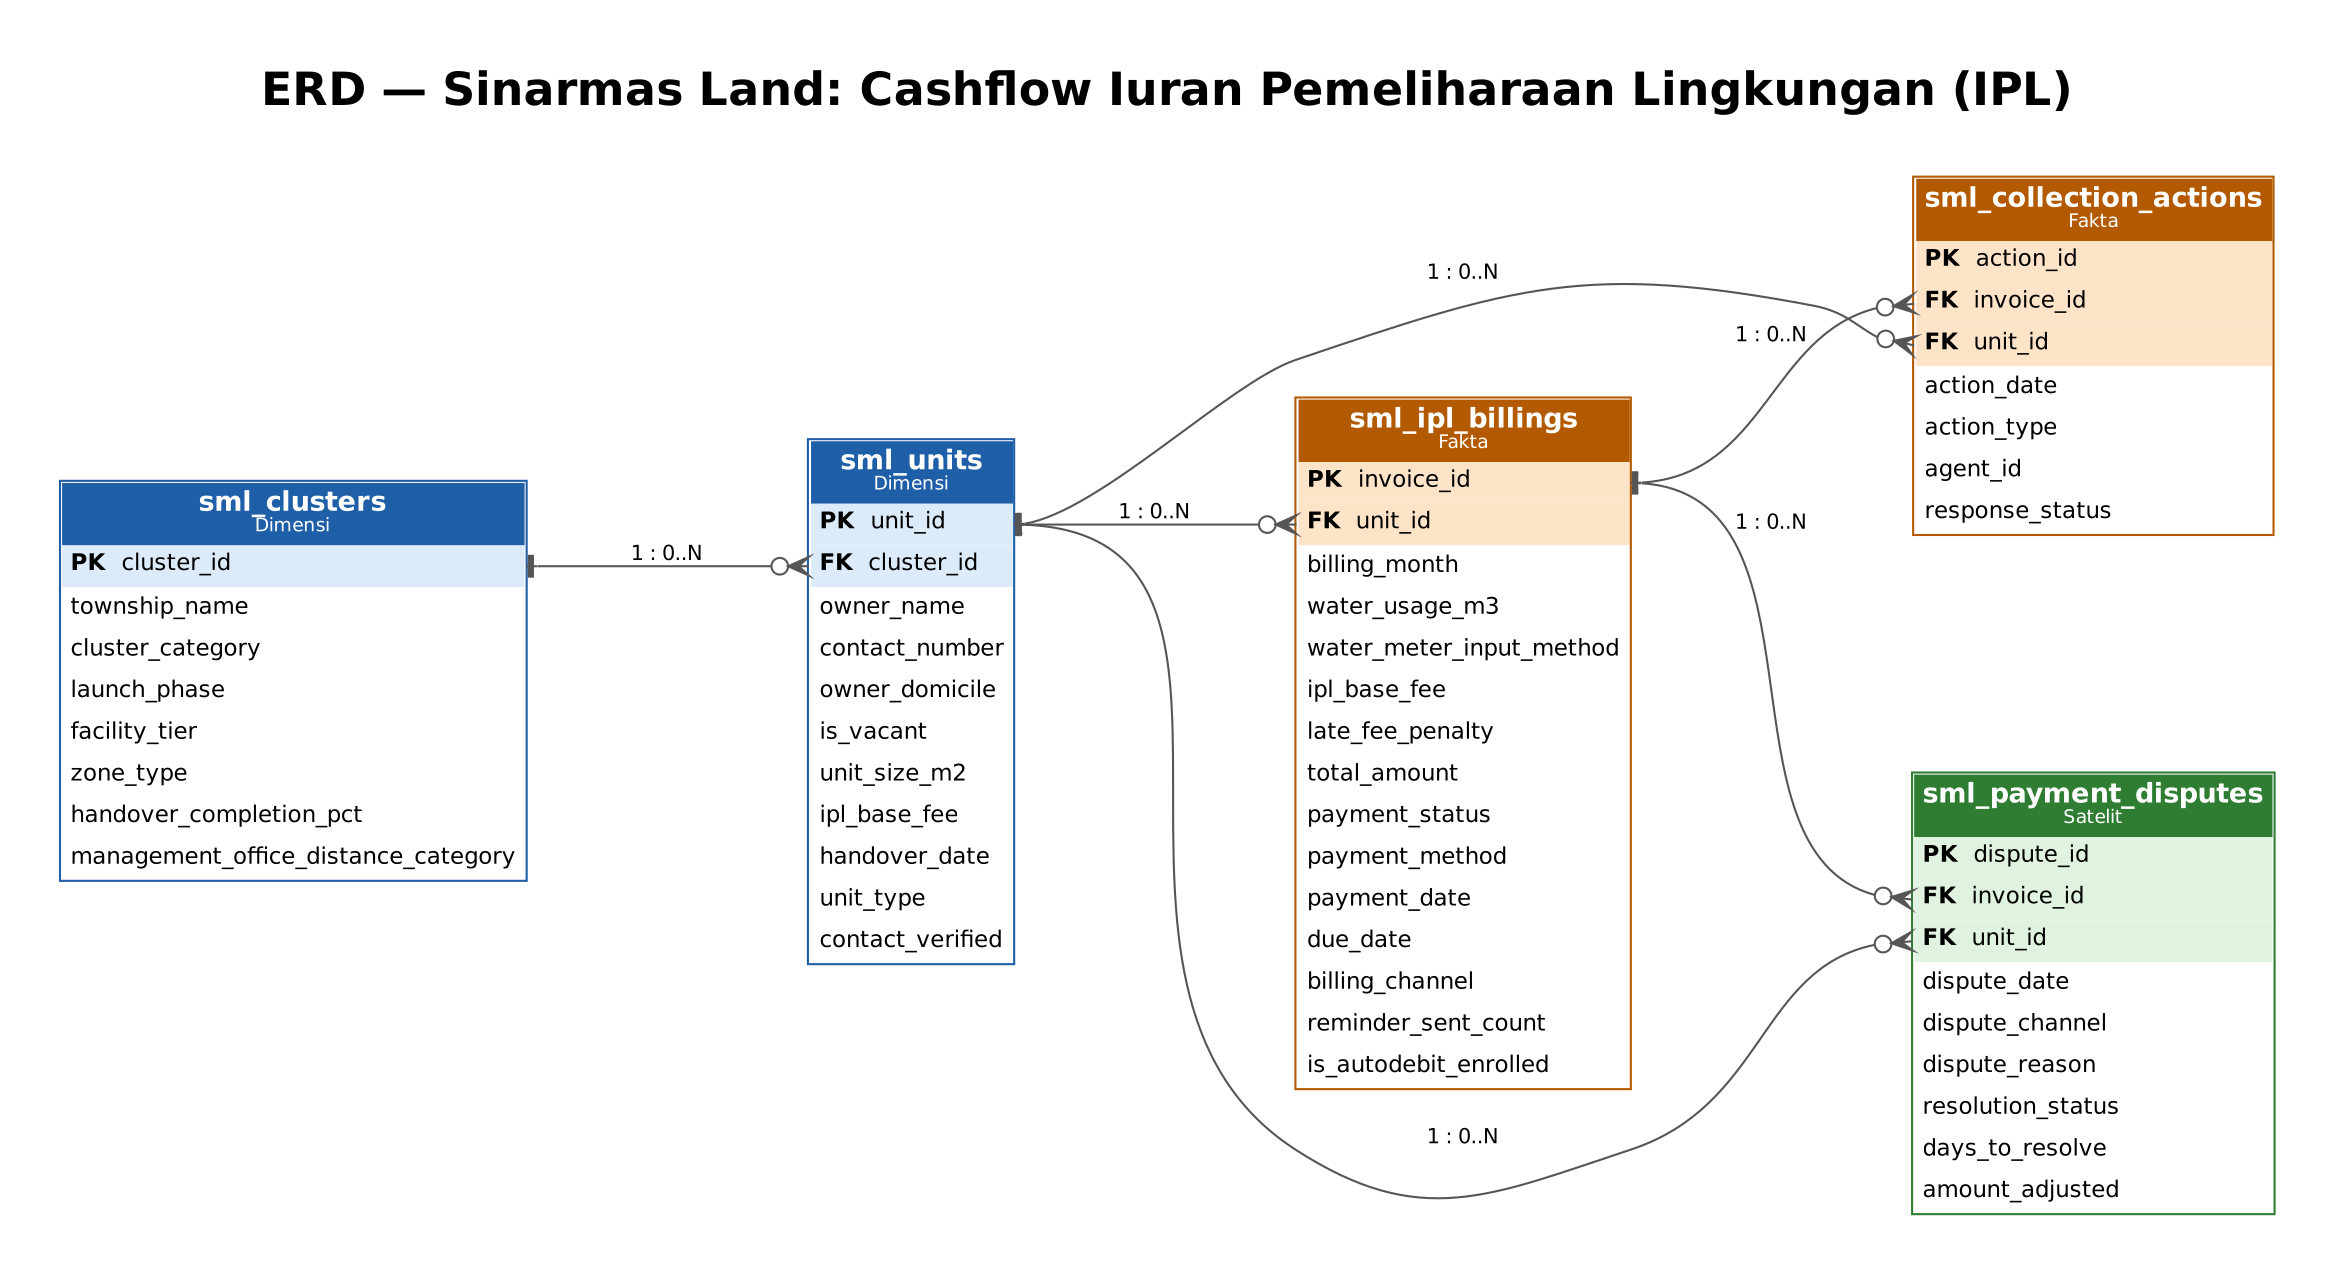

| Tabel | Jenis | Isi | PK | FK |
|---|---|---|---|---|
| `sml_clusters` | Dimensi | Data cluster/kawasan | `cluster_id` | – |
| `sml_units` | Dimensi | Unit dan pemiliknya | `unit_id` | `cluster_id` → clusters |
| `sml_ipl_billings` | Fakta | Tagihan IPL bulanan | `invoice_id` | `unit_id` → units |
| `sml_collection_actions` | Fakta | Riwayat aksi penagihan | `action_id` | `invoice_id` → billings, `unit_id` → units |
| `sml_payment_disputes` | Satelit | Sengketa tagihan | `dispute_id` | `invoice_id` → billings, `unit_id` → units |

Seluruh relasi bertipe **1 : 0..N**: satu cluster memiliki banyak unit, satu unit memiliki banyak tagihan, dan satu tagihan dapat memiliki nol atau beberapa aksi penagihan dan sengketa.

> **Aturan penting:** tabel `billings`, `actions`, dan `disputes` **tidak digabung sekaligus** lalu dijumlahkan `total_amount`-nya. Karena satu invoice dapat memiliki banyak aksi dan banyak sengketa, penggabungan seperti itu akan menggandakan nominal. Aksi dan sengketa selalu diringkas terlebih dahulu ke tingkat invoice sebelum digabung.

# 4.0 Data Understanding & Data Cleaning
Tujuan tahap ini adalah memastikan kolom yang dibutuhkan hipotesis (tabel 2.4) dapat dipercaya, sesuai Catatan Kualitas Data pada brief (bagian5). Prinsip yang dipegang: **database tidak diubah**, **baris tidak dihapus tanpa jejak**, dan setiap masalah data **ditandai (flag)** beserta alasannya.
## 4.1 Profil Kolom

In [ ]:
def profil_kolom(df):
    # Ringkasan setiap kolom: tipe data, jumlah dan persen data kosong, serta jumlah nilai unik
    return pd.DataFrame({
        "tipe_data": df.dtypes.astype(str),
        "jumlah_kosong": df.isna().sum(),
        "persen_kosong": (df.isna().mean() * 100).round(2),
        "jumlah_unik": df.nunique(),
    })

for nama, tabel in tables.items():
    print(f"===== {nama} =====")
    display(profil_kolom(tabel))

===== clusters =====


,tipe_data,jumlah_kosong,persen_kosong,jumlah_unik
cluster_id,str,0,0.0,111
township_name,str,0,0.0,5
cluster_category,str,0,0.0,4
launch_phase,str,0,0.0,2
facility_tier,str,0,0.0,3
zone_type,str,0,0.0,3
handover_completion_pct,float64,0,0.0,97
management_office_distance_category,str,0,0.0,2


===== units =====


,tipe_data,jumlah_kosong,persen_kosong,jumlah_unik
unit_id,str,0,0.00,28881
cluster_id,str,0,0.00,111
owner_name,str,0,0.00,2560
contact_number,str,4978,17.24,23903
owner_domicile,str,0,0.00,3
is_vacant,int64,0,0.00,2
unit_size_m2,float64,0,0.00,3110
ipl_base_fee,int64,0,0.00,4
handover_date,datetime64[us],0,0.00,2074
unit_type,str,0,0.00,2


===== billings =====


,tipe_data,jumlah_kosong,persen_kosong,jumlah_unik
invoice_id,str,0,0.00,807427
unit_id,str,0,0.00,28881
billing_month,datetime64[us],0,0.00,30
water_usage_m3,float64,0,0.00,3878
water_meter_input_method,str,0,0.00,2
ipl_base_fee,int64,0,0.00,4
late_fee_penalty,int64,0,0.00,20
total_amount,float64,0,0.00,7699
payment_status,str,0,0.00,3
payment_method,str,298426,36.96,9


===== actions =====


,tipe_data,jumlah_kosong,persen_kosong,jumlah_unik
action_id,str,0,0.0,126772
invoice_id,str,0,0.0,82806
unit_id,str,0,0.0,21009
action_date,datetime64[us],0,0.0,705
action_type,str,0,0.0,3
agent_id,str,0,0.0,24
response_status,str,0,0.0,4


===== disputes =====


,tipe_data,jumlah_kosong,persen_kosong,jumlah_unik
dispute_id,str,0,0.00,23928
invoice_id,str,0,0.00,23928
unit_id,str,0,0.00,15584
dispute_date,datetime64[us],0,0.00,919
dispute_channel,str,0,0.00,3
dispute_reason,str,0,0.00,4
resolution_status,str,0,0.00,3
days_to_resolve,float64,2722,11.38,29
amount_adjusted,float64,2722,11.38,2782


In [ ]:
billings.describe().round(2)

,billing_month,water_usage_m3,ipl_base_fee,late_fee_penalty,total_amount,payment_date,due_date,reminder_sent_count,is_autodebit_enrolled
count,807427,807427.00,807427.00,807427.00,807427.00,509001,807427,807427.00,807427.00
mean,2023-10-09 22:35:00.922560,39.17,531212.23,5436.49,830779.84,2023-09-11 03:55:41.903847,2023-11-18 10:33:36.440867,1.85,0.14
min,2022-07-01 00:00:00,-19.00,350000.00,0.00,350000.00,2015-11-11 00:00:00,2022-08-05 00:00:00,0.00,0.00
25%,2023-04-01 00:00:00,4.10,350000.00,0.00,475250.00,2023-03-05 00:00:00,2023-05-07 00:00:00,1.00,0.00
50%,2023-10-01 00:00:00,14.80,500000.00,0.00,551000.00,2023-10-13 00:00:00,2023-11-11 00:00:00,1.00,0.00
75%,2024-05-01 00:00:00,21.00,500000.00,0.00,656000.00,2024-05-25 00:00:00,2024-06-15 00:00:00,3.00,0.00
max,2024-12-01 00:00:00,9996.00,1500000.00,180000.00,76470000.00,2025-01-27 00:00:00,2025-01-15 00:00:00,6.00,1.00
std,NaN,404.90,287258.40,16684.36,3052522.95,NaN,NaN,1.70,0.35



**Insight:**
- Data kosong hanya terdapat pada `units.contact_number` (4.978 unit; 17,24%), `billings.payment_method` dan `payment_date` (masing-masing 298.426 invoice; 36,96%), serta `disputes.days_to_resolve` dan `amount_adjusted` (masing-masing 2.722 sengketa; 11,38%). Kewajarannya diperiksa pada bagian 4.3.
- `water_usage_m3` memiliki nilai minimum **−19** dan maksimum **9.996** m³, sedangkan `total_amount` maksimum mencapai **Rp76,47 juta** (diperiksa pada 4.6).
- `payment_date` paling awal adalah **11 November 2015**, jauh sebelum periode tagihan dimulai (diperiksa pada 4.7). Jatuh tempo paling akhir adalah 15 Januari 2025, sedangkan kejadian terakhir pada data adalah 27 Januari 2025 (`TANGGAL_SNAPSHOT`).


## 4.2 Relasi Antartabel (sesuai ERD)

In [ ]:
# Primary key harus unik
pk = {"clusters": "cluster_id", "units": "unit_id", "billings": "invoice_id",
      "actions": "action_id", "disputes": "dispute_id"}
for nama, kolom in pk.items():
    print(f"{nama}.{kolom} ganda: {tables[nama][kolom].duplicated().sum()}")
print()

# Foreign key harus memiliki pasangan di tabel induk (tidak ada orphan key)
fk = [("units", "cluster_id", "clusters"), ("billings", "unit_id", "units"),
      ("actions", "invoice_id", "billings"), ("actions", "unit_id", "units"),
      ("disputes", "invoice_id", "billings"), ("disputes", "unit_id", "units")]
for anak, kolom, induk in fk:
    orphan = (~tables[anak][kolom].isin(tables[induk][kolom])).sum()
    print(f"{anak}.{kolom} tanpa pasangan di {induk}: {orphan}")

clusters.cluster_id ganda: 0
units.unit_id ganda: 0
billings.invoice_id ganda: 0
actions.action_id ganda: 0
disputes.dispute_id ganda: 0

units.cluster_id tanpa pasangan di clusters: 0
billings.unit_id tanpa pasangan di units: 0
actions.invoice_id tanpa pasangan di billings: 0
actions.unit_id tanpa pasangan di units: 0
disputes.invoice_id tanpa pasangan di billings: 0
disputes.unit_id tanpa pasangan di units: 0


In [ ]:
# unit_id pada actions dan disputes harus sama dengan pemilik invoice pada billings
acuan = billings[["invoice_id", "unit_id"]]
for nama in ["actions", "disputes"]:
    cek = tables[nama].merge(acuan, on="invoice_id", suffixes=("", "_billings"), validate="many_to_one")
    berbeda = (cek["unit_id"] != cek["unit_id_billings"]).sum()
    print(f"{nama}: unit_id berbeda dengan pemilik invoice = {berbeda}")

actions: unit_id berbeda dengan pemilik invoice = 0
disputes: unit_id berbeda dengan pemilik invoice = 0



**Insight:** seluruh *primary key* unik, seluruh *foreign key* memiliki pasangan, dan `unit_id` pada aksi dan sengketa sama dengan pemilik invoice. **Relasi sesuai ERD dan tabel aman digabung.** Hasil "0 orphan" hanya membuktikan bahwa ID saling cocok, belum membuktikan validitas bisnis setiap nilai; karena itu *grain* unit-bulan, tanggal, dan nominal tetap diperiksa pada bagian 4.4–4.7.


## 4.3 Missing Value
Kekosongan dibedakan menjadi dua jenis berdasarkan aturan bisnis tertulis:

| Kolom | Aturan bisnis | Kosong **wajar** apabila | Kosong **bermasalah** apabila |
|---|---|---|---|
| `payment_date`, `payment_method` | Hanya terisi setelah tagihan dibayar | Status Unpaid/Overdue | Status Paid tetapi kosong, atau status belum dibayar tetapi terisi |
| `days_to_resolve`, `amount_adjusted` | Hanya terisi setelah sengketa selesai | Status Diproses | Status final (Dibatalkan/Ditolak) tetapi kosong |
| `contact_number` | Diisi saat serah terima/pendaftaran | Tidak ada pengecualian | Kosong = temuan kualitas data bagi tim CS |
| Kolom lain | Wajib terisi | Tidak ada pengecualian | Setiap kekosongan |

In [ ]:
lunas = billings["payment_status"] == "Paid"
selesai = disputes["resolution_status"] != "Diproses"

# Setiap aturan dihitung jumlah pelanggarannya (0 = sesuai aturan bisnis)
cek_kosong = pd.Series({
    "Paid tetapi payment_date kosong": (lunas & billings["payment_date"].isna()).sum(),
    "Paid tetapi payment_method kosong": (lunas & billings["payment_method"].isna()).sum(),
    "Belum dibayar tetapi payment_date terisi": (~lunas & billings["payment_date"].notna()).sum(),
    "Belum dibayar tetapi payment_method terisi": (~lunas & billings["payment_method"].notna()).sum(),
    "Sengketa final tetapi days_to_resolve kosong": (selesai & disputes["days_to_resolve"].isna()).sum(),
    "Sengketa final tetapi amount_adjusted kosong": (selesai & disputes["amount_adjusted"].isna()).sum(),
    "Sengketa Diproses tetapi amount_adjusted terisi": (~selesai & disputes["amount_adjusted"].notna()).sum(),
    "Unit tanpa contact_number": units["contact_number"].isna().sum(),
    "Kolom lain yang kosong (seluruh tabel)": sum(t.drop(columns=["payment_date", "payment_method", "days_to_resolve",
                                                                    "amount_adjusted", "contact_number"], errors="ignore")
                                                  .isna().sum().sum() for t in tables.values()),
})
display(cek_kosong.to_frame("jumlah_baris"))

print("contact_number kosong (True) per status verifikasi:")
display(pd.crosstab(units["contact_verified"], units["contact_number"].isna()))

,jumlah_baris
Paid tetapi payment_date kosong,0
Paid tetapi payment_method kosong,0
Belum dibayar tetapi payment_date terisi,0
Belum dibayar tetapi payment_method terisi,0
Sengketa final tetapi days_to_resolve kosong,0
Sengketa final tetapi amount_adjusted kosong,0
Sengketa Diproses tetapi amount_adjusted terisi,0
Unit tanpa contact_number,4978
Kolom lain yang kosong (seluruh tabel),0


contact_number kosong (True) per status verifikasi:


contact_number,False,True
contact_verified,,
0,3984,4978
1,19919,0



**Insight:**
- Seluruh aturan bisnis terpenuhi (0 pelanggaran): `payment_date` dan `payment_method` **selalu terisi** pada status Paid dan **selalu kosong** pada Unpaid/Overdue, sedangkan `days_to_resolve` dan `amount_adjusted` hanya kosong pada sengketa Diproses. Kekosongan tersebut **wajar** dan dibiarkan apa adanya.
- **4.978 unit tanpa nomor kontak** merupakan kekosongan **bermasalah**; seluruhnya juga belum terverifikasi. Selain itu, 3.984 unit memiliki nomor tetapi belum terverifikasi. Nomor tidak diimputasi, karena nomor tebakan akan menyesatkan tim Collection; dampaknya diuji pada **H3**.


## 4.4 Duplikat
Pemeriksaan dilakukan pada tiga tingkat: duplikat baris penuh, duplikat *primary key* (bagian 4.2), dan **duplikat bisnis**, yaitu satu unit ditagih lebih dari sekali pada bulan yang sama. Untuk investigasi digunakan `keep=False`, sehingga **seluruh anggota pasangan** dapat diperiksa sebelum ditentukan invoice utamanya.

In [ ]:
for nama, tabel in tables.items():
    print(f"{nama}: {tabel.duplicated().sum()} baris duplikat penuh")
print()

# keep=False menandai SELURUH anggota pasangan unit-bulan yang sama, bukan hanya baris kedua
kunci = ["unit_id", "billing_month"]
pasangan_ganda = billings.duplicated(subset=kunci, keep=False)
print("Invoice yang termasuk pasangan unit-bulan ganda:", pasangan_ganda.sum())
print("Jumlah pasangan unit-bulan ganda              :", billings[pasangan_ganda].groupby(kunci).ngroups)
print(billings[pasangan_ganda]["billing_month"].dt.strftime("%Y-%m").value_counts().sort_index())

clusters: 0 baris duplikat penuh
units: 0 baris duplikat penuh
billings: 0 baris duplikat penuh
actions: 0 baris duplikat penuh
disputes: 0 baris duplikat penuh

Invoice yang termasuk pasangan unit-bulan ganda: 76898
Jumlah pasangan unit-bulan ganda              : 38449
billing_month
2023-06    18764
2023-07    19166
2023-08    19274
2023-09    19694
Name: count, dtype: int64


In [ ]:
# Bukti sebelum menentukan invoice utama: bandingkan isi kedua invoice dalam setiap pasangan
ganda = billings[pasangan_ganda].sort_values(kunci + ["invoice_id"])
ganda["pola_9xxxx"] = ganda["invoice_id"].str[-5:].str.startswith("9")    # nomor urut invoice diawali angka 9
grup = ganda.groupby(kunci)

bukti = pd.Series({
    "Pasangan berisi tepat 2 invoice (%)": (grup.size() == 2).mean() * 100,
    "Pasangan dengan tepat 1 invoice pola 9xxxx (%)": (grup["pola_9xxxx"].sum() == 1).mean() * 100,
    "Invoice pola 9xxxx di luar pasangan ganda": (billings["invoice_id"].str[-5:].str.startswith("9") & ~pasangan_ganda).sum(),
    "total_amount sama dalam pasangan (%)": (grup["total_amount"].nunique() == 1).mean() * 100,
    "water_usage_m3 sama dalam pasangan (%)": (grup["water_usage_m3"].nunique() == 1).mean() * 100,
    "ipl_base_fee dan denda sama dalam pasangan (%)": ((grup["ipl_base_fee"].nunique() == 1) & (grup["late_fee_penalty"].nunique() == 1)).mean() * 100,
    "Aksi penagihan pada invoice pola 9xxxx": actions["invoice_id"].isin(ganda.loc[ganda["pola_9xxxx"], "invoice_id"]).sum(),
}).round(2)
display(bukti.to_frame("hasil"))

# Contoh pasangan (kedua anggota) dan kombinasi status pembayarannya
kolom_cek = ["invoice_id", "unit_id", "billing_month", "total_amount", "water_usage_m3", "payment_status", "payment_date"]
display(ganda[kolom_cek].head(6))
kombinasi_status = grup["payment_status"].apply(lambda s: " + ".join(sorted(s)))
display(kombinasi_status.value_counts().to_frame("jumlah_pasangan"))

# Status invoice non-9xxxx dibandingkan status salinannya: apakah ada pembayaran yang hanya tercatat pada salinan?
status_utama = ganda[~ganda["pola_9xxxx"]].set_index(kunci)["payment_status"].rename("invoice non-9xxxx")
status_salinan = ganda[ganda["pola_9xxxx"]].set_index(kunci)["payment_status"].rename("invoice 9xxxx")
pd.crosstab(status_utama, status_salinan.reindex(status_utama.index))

,hasil
Pasangan berisi tepat 2 invoice (%),100.0
Pasangan dengan tepat 1 invoice pola 9xxxx (%),100.0
Invoice pola 9xxxx di luar pasangan ganda,0.0
total_amount sama dalam pasangan (%),100.0
water_usage_m3 sama dalam pasangan (%),100.0
ipl_base_fee dan denda sama dalam pasangan (%),100.0
Aksi penagihan pada invoice pola 9xxxx,0.0


,invoice_id,unit_id,billing_month,total_amount,water_usage_m3,payment_status,payment_date
80950,INV/BSD/202307/00001,UNT-BSD1801-0001,2023-07-01,618500.0,15.8,Paid,2023-07-02
88444,INV/BSD/202307/90001,UNT-BSD1801-0001,2023-07-01,618500.0,15.8,Unpaid,NaT
91291,INV/BSD/202308/00001,UNT-BSD1801-0001,2023-08-01,713000.0,28.4,Paid,2023-08-26
98904,INV/BSD/202308/90001,UNT-BSD1801-0001,2023-08-01,713000.0,28.4,Unpaid,NaT
91292,INV/BSD/202308/00002,UNT-BSD1801-0002,2023-08-01,479750.0,17.3,Paid,2016-10-13
98905,INV/BSD/202308/90002,UNT-BSD1801-0002,2023-08-01,479750.0,17.3,Unpaid,NaT


,jumlah_pasangan
payment_status,
Paid + Paid,12568
Paid + Unpaid,12240
Overdue + Overdue,4946
Overdue + Unpaid,4887
Unpaid + Unpaid,3808


invoice 9xxxx,Overdue,Paid,Unpaid
invoice non-9xxxx,,,
Overdue,4946,0,4887
Paid,0,12568,12240
Unpaid,0,0,3808



**Insight dan keputusan:**
- Tidak ada duplikat baris penuh, tetapi terdapat **38.449 pasangan unit-bulan ganda** (76.898 invoice) pada **Juni–September 2023**.
- Bukti bahwa salah satu anggota pasangan adalah **salinan yang terbit dua kali**: setiap pasangan berisi tepat dua invoice; tepat satu di antaranya bernomor pola **9xxxx**; tidak ada invoice 9xxxx di luar pasangan; `total_amount`, pemakaian air, tarif IPL, dan denda **identik 100%**; serta tidak ada satu pun aksi penagihan pada invoice 9xxxx.
- Tabel silang status menunjukkan bahwa invoice 9xxxx **tidak pernah** berstatus lebih baik daripada pasangannya (tidak ada pasangan dengan invoice non-9xxxx belum dibayar tetapi salinannya Paid). Dengan demikian, memilih invoice non-9xxxx sebagai **invoice utama** tidak menghilangkan catatan pembayaran apa pun.
- **Keputusan:** invoice 9xxxx diberi penanda `flag_duplikat_terbit` beserta alasan eksklusinya dan **dikeluarkan dari perhitungan NPI**, tetapi barisnya tetap disimpan. Aturan ini perlu dikonfirmasi tim IT/ERP sebagai aturan resmi.
- **12.568 pasangan berstatus Paid + Paid** merupakan indikasi pembayaran ganda yang perlu direkonsiliasi tim Finance (H18 dan 6.3).


## 4.5 Penulisan Tidak Konsisten

In [ ]:
kolom_kategori = {
    "clusters": ["township_name", "cluster_category", "launch_phase", "management_office_distance_category"],
    "units":    ["owner_domicile", "unit_type"],
    "billings": ["water_meter_input_method", "payment_status", "payment_method", "billing_channel"],
    "actions":  ["action_type", "response_status"],
    "disputes": ["dispute_reason", "resolution_status"],
}
# Jika jumlah nilai unik berkurang setelah strip + lower, berarti ada variasi spasi atau huruf besar/kecil
for nama_tabel, daftar_kolom in kolom_kategori.items():
    for kolom in daftar_kolom:
        nilai = tables[nama_tabel][kolom].dropna()
        print(f"{nama_tabel}.{kolom}: {nilai.nunique()} nilai unik | setelah strip + lower: {nilai.str.strip().str.lower().nunique()}")

clusters.township_name: 5 nilai unik | setelah strip + lower: 5
clusters.cluster_category: 4 nilai unik | setelah strip + lower: 4
clusters.launch_phase: 2 nilai unik | setelah strip + lower: 2
clusters.management_office_distance_category: 2 nilai unik | setelah strip + lower: 2
units.owner_domicile: 3 nilai unik | setelah strip + lower: 3
units.unit_type: 2 nilai unik | setelah strip + lower: 2
billings.water_meter_input_method: 2 nilai unik | setelah strip + lower: 2
billings.payment_status: 3 nilai unik | setelah strip + lower: 3
billings.payment_method: 9 nilai unik | setelah strip + lower: 9
billings.billing_channel: 3 nilai unik | setelah strip + lower: 3
actions.action_type: 3 nilai unik | setelah strip + lower: 3
actions.response_status: 4 nilai unik | setelah strip + lower: 4
disputes.dispute_reason: 4 nilai unik | setelah strip + lower: 4
disputes.resolution_status: 3 nilai unik | setelah strip + lower: 3


In [ ]:
display(billings["payment_method"].value_counts())
actions["action_type"].value_counts()

payment_method
BCA Virtual Account    81079
VA BCA                 76040
bca va                 71358
Cash                   66264
KAS                    61174
Credit Card            40820
Tokopedia              40698
toped                  35832
cc                     35736
Name: count, dtype: int64

action_type
Telepon    82806
SMS        35747
Surat       8219
Name: count, dtype: int64


**Insight:**
- Tidak ada variasi huruf besar/kecil atau spasi pada kolom kategori.
- `payment_method` memiliki **9 variasi untuk 4 metode** (misalnya *BCA Virtual Account*, *VA BCA*, *bca va*), sehingga perlu distandarisasi (Tujuan 3).
- `action_type` hanya berisi Telepon, SMS, dan Surat. **Kunjungan Lapangan yang disebut brief tidak terdapat pada data** (keterbatasan H14).


## 4.6 Nilai Tidak Wajar & Outlier

In [ ]:
air = billings["water_usage_m3"]
display(billings.groupby("water_meter_input_method")["water_usage_m3"].describe())

Q1, Q3 = air.quantile(0.25), air.quantile(0.75)
batas_atas_iqr = Q3 + 1.5 * (Q3 - Q1)

# Batas wajar dicari dari data: celah terbesar di antara nilai unik yang berada di atas batas IQR
nilai_atas = np.sort(air[air > batas_atas_iqr].unique())
posisi_celah = np.diff(nilai_atas).argmax()
batas_wajar = nilai_atas[posisi_celah]                     # nilai tertinggi sebelum celah (batas screening)

print("Batas atas IQR                     :", batas_atas_iqr)
print("Maksimum input Otomatis            :", air[billings["water_meter_input_method"] == "Otomatis"].max())
print(f"Celah terbesar di atas batas IQR   : {nilai_atas[posisi_celah]} m3 -> {nilai_atas[posisi_celah + 1]} m3")
print("Batas wajar (screening) yang dipakai:", batas_wajar, "m3")

,count,mean,std,min,25%,50%,75%,max
water_meter_input_method,,,,,,,,
Manual,632866.0,45.870935,457.082474,-19.0,4.0,14.8,21.0,9996.0
Otomatis,174561.0,14.874971,10.911788,0.0,4.7,15.0,21.1,97.8


Batas atas IQR                     : 46.349999999999994
Maksimum input Otomatis            : 97.8
Celah terbesar di atas batas IQR   : 97.8 m3 -> 504.0 m3
Batas wajar (screening) yang dipakai: 97.8 m3


Air negatif per metode input:
water_meter_input_method
Manual    3824
Name: count, dtype: int64
Air di atas batas wajar (97.8 m3) per metode input:
water_meter_input_method
Manual    3789
Name: count, dtype: int64


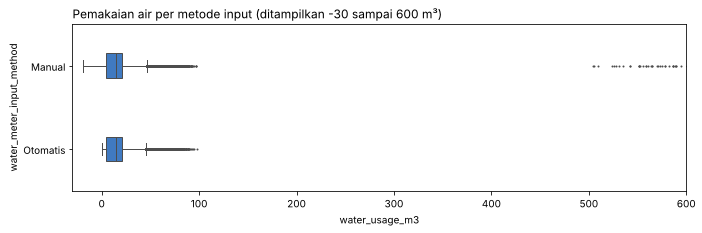

In [ ]:
print("Air negatif per metode input:")
print(billings[air < 0]["water_meter_input_method"].value_counts())
print(f"Air di atas batas wajar ({batas_wajar} m3) per metode input:")
print(billings[air > batas_wajar]["water_meter_input_method"].value_counts())

plt.figure(figsize=(11, 3))
sns.boxplot(data=billings, x="water_usage_m3", y="water_meter_input_method", color=BIRU, width=0.3, fliersize=1)
plt.xlim(-30, 600)
plt.title("Pemakaian air per metode input (ditampilkan -30 sampai 600 m³)", loc="left")
plt.show()

In [ ]:
# Format nomor HP: akhiran ".0" dihapus, lalu panjang dan awalan nomor diperiksa (nomor tidak ditampilkan utuh)
nomor = units["contact_number"].dropna().str.replace(r"\.0$", "", regex=True)
print("Contoh format (disamarkan):", (nomor.head(3).str[:3] + "*******").tolist())
print("Panjang digit              :", sorted(int(x) for x in nomor.str.len().unique()))
print("Seluruhnya angka?          :", nomor.str.isdigit().all())
print("Seluruhnya diawali angka 8?:", nomor.str.startswith("8").all())

Contoh format (disamarkan): ['882*******', '814*******', '854*******']
Panjang digit              : [10]
Seluruhnya angka?          : True
Seluruhnya diawali angka 8?: True



**Insight dan keputusan:**
- Batas atas IQR untuk air (46,35 m³) mencampur pemakaian tinggi yang wajar dengan kesalahan input. Batas wajar diturunkan langsung dari data: di atas batas IQR terdapat **celah kosong antara 97,8 m³ dan 504 m³** (tidak ada satu tagihan pun di antaranya), dan 97,8 m³ juga merupakan pembacaan tertinggi meteran **Otomatis**. Karena itu dipakai **batas wajar 97,8 m³** sebagai aturan *screening*.
- **3.824 invoice** mencatat air negatif dan **3.789 invoice** mencatat air di atas batas wajar; **seluruhnya berasal dari input Manual**.
- Batas ini adalah aturan *screening*, **bukan bukti** bahwa setiap nilai di atasnya salah. Kapasitas unit, kategori komersial/industrial, pergantian meter, dan log meter aktual perlu divalidasi oleh Estate Ops, dan batas final per jenis unit perlu disetujui pemilik proses. Oleh karena itu nilai aslinya **tidak diubah**, hanya ditandai.
- Nomor HP berjumlah 10 digit, seluruhnya angka, dan diawali angka 8. Pola ini menunjukkan **angka 0 di depan hilang** karena pernah disimpan sebagai angka. Validitas format tidak menjamin nomor masih aktif.


## 4.7 Konsistensi Logis

In [ ]:
unpaid = billings["payment_status"] == "Unpaid"
lewat_jatuh_tempo = (unpaid & (billings["due_date"] < TANGGAL_SNAPSHOT)).sum()
print(f"Unpaid yang jatuh temponya sudah lewat per {TANGGAL_SNAPSHOT.date()}: {lewat_jatuh_tempo} dari {unpaid.sum()}")
print("Tanggal jatuh tempo paling akhir pada data :", billings["due_date"].max().date())

# Tanggal bayar sebelum periode tagihan: dicek juga terhadap tanggal serah terima unit
serah_terima = billings["unit_id"].map(units.set_index("unit_id")["handover_date"])
bayar_sebelum_periode = billings["payment_date"] < billings["billing_month"]
print("Tanggal bayar sebelum periode tagihan      :", bayar_sebelum_periode.sum())
print("   di antaranya sebelum serah terima unit  :", (bayar_sebelum_periode & (billings["payment_date"] < serah_terima)).sum())
print("   tanggal bayar paling awal                :", billings.loc[bayar_sebelum_periode, "payment_date"].min().date())

# Denda keterlambatan: pada status apa denda tercatat?
paid_telat = lunas & (billings["payment_date"] > billings["due_date"])
print("Paid terlambat tanpa denda                 :", (paid_telat & (billings["late_fee_penalty"] == 0)).sum(), "dari", paid_telat.sum(), "Paid terlambat")
print("Hari keterlambatan Paid paling lama        :", (billings["payment_date"] - billings["due_date"]).dt.days.max())
display(pd.crosstab(billings["payment_status"], billings["late_fee_penalty"] > 0).rename(columns={False: "tanpa denda", True: "ada denda"}))

# Status invoice yang menerima aksi penagihan dan sinkronisasi respon "Lunas Setelah Kontak"
cek_aksi = actions.merge(billings[["invoice_id", "payment_status"]], on="invoice_id", validate="many_to_one")
print("Status invoice yang ditagih                :", cek_aksi["payment_status"].value_counts().to_dict())
lunas_tidak_sinkron = (cek_aksi["response_status"] == "Lunas Setelah Kontak") & (cek_aksi["payment_status"] != "Paid")
print("Lunas Setelah Kontak tetapi belum Paid      :", lunas_tidak_sinkron.sum())

Unpaid yang jatuh temponya sudah lewat per 2025-01-27: 99405 dari 99405
Tanggal jatuh tempo paling akhir pada data : 2025-01-15
Tanggal bayar sebelum periode tagihan      : 11236
   di antaranya sebelum serah terima unit  : 11236
   tanggal bayar paling awal                : 2015-11-11
Paid terlambat tanpa denda                 : 46656 dari 46656 Paid terlambat
Hari keterlambatan Paid paling lama        : 22.0


late_fee_penalty,tanpa denda,ada denda
payment_status,,
Overdue,80927,118094
Paid,509001,0
Unpaid,96446,2959


Status invoice yang ditagih                : {'Overdue': 126772}
Lunas Setelah Kontak tetapi belum Paid      : 5580



**Insight:**
- Seluruh **99.405** invoice Unpaid telah melewati jatuh tempo per tanggal snapshot, sehingga **tidak ada invoice Unpaid yang belum jatuh tempo**. Unpaid dan Overdue tidak dapat dibedakan berdasarkan jatuh tempo; NPI dihitung dari gabungan keduanya sesuai brief, dan definisi kedua status perlu dikonfirmasi tim Finance.
- **11.236** invoice memiliki **tanggal bayar sebelum periode tagihan**, dan seluruhnya juga sebelum tanggal serah terima unit (paling awal 11 November 2015). Kondisi ini tidak mungkin terjadi, tetapi belum tentu salah ketik tahun; penanda dipertahankan sampai dikonfirmasi.
- **Seluruh 46.656 invoice Paid yang terlambat tidak dikenai denda**, dan tidak ada satu pun invoice Paid yang memiliki denda, sedangkan denda tercatat pada invoice Overdue dan Unpaid. Pola yang konsisten ini mengindikasikan **aturan sistem** (misalnya denda dihapus saat pelunasan atau toleransi keterlambatan hingga 22 hari), sehingga statusnya adalah **kebijakan yang perlu dikonfirmasi**, belum tentu kesalahan.
- Aksi penagihan **hanya tercatat pada invoice Overdue**, dan **5.580** respon "Lunas Setelah Kontak" tidak sinkron dengan status billing.



## 4.8 Ringkasan Temuan & Dampaknya terhadap Hipotesis
| Temuan | Skala | Hipotesis terdampak | Penanganan |
|---|---|---|---|
| Salinan tagihan ganda (invoice 9xxxx, Jun–Sep 2023) | 38.449 | P1, H18, seluruh hipotesis | Ditandai `flag_duplikat_terbit`; dikeluarkan dari perhitungan NPI |
| Pasangan ganda Paid + Paid | 12.568 | H18, Finance | Daftar rekonsiliasi |
| payment_method 9 variasi | 9 → 4 metode | Tujuan 3 | Distandarisasi dengan kamus eksplisit |
| Air negatif / di atas batas wajar (input Manual) | 3.824 / 3.789 | H13, P2, H16 | Ditandai; **komponen air** invoice NPI dipisahkan sebagai nominal yang perlu validasi |
| Nomor HP kehilangan angka 0 | 23.903 nomor | H3 | Ditambah 0 di depan; format divalidasi |
| Tanggal bayar sebelum periode tagihan | 11.236 | P1 | Ditandai; tidak dipakai untuk menghitung keterlambatan |
| Unpaid vs Overdue tidak dibedakan | 99.405 | P1 | NPI = Unpaid + Overdue |
| Paid terlambat tanpa denda | 46.656 | – | Dicatat sebagai kebijakan yang perlu dikonfirmasi |
| Status aksi tidak sinkron; tidak ada Kunjungan Lapangan | 5.580 | H14 | Respon petugas dibaca sebagai sinyal, bukan bukti pembayaran |


## 4.9 Data Cleaning
| Langkah | Penanganan | Alasan |
|---|---|---|
| Salinan data | `copy()` | Data mentah tidak berubah dan tetap dapat dibandingkan |
| Tagihan ganda | Salinan **ditandai** `flag_duplikat_terbit`; analisis memakai invoice utama | Barisnya tetap tersimpan untuk audit dan rekonsiliasi |
| payment_method | 9 variasi → 4 kategori melalui kamus eksplisit, dengan pemeriksaan label yang belum terpetakan | Rekap per metode menjadi benar dan variasi baru langsung terdeteksi |
| Air tidak wajar, tanggal tidak logis | Ditandai (flag), nilai asli **tidak diubah** | Status bayar tetap benar; koreksi menunggu validasi pemilik proses |
| Nominal | Nominal bruto dipisahkan dari komponen air yang perlu validasi | Komponen IPL dan denda pada invoice beranomali air tetap dihitung |
| contact_number | Teks + angka 0 di depan, kolom `punya_kontak` dan `kontak_valid` | Format nomor seluler Indonesia |
| Kolom bantu | `is_npi`, `hari_sejak_jatuh_tempo`, `umur_tunggakan_hari` | Menghitung NPI dan umur tunggakan per tanggal snapshot |
| Gabung tabel | billings utama + units + clusters → `df` dengan `validate="many_to_one"` | Satu tabel analisis tanpa penggandaan baris |

In [ ]:
billings_clean = billings.copy()
units_clean = units.copy()

# 1) Tandai salinan tagihan ganda: invoice pola 9xxxx di dalam pasangan unit-bulan yang sama (bukti di 4.4)
pola_9 = billings_clean["invoice_id"].str[-5:].str.startswith("9")
billings_clean["flag_duplikat_terbit"] = pasangan_ganda & pola_9
billings_clean["alasan_eksklusi"] = np.where(billings_clean["flag_duplikat_terbit"],
                                             "Salinan invoice unit-bulan yang sama (pola 9xxxx)", "")

# 2) Standarisasi metode pembayaran dengan kamus eksplisit
mapping_metode = {
    "BCA Virtual Account": "Virtual Account BCA", "VA BCA": "Virtual Account BCA", "bca va": "Virtual Account BCA",
    "Cash": "Tunai", "KAS": "Tunai",
    "Credit Card": "Kartu Kredit", "cc": "Kartu Kredit",
    "Tokopedia": "Tokopedia", "toped": "Tokopedia",
}
billings_clean["payment_method"] = billings_clean["payment_method"].map(mapping_metode)
tidak_terpetakan = billings["payment_method"].notna() & billings_clean["payment_method"].isna()
print("Label metode yang belum terpetakan:", tidak_terpetakan.sum())       # harus 0; jika tidak, kamus perlu ditambah

print("Invoice ditandai salinan :", billings_clean["flag_duplikat_terbit"].sum())
print("Invoice utama (analisis) :", (~billings_clean["flag_duplikat_terbit"]).sum())
billings_clean["payment_method"].value_counts(dropna=False)

Label metode yang belum terpetakan: 0
Invoice ditandai salinan : 38449
Invoice utama (analisis) : 768978


payment_method
NaN                    298426
Virtual Account BCA    228477
Tunai                  127438
Kartu Kredit            76556
Tokopedia               76530
Name: count, dtype: int64

In [ ]:
# 3) Tandai data tidak wajar (nilai asli tidak diubah)
billings_clean["air_negatif"] = billings_clean["water_usage_m3"] < 0
billings_clean["air_tidak_wajar"] = billings_clean["water_usage_m3"] > batas_wajar
billings_clean["flag_validasi_air"] = billings_clean["air_negatif"] | billings_clean["air_tidak_wajar"]
billings_clean["bayar_sebelum_periode"] = billings_clean["payment_date"] < billings_clean["billing_month"]

# 4) Kolom NPI dan umur tunggakan per TANGGAL_SNAPSHOT
billings_clean["is_npi"] = billings_clean["payment_status"].isin(["Unpaid", "Overdue"]).astype(int)
billings_clean["hari_sejak_jatuh_tempo"] = (TANGGAL_SNAPSHOT - billings_clean["due_date"]).dt.days
sudah_jatuh_tempo = billings_clean["due_date"] <= TANGGAL_SNAPSHOT
billings_clean["umur_tunggakan_hari"] = billings_clean["hari_sejak_jatuh_tempo"].where(
    (billings_clean["is_npi"] == 1) & sudah_jatuh_tempo)              # kosong untuk Paid dan yang belum jatuh tempo

# 5) Nominal: bruto, komponen air yang perlu validasi, dan nominal analisis
billings_clean["komponen_air"] = billings_clean["total_amount"] - billings_clean["ipl_base_fee"] - billings_clean["late_fee_penalty"]
billings_clean["nilai_npi_bruto"] = np.where(billings_clean["is_npi"] == 1, billings_clean["total_amount"], 0)
billings_clean["nilai_npi_perlu_validasi"] = np.where((billings_clean["is_npi"] == 1) & billings_clean["flag_validasi_air"],
                                                      billings_clean["komponen_air"].clip(lower=0), 0)
# Nominal analisis = bruto dikurangi komponen air yang perlu validasi (IPL dan denda tetap dihitung)
billings_clean["nilai_npi"] = billings_clean["nilai_npi_bruto"] - billings_clean["nilai_npi_perlu_validasi"]

# 6) Perbaiki nomor kontak: hapus akhiran ".0", tambahkan 0 di depan, lalu validasi format
nomor = units_clean["contact_number"].str.replace(r"\.0$", "", regex=True)
units_clean["contact_number"] = np.where(nomor.str.startswith("8"), "0" + nomor, nomor)
units_clean["contact_number"] = units_clean["contact_number"].where(nomor.notna())
units_clean["punya_kontak"] = units_clean["contact_number"].notna()
units_clean["kontak_valid"] = units_clean["contact_number"].str.fullmatch(r"08\d{8,11}").fillna(False).astype(bool)

print("Air negatif / tidak wajar / bayar sebelum periode:", billings_clean["air_negatif"].sum(), "/",
      billings_clean["air_tidak_wajar"].sum(), "/", billings_clean["bayar_sebelum_periode"].sum())
print("Unit punya kontak / kontak dengan format valid    :", units_clean["punya_kontak"].sum(), "/", units_clean["kontak_valid"].sum())

Air negatif / tidak wajar / bayar sebelum periode: 3824 / 3789 / 11236
Unit punya kontak / kontak dengan format valid    : 23903 / 23903


In [ ]:
# 7) Gabungkan tabel sesuai relasi ERD; validate memastikan satu invoice hanya cocok dengan satu unit dan satu cluster
assert units_clean["unit_id"].is_unique and clusters["cluster_id"].is_unique, "Key tabel induk tidak unik"
utama = billings_clean[~billings_clean["flag_duplikat_terbit"]]
df = utama.merge(units_clean.drop(columns=["ipl_base_fee"]), on="unit_id", how="left", validate="many_to_one")
df = df.merge(clusters, on="cluster_id", how="left", validate="many_to_one")

# Assertion menjaga grain tabel analisis
assert df["invoice_id"].is_unique, "invoice_id tidak unik"
assert len(df) == len(utama), "Jumlah baris berubah setelah merge"
assert df["unit_id"].notna().all() and df["cluster_id"].notna().all(), "Ada invoice tanpa unit atau cluster"
assert not df.duplicated(subset=["unit_id", "billing_month"]).any(), "Masih ada unit-bulan ganda"
print("Baris df:", len(df), "| kolom:", df.shape[1], "| seluruh assertion lolos")

Baris df: 768978 | kolom: 46 | seluruh assertion lolos



Data analisis `df` berisi **768.978 invoice utama** dengan *grain* satu invoice per unit per bulan, dan seluruh assertion lolos. `ipl_base_fee` dari tabel units tidak ikut digabung karena nilainya sama dengan yang terdapat pada billings. Seluruh 807.427 invoice tetap tersedia di `billings_clean` beserta penanda dan alasan eksklusinya.


## 4.10 Export Data Bersih ke CSV
Tabel yang telah dibersihkan disimpan ke folder `data/` agar dapat dipakai kembali tanpa mengulang cleaning, misalnya untuk dashboard atau notebook lain.

| File | Isi |
|---|---|
| `billings_clean.csv` | **Seluruh** invoice (termasuk salinan) dengan `flag_duplikat_terbit`, `alasan_eksklusi`, metode bayar standar, penanda data tidak wajar, `is_npi`, umur tunggakan, dan kolom nominal |
| `units_clean.csv` | Unit dengan nomor kontak yang telah diperbaiki serta kolom `punya_kontak` dan `kontak_valid` |
| `clusters_clean.csv`, `actions_clean.csv`, `disputes_clean.csv` | Tidak ada perubahan isi (relasi dan nilainya telah bersih); disimpan agar satu set data lengkap |
| `ipl_clean.csv` | Tabel gabungan `df` (invoice utama + units + clusters) yang dipakai untuk analisis |

> File `units_clean.csv` dan `ipl_clean.csv` memuat nomor kontak pemilik. Akses folder `data/` perlu dibatasi pada pihak yang berwenang.

In [ ]:
os.makedirs("data", exist_ok=True)      # membuat folder data apabila belum ada

tabel_bersih = {
    "billings_clean": billings_clean,
    "units_clean": units_clean,
    "clusters_clean": clusters,
    "actions_clean": actions,
    "disputes_clean": disputes,
    "ipl_clean": df,                      # tabel gabungan untuk analisis
}
for nama_file, tabel in tabel_bersih.items():
    path = f"data/{nama_file}.csv"
    tabel.to_csv(path, index=False)       # index=False: nomor baris tidak ikut disimpan
    print(f"{path:28} -> {tabel.shape[0]:>7} baris, {tabel.shape[1]:>2} kolom")

data/billings_clean.csv      ->  807427 baris, 28 kolom
data/units_clean.csv         ->   28881 baris, 13 kolom
data/clusters_clean.csv      ->     111 baris,  8 kolom
data/actions_clean.csv       ->  126772 baris,  7 kolom
data/disputes_clean.csv      ->   23928 baris,  9 kolom
data/ipl_clean.csv           ->  768978 baris, 46 kolom


In [ ]:
# Pemeriksaan ulang: membaca kembali file yang telah disimpan
# contact_number dibaca sebagai teks (str) agar angka 0 di depan tidak hilang kembali
cek = pd.read_csv("data/ipl_clean.csv", dtype={"contact_number": str},
                  parse_dates=["billing_month", "payment_date", "due_date"])
print("Jumlah baris sama dengan df?:", len(cek) == len(df))
print("Jumlah kolom sama dengan df?:", cek.shape[1] == df.shape[1])
print("Nomor kontak diawali 0?     :", cek["contact_number"].dropna().str.startswith("0").all())

Jumlah baris sama dengan df?: True
Jumlah kolom sama dengan df?: True
Nomor kontak diawali 0?     : True


Seluruh tabel bersih tersimpan di folder `data/`. Saat file dibaca kembali, `contact_number` perlu dibaca sebagai teks (`dtype={"contact_number": str}`) agar angka 0 di depan tidak hilang, dan kolom tanggal dibaca dengan `parse_dates` agar langsung bertipe tanggal.

# 5.0 Pengujian Hipotesis
## 5.1 Baseline NPI & Pola per Cohort (P1)
Baseline dihitung pada **invoice utama** (salinan tagihan ganda dikeluarkan). Nominal disajikan berlapis agar basis perhitungannya jelas:
- **Nominal NPI bruto**: `total_amount` seluruh invoice NPI sebagaimana tercatat di sistem.
- **Komponen air yang perlu validasi**: bagian air dari invoice NPI yang pemakaian airnya negatif atau di atas batas wajar.
- **Nominal NPI analisis** (`nilai_npi`): bruto dikurangi komponen air yang perlu validasi. Komponen IPL dan denda pada invoice tersebut **tetap dihitung**, karena keduanya tidak dipengaruhi kesalahan meteran.

Ketiga angka merupakan **nominal tagihan bermasalah**, bukan kerugian permanen (*bad debt*) dan bukan kas yang pasti tertagih.

In [ ]:
npi_awal = billings_clean["is_npi"].mean() * 100            # sebelum salinan tagihan ganda dikeluarkan
npi_total = df["is_npi"].mean() * 100                       # baseline: invoice utama

# Basis nominal analisis: komponen air yang perlu validasi dikeluarkan dari nilai tagihan
df["nilai_tagihan"] = df["total_amount"] - np.where(df["flag_validasi_air"], df["komponen_air"].clip(lower=0), 0)
npi_bruto = df["nilai_npi_bruto"].sum()
npi_perlu_validasi = df["nilai_npi_perlu_validasi"].sum()
nilai_tunggakan = df["nilai_npi"].sum()
npi_nilai = nilai_tunggakan / df["nilai_tagihan"].sum() * 100

print(f"NPI rate sebelum salinan tagihan ganda dikeluarkan : {npi_awal:.2f}%")
jumlah_npi = df["is_npi"].sum()
print(f"NPI rate baseline (jumlah invoice utama)           : {npi_total:.2f}% ({jumlah_npi:,} dari {len(df):,} invoice)")
print(f"NPI rate berdasarkan nilai rupiah                  : {npi_nilai:.2f}%")
print(f"Nominal NPI bruto                                  : Rp{npi_bruto:,.0f}")
print(f"   komponen air yang perlu validasi                : Rp{npi_perlu_validasi:,.0f}")
print(f"Nominal NPI analisis (nilai_npi)                   : Rp{nilai_tunggakan:,.0f}")

NPI rate sebelum salinan tagihan ganda dikeluarkan : 36.96%
NPI rate baseline (jumlah invoice utama)           : 35.44% (272,545 dari 768,978 invoice)
NPI rate berdasarkan nilai rupiah                  : 35.55%
Nominal NPI bruto                                  : Rp224,640,684,500
   komponen air yang perlu validasi                : Rp48,299,962,500
Nominal NPI analisis (nilai_npi)                   : Rp176,340,722,000


**Mengapa dibaca per cohort?** `payment_status` adalah status pada tanggal snapshot. Mengelompokkan NPI berdasarkan `billing_month` menghasilkan **NPI per cohort penerbitan**: dari invoice yang terbit pada bulan X, berapa persen yang **masih** berstatus Unpaid/Overdue pada tanggal snapshot. Angka ini **bukan** NPI yang benar-benar terlihat pada bulan tersebut. Agar cohort lama dan baru sebanding, setiap cohort diperiksa **kematangannya**: cohort dinyatakan matang apabila batas pembayaran paling terlambat yang teramati pada data telah terlewati sebelum tanggal snapshot.

Pembayaran paling terlambat: 22 hari setelah jatuh tempo
Cohort yang belum matang   : ['2024-12']


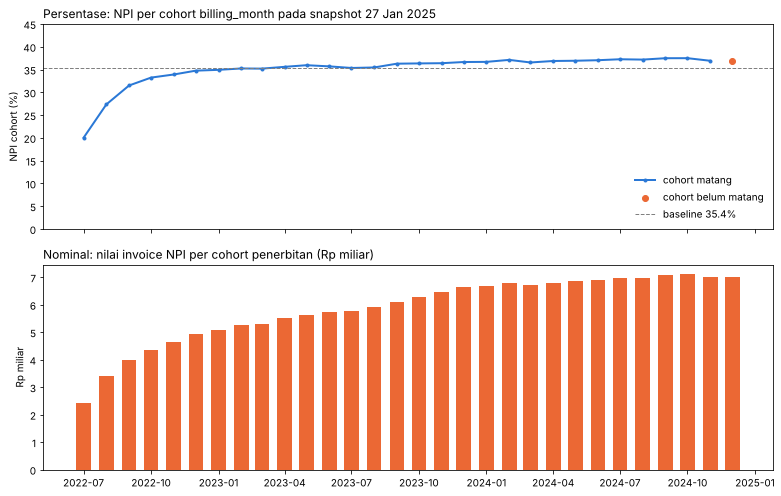

Rata-rata 6 cohort matang pertama = 30.14% | 6 cohort matang terakhir = 37.24%
Cohort pertama (2022-07): NPI 20.03%
Jumlah invoice per cohort: 19,882 (awal) -> 28,881 (akhir)
Nilai invoice NPI per cohort: Rp2.4 miliar (awal) -> Rp6.9 miliar (rata-rata 12 cohort matang terakhir)


,NPI cohort per tahun (%)
billing_month,
2022,30.34
2023,35.79
2024,37.04


In [ ]:
# Batas pembayaran paling terlambat yang teramati (tanggal bayar sebelum periode tagihan tidak dipakai karena tidak logis)
hari_bayar = (df["payment_date"] - df["due_date"]).dt.days[~df["bayar_sebelum_periode"]]
batas_bayar = int(hari_bayar.max())

# Cohort matang: jatuh tempo + batas_bayar sudah terlewati pada tanggal snapshot
df["cohort_matang"] = df["due_date"] + pd.Timedelta(days=batas_bayar) <= TANGGAL_SNAPSHOT
cohort = df.groupby("billing_month").agg(npi_cohort=("is_npi", "mean"), nilai_npi_miliar=("nilai_npi", "sum"),
                                         jumlah_invoice=("invoice_id", "count"), matang=("cohort_matang", "all"))
cohort["npi_cohort"] *= 100
cohort["nilai_npi_miliar"] /= 1e9
print(f"Pembayaran paling terlambat: {batas_bayar} hari setelah jatuh tempo")
print("Cohort yang belum matang   :", cohort.index[~cohort["matang"]].strftime("%Y-%m").tolist())

matang = cohort[cohort["matang"]]
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(matang.index, matang["npi_cohort"], color=BIRU, linewidth=2, marker="o", markersize=3, label="cohort matang")
belum = cohort[~cohort["matang"]]
ax[0].scatter(belum.index, belum["npi_cohort"], color=ORANYE, zorder=3, label="cohort belum matang")
ax[0].axhline(npi_total, color="gray", linestyle="--", linewidth=1, label=f"baseline {npi_total:.1f}%")
ax[0].set_ylim(0, 45)
ax[0].set_title(f"Persentase: NPI per cohort billing_month pada snapshot {TANGGAL_SNAPSHOT:%d %b %Y}", loc="left")
ax[0].set_ylabel("NPI cohort (%)")
ax[0].legend(frameon=False, loc="lower right")

ax[1].bar(cohort.index, cohort["nilai_npi_miliar"], width=20, color=ORANYE)
ax[1].set_title("Nominal: nilai invoice NPI per cohort penerbitan (Rp miliar)", loc="left")
ax[1].set_ylabel("Rp miliar")
plt.tight_layout()
plt.show()

awal, akhir = matang["npi_cohort"].head(6).mean(), matang["npi_cohort"].tail(6).mean()
print(f"Rata-rata 6 cohort matang pertama = {awal:.2f}% | 6 cohort matang terakhir = {akhir:.2f}%")
pertama, terakhir = cohort.iloc[0], cohort.iloc[-1]
nilai_12_terakhir = matang["nilai_npi_miliar"].tail(12).mean()
print(f"Cohort pertama ({cohort.index[0]:%Y-%m}): NPI {pertama.npi_cohort:.2f}%")
print(f"Jumlah invoice per cohort: {pertama.jumlah_invoice:,.0f} (awal) -> {terakhir.jumlah_invoice:,.0f} (akhir)")
print(f"Nilai invoice NPI per cohort: Rp{pertama.nilai_npi_miliar:.1f} miliar (awal) -> Rp{nilai_12_terakhir:.1f} miliar (rata-rata 12 cohort matang terakhir)")
(df.groupby(df["billing_month"].dt.year)["is_npi"].mean() * 100).round(2).to_frame("NPI cohort per tahun (%)")


**Jawaban P1:**
- **Baseline NPI 35,44%** (272.545 dari 768.978 invoice utama, per 27 Januari 2025), di atas perkiraan brief. Berdasarkan nilai rupiah, NPI sebesar 35,55%.
- **Nominal disajikan berlapis:** NPI bruto **Rp224,64 miliar**; Rp48,30 miliar di antaranya adalah komponen air pada invoice beranomali yang perlu validasi; sehingga **nominal NPI analisis Rp176,34 miliar**. Basis ini berbeda dengan angka bruto sebelum cleaning, sehingga keduanya tidak dibandingkan secara langsung.
- **Pola per cohort:** pembayaran paling terlambat yang teramati adalah 22 hari setelah jatuh tempo, sehingga seluruh cohort kecuali Desember 2024 telah matang dan dapat dibandingkan. NPI cohort naik dari **20,03%** (Juli 2022) dan berada pada kisaran 35–38% sejak 2023; rata-rata enam cohort matang pertama **30,14%** dan enam cohort matang terakhir **37,24%**. Angka ini adalah **status per snapshot untuk setiap cohort penerbitan**, bukan NPI yang terlihat pada bulan tersebut.
- **Secara nominal**, nilai invoice NPI per cohort naik dari **Rp2,4 miliar** (Juli 2022) menjadi rata-rata **Rp6,9 miliar** per cohort pada 12 cohort matang terakhir, karena jumlah invoice per bulan bertambah (19.882 → 28.881) sementara persentase NPI tetap tinggi.

**Problem statement SMART dengan baseline:**
> *Head of Township Management perlu menurunkan NPI rate tagihan IPL di 5 township dari **35,44%** (NPI tagihan baru 37,24%) ke level target dalam **2 kuartal ke depan**.* (Target usulan dihitung pada 6.1.2.)


## 5.2 Metode Pengujian Hipotesis
Setiap hipotesis diuji dengan membandingkan **NPI kelompok yang diduga berisiko** dengan **kelompok pembanding**. Karena satu unit memiliki banyak invoice (observasi tidak independen) dan jumlah data sangat besar, p-value saja tidak cukup. Setiap uji melaporkan:

| Ukuran | Fungsi | Catatan |
|---|---|---|
| **Selisih NPI (poin persen)** | Besar perbedaan yang relevan bagi bisnis | Dasar utama penilaian |
| **Interval kepercayaan 95% (bootstrap per unit)** | Ketidakpastian selisih dengan memperhitungkan invoice berulang dari unit yang sama | Unit diambil ulang beserta seluruh tagihannya |
| **Cramér's V** | Besar efek (< 0,1 sangat lemah; 0,1–0,3 lemah; 0,3–0,5 sedang; > 0,5 kuat) | Tidak dipengaruhi jumlah data |
| **p-value chi-square + koreksi Holm** | Uji eksploratif dua kelompok, dikoreksi untuk banyak hipotesis | p-value yang sangat kecil ditulis "< 0,001", bukan 0 |
| **Jumlah invoice dan unit** | Ukuran sampel | Ditampilkan pada setiap tabel |

**Status hasil** (bukan "terbukti", karena data observasional hanya menunjukkan asosiasi):
- **Didukung data – efek besar / sedang / kecil**: batas bawah interval kepercayaan > 0 dan selisih ≥ 20 / 5–20 / 2–5 poin.
- **Selisih tidak relevan secara praktis**: interval kepercayaan > 0 tetapi selisih < 2 poin.
- **Tidak didukung data**: interval kepercayaan mencakup 0 atau arah selisih berlawanan.

Ambang 2, 5, dan 20 poin merupakan **parameter analisis** untuk menerjemahkan selisih menjadi prioritas bisnis, bukan hasil uji statistik. Hipotesis yang didukung data selanjutnya diperiksa terhadap **faktor pengganggu** pada bagian 5.9.

In [ ]:
BATAS_SELISIH = 2          # parameter: selisih minimum (poin) agar dianggap relevan secara praktis
hasil_uji = []             # ringkasan seluruh uji (persentase)
hasil_nominal = []         # perbandingan nominal (jumlah dan rupiah) setiap uji

def npi_per(kolom, data=None):
    # Tabel jumlah invoice, jumlah unit, invoice NPI, NPI rate, dan nominal NPI per kategori
    if data is None:
        data = df
    tabel = data.groupby(kolom).agg(jumlah_tagihan=("is_npi", "count"),
                                    jumlah_unit=("unit_id", "nunique"),
                                    tagihan_npi=("is_npi", "sum"),           # jumlah invoice bermasalah
                                    npi_rate=("is_npi", "mean"),             # persentase
                                    tunggakan_Rp_miliar=("nilai_npi", "sum"))   # nominal NPI analisis
    tabel["npi_rate"] = (tabel["npi_rate"] * 100).round(2)
    tabel["tunggakan_Rp_miliar"] = (tabel["tunggakan_Rp_miliar"] / 1e9).round(2)
    tabel["porsi_tunggakan"] = (tabel["tunggakan_Rp_miliar"] / tabel["tunggakan_Rp_miliar"].sum() * 100).round(1)
    return tabel.sort_values("npi_rate", ascending=False)

def format_p(p):
    # p-value yang sangat kecil ditulis "< 0.001" agar tidak terbaca sebagai probabilitas nol
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def ci_unit(data, kolom, uji, banding, n_boot=300, seed=42):
    # Interval kepercayaan 95% selisih NPI dengan bootstrap per unit (unit diambil ulang beserta seluruh tagihannya)
    sub = data[data[kolom].isin([uji, banding])]
    agg = sub.groupby(["unit_id", kolom]).agg(n=("is_npi", "size"), k=("is_npi", "sum")).unstack(kolom, fill_value=0)
    n_u, n_b = agg[("n", uji)].to_numpy(), agg[("n", banding)].to_numpy()
    k_u, k_b = agg[("k", uji)].to_numpy(), agg[("k", banding)].to_numpy()
    rng = np.random.default_rng(seed)
    sampel = []
    for _ in range(n_boot):
        bobot = rng.multinomial(len(agg), np.full(len(agg), 1 / len(agg)))    # berapa kali setiap unit terambil
        sampel.append((bobot @ k_u) / (bobot @ n_u) - (bobot @ k_b) / (bobot @ n_b))
    return np.percentile(sampel, 2.5) * 100, np.percentile(sampel, 97.5) * 100

def status_bukti(selisih, ci_bawah):
    # Menerjemahkan selisih dan interval kepercayaan menjadi status hasil (lihat tabel metode di atas)
    if ci_bawah <= 0:
        return "Tidak didukung data"
    if selisih >= 20:
        return "Didukung data - efek besar"
    if selisih >= 5:
        return "Didukung data - efek sedang"
    if selisih >= BATAS_SELISIH:
        return "Didukung data - efek kecil"
    return "Selisih tidak relevan secara praktis"

def grafik_npi(tabel, judul):
    # Kiri = persentase (NPI rate), kanan = nominal (nilai NPI); kategori dengan NPI tertinggi berwarna oranye
    tabel = tabel.sort_values("npi_rate")
    warna = [ORANYE if v == tabel["npi_rate"].max() else BIRU for v in tabel["npi_rate"]]
    fig, ax = plt.subplots(1, 2, figsize=(14, 0.5 * len(tabel) + 1.8), sharey=True)

    ax[0].barh(tabel.index.astype(str), tabel["npi_rate"], color=warna)
    ax[0].axvline(npi_total, color="gray", linestyle="--", linewidth=1, label=f"baseline {npi_total:.1f}%")
    for i, v in enumerate(tabel["npi_rate"]):
        ax[0].text(v + 0.5, i, f"{v:.1f}%", va="center")
    ax[0].legend(loc="lower right", frameon=False)
    ax[0].set_xlim(0, tabel["npi_rate"].max() + 12)
    ax[0].set_xlabel("NPI rate (%)")
    ax[0].set_title("Persentase: NPI rate", loc="left")

    ax[1].barh(tabel.index.astype(str), tabel["tunggakan_Rp_miliar"], color=warna)
    for i, (v, p) in enumerate(zip(tabel["tunggakan_Rp_miliar"], tabel["porsi_tunggakan"])):
        ax[1].text(v + tabel["tunggakan_Rp_miliar"].max() * 0.01, i, f"Rp{v:.1f} M ({p:.0f}%)", va="center")
    ax[1].set_xlim(0, tabel["tunggakan_Rp_miliar"].max() * 1.4)
    ax[1].set_xlabel("Nilai NPI (Rp miliar)")
    ax[1].set_title("Nominal: nilai NPI (porsi dari total)", loc="left")

    fig.suptitle(judul, x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    plt.show()

def grafik_dua_dimensi(baris, kolom, judul):
    # Kombinasi dua kolom: kiri = NPI rate (%), kanan = nilai NPI (Rp miliar); dipakai untuk memeriksa faktor pengganggu
    tabel = (pd.crosstab(df[baris], df[kolom], values=df["is_npi"], aggfunc="mean") * 100).round(1)
    nominal = (pd.crosstab(df[baris], df[kolom], values=df["nilai_npi"], aggfunc="sum") / 1e9).round(1)
    warna = [BIRU, ORANYE, ABU][:tabel.shape[1]]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    for a, isi, satuan in [(ax[0], tabel, "NPI rate (%)"), (ax[1], nominal, "Nilai NPI (Rp miliar)")]:
        isi.plot(kind="bar", ax=a, color=warna, rot=0, legend=False)
        for wadah, nama_kolom in zip(a.containers, isi.columns):
            label = ["" if pd.isna(v) else f"{v:.1f}" for v in isi[nama_kolom]]   # label dikosongkan bila tidak ada data
            a.bar_label(wadah, labels=label, fontsize=8)
        a.set_ylabel(satuan)
        a.set_xlabel("")
        a.tick_params(axis="x", labelsize=8)
        a.margins(y=0.12)
    ax[0].set_title("Persentase: NPI rate", loc="left")
    ax[1].set_title("Nominal: nilai NPI", loc="left")
    ax[1].legend(title=kolom, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
    fig.suptitle(judul, x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    plt.show()
    return tabel

def uji_hipotesis(kode, kolom, kelompok_uji, kelompok_pembanding, data=None):
    # Selisih NPI dua kelompok + CI bootstrap per unit + Cramer's V + chi-square, lalu hasilnya disimpan
    if data is None:
        data = df
    tabel = npi_per(kolom, data)
    npi_uji = tabel.loc[kelompok_uji, "npi_rate"]
    npi_banding = tabel.loc[kelompok_pembanding, "npi_rate"]
    selisih = round(npi_uji - npi_banding, 2)

    sub = data[data[kolom].isin([kelompok_uji, kelompok_pembanding])]      # hanya dua kelompok yang dibandingkan
    chi2, p_value = chi2_contingency(pd.crosstab(sub[kolom], sub["is_npi"]))[:2]
    cramer_v = np.sqrt(chi2 / len(sub))
    ci_bawah, ci_atas = ci_unit(data, kolom, kelompok_uji, kelompok_pembanding)
    status = status_bukti(selisih, ci_bawah)

    print(f"{kode}: {kelompok_uji} {npi_uji}% vs {kelompok_pembanding} {npi_banding}%")
    print(f"    selisih = {selisih} poin (CI 95% {ci_bawah:.2f} s.d. {ci_atas:.2f}) | Cramer V = {cramer_v:.3f} | "
          f"p-value {format_p(p_value)} | n = {len(sub):,} invoice, {sub.unit_id.nunique():,} unit | {status}")
    hasil_uji.append([kode, kelompok_uji, kelompok_pembanding, npi_uji, npi_banding, selisih,
                      round(ci_bawah, 2), round(ci_atas, 2), round(cramer_v, 3), p_value, len(sub), status])
    hasil_nominal.append([kode, kelompok_uji, kelompok_pembanding,
                          tabel.loc[kelompok_uji, "tagihan_npi"], npi_uji, tabel.loc[kelompok_uji, "tunggakan_Rp_miliar"],
                          tabel.loc[kelompok_pembanding, "tagihan_npi"], npi_banding,
                          tabel.loc[kelompok_pembanding, "tunggakan_Rp_miliar"], selisih, status])

Fungsi yang dipakai berulang:
- `npi_per(kolom)`: NPI per kategori dalam **persentase** (`npi_rate`) dan **nominal** (`tagihan_npi` = jumlah invoice bermasalah, `tunggakan_Rp_miliar` = nilai NPI analisis, `porsi_tunggakan` = porsinya dari total), beserta jumlah invoice dan unit.
- `ci_unit(...)`: interval kepercayaan 95% selisih NPI dengan bootstrap per unit.
- `uji_hipotesis(...)`: membandingkan dua kelompok, menghitung selisih, interval kepercayaan, Cramér's V, dan p-value, kemudian menyimpan hasilnya ke `hasil_uji` dan `hasil_nominal`.
- `grafik_npi(tabel, judul)` dan `grafik_dua_dimensi(baris, kolom, judul)`: grafik persentase dan nominal; grafik dua dimensi dipakai untuk memeriksa faktor pengganggu.

**Mengapa perlu persentase dan nominal?** Persentase menunjukkan **seberapa berisiko** suatu kelompok, sedangkan nominal menunjukkan **seberapa besar nilainya**. Kelompok dengan NPI tinggi belum tentu menyumbang nominal terbesar apabila jumlah tagihannya sedikit, dan sebaliknya.

## 5.3 Komponen A · Pemilik Unit
### H1 · Unit vacant memiliki NPI lebih tinggi dibandingkan unit yang dihuni

,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
status_hunian,,,,,,
Vacant,185942,7001,108646,58.43,66.10,37.5
Dihuni,583036,21880,163899,28.11,110.24,62.5


H1: Vacant 58.43% vs Dihuni 28.11%
    selisih = 30.32 poin (CI 95% 29.92 s.d. 30.72) | Cramer V = 0.271 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek besar


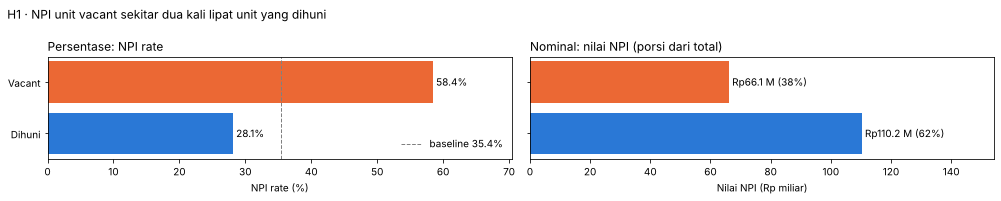

In [ ]:
df["status_hunian"] = df["is_vacant"].map({0: "Dihuni", 1: "Vacant"})
tabel_h1 = npi_per("status_hunian")
display(tabel_h1)
uji_hipotesis("H1", "status_hunian", "Vacant", "Dihuni")
grafik_npi(tabel_h1, "H1 · NPI unit vacant sekitar dua kali lipat unit yang dihuni")


**H1 didukung data dengan efek besar.** NPI unit vacant **58,43%** dibandingkan **28,11%** pada unit dihuni (selisih **+30,32 poin**; CI 95% 29,92–30,72; Cramér's V 0,271). Secara nominal, unit vacant menyumbang **Rp66,10 miliar (37,5%)**, sedangkan unit dihuni **Rp110,24 miliar (62,5%)** karena jumlah invoice-nya sekitar tiga kali lebih banyak. Artinya, **risiko** tertinggi ada pada unit vacant, tetapi **nominal** terbesar tetap berada pada unit dihuni.

### H2 · Pemilik Luar Kota/Luar Negeri memiliki NPI lebih tinggi


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
owner_domicile,,,,,,
Luar Negeri,55745,2134,34610,62.09,26.26,14.9
Luar Kota,207922,7847,97030,46.67,63.13,35.8
Dalam Kota,505311,18900,140905,27.88,86.95,49.3


H2: Luar Kota/Negeri 49.93% vs Dalam Kota 27.88%
    selisih = 22.05 poin (CI 95% 21.61 s.d. 22.52) | Cramer V = 0.219 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek besar


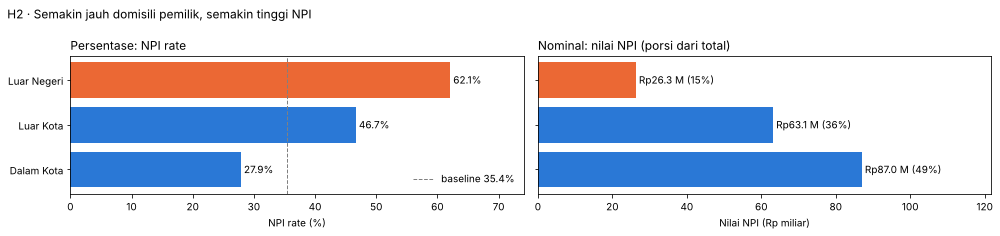

In [ ]:
df["domisili"] = df["owner_domicile"].map({"Dalam Kota": "Dalam Kota", "Luar Kota": "Luar Kota/Negeri",
                                           "Luar Negeri": "Luar Kota/Negeri"})
tabel_h2 = npi_per("owner_domicile")          # kategori asli ditampilkan agar gradasinya terlihat
display(tabel_h2)
uji_hipotesis("H2", "domisili", "Luar Kota/Negeri", "Dalam Kota")
grafik_npi(tabel_h2, "H2 · Semakin jauh domisili pemilik, semakin tinggi NPI")

owner_domicile
Dalam Kota     10.3
Luar Kota      45.3
Luar Negeri    71.0
Name: % invoice unit vacant, dtype: float64

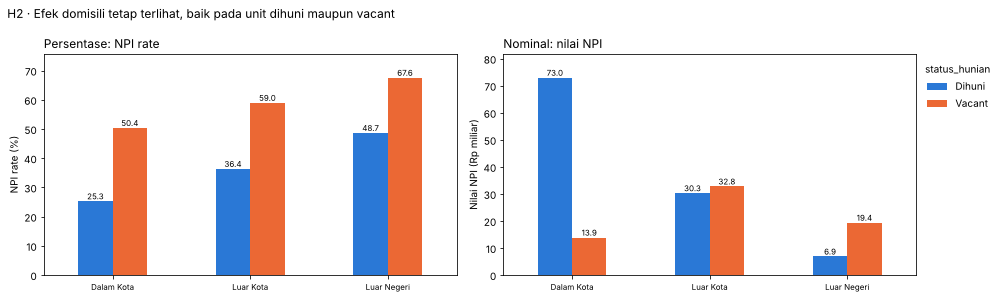

status_hunian,Dihuni,Vacant
owner_domicile,,
Dalam Kota,25.3,50.4
Luar Kota,36.4,59.0
Luar Negeri,48.7,67.6


In [ ]:
# Domisili berkaitan dengan status hunian: apakah efek domisili tetap ada pada unit yang dihuni?
display((df.groupby("owner_domicile")["is_vacant"].mean() * 100).round(1).rename("% invoice unit vacant"))
grafik_dua_dimensi("owner_domicile", "status_hunian", "H2 · Efek domisili tetap terlihat, baik pada unit dihuni maupun vacant")


**H2 didukung data dengan efek besar.** Dalam Kota **27,88%**, Luar Kota **46,67%**, dan Luar Negeri **62,09%** (selisih Luar Kota/Negeri vs Dalam Kota **+22,05 poin**; CI 95% 21,61–22,52). Domisili sangat terkait dengan status hunian (71,0% invoice pemilik Luar Negeri berasal dari unit vacant), tetapi efek domisili tetap terlihat pada unit yang dihuni (25,3% → 36,4% → 48,7%). Kombinasi paling berisiko adalah **vacant + pemilik Luar Negeri (67,6%)**. Pengaruh masing-masing faktor setelah faktor lain disamakan diukur pada bagian 5.9.

### H3 · Unit tanpa kontak / kontak belum terverifikasi memiliki NPI lebih tinggi


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
status_kontak,,,,,,
Tanpa nomor,132291,4978,58522,44.24,39.50,22.4
"Ada nomor, belum terverifikasi",105726,3984,42356,40.06,27.86,15.8
"Ada nomor, terverifikasi",530961,19919,171667,32.33,108.99,61.8


H3: Tanpa nomor 44.24% vs Ada nomor, terverifikasi 32.33%
    selisih = 11.91 poin (CI 95% 11.17 s.d. 12.58) | Cramer V = 0.100 | p-value < 0.001 | n = 663,252 invoice, 24,897 unit | Didukung data - efek sedang


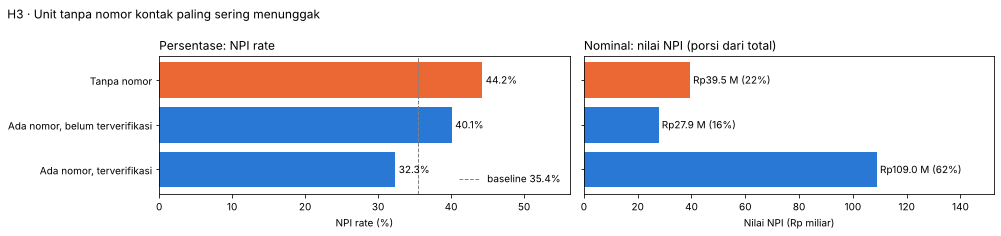

In [ ]:
# Status kontak: tanpa nomor, nomor belum terverifikasi, dan nomor terverifikasi
df["status_kontak"] = np.select([~df["punya_kontak"], df["contact_verified"] == 1],
                                ["Tanpa nomor", "Ada nomor, terverifikasi"], default="Ada nomor, belum terverifikasi")
tabel_h3 = npi_per("status_kontak")
display(tabel_h3)
uji_hipotesis("H3", "status_kontak", "Tanpa nomor", "Ada nomor, terverifikasi")
grafik_npi(tabel_h3, "H3 · Unit tanpa nomor kontak paling sering menunggak")


**H3 didukung data dengan efek sedang (sebelum pengendalian).** Tanpa nomor **44,24%**, nomor belum terverifikasi **40,06%**, dan nomor terverifikasi **32,33%** (selisih tanpa nomor vs terverifikasi **+11,91 poin**; CI 95% 11,17–12,58; Cramér's V 0,100). Bagian 5.9 menguji apakah selisih ini tetap ada setelah status hunian, domisili, dan autodebit disamakan.


## 5.4 Komponen B · Tagihan & Cara Bayar
### H6 · Tagihan tanpa autodebit memiliki NPI lebih tinggi

,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
autodebit,,,,,,
Tanpa autodebit,658728,28879,261598,39.71,169.28,96.0
Autodebit,110250,26977,10947,9.93,7.06,4.0


H6: Tanpa autodebit 39.71% vs Autodebit 9.93%
    selisih = 29.78 poin (CI 95% 29.52 s.d. 30.04) | Cramer V = 0.218 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek besar
Porsi invoice yang memakai autodebit: 14.34%


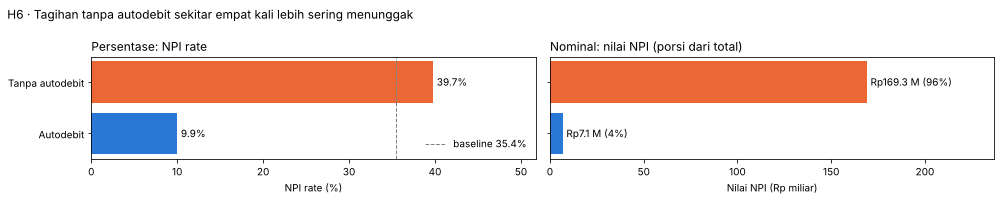

In [ ]:
df["autodebit"] = df["is_autodebit_enrolled"].map({0: "Tanpa autodebit", 1: "Autodebit"})
tabel_h6 = npi_per("autodebit")
display(tabel_h6)
uji_hipotesis("H6", "autodebit", "Tanpa autodebit", "Autodebit")
print(f"Porsi invoice yang memakai autodebit: {df.is_autodebit_enrolled.mean() * 100:.2f}%")
grafik_npi(tabel_h6, "H6 · Tagihan tanpa autodebit sekitar empat kali lebih sering menunggak")

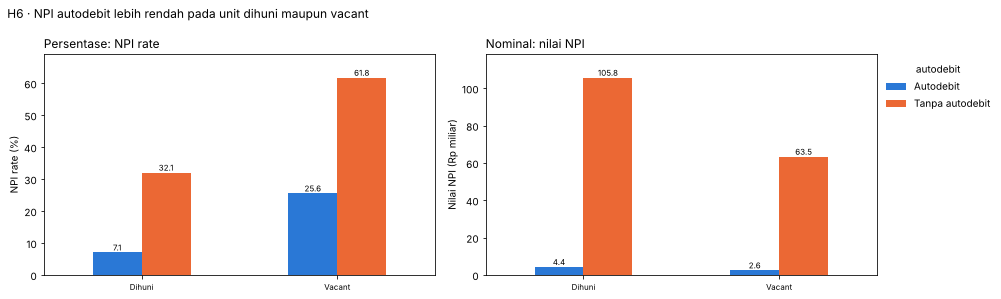

autodebit,Autodebit,Tanpa autodebit
status_hunian,,
Dihuni,7.1,32.1
Vacant,25.6,61.8


In [ ]:
# Apakah efek autodebit tetap ada pada unit vacant maupun dihuni?
grafik_dua_dimensi("status_hunian", "autodebit", "H6 · NPI autodebit lebih rendah pada unit dihuni maupun vacant")


**H6 didukung data dengan efek besar.** Tanpa autodebit **39,71%** dibandingkan autodebit **9,93%** (selisih **+29,78 poin**; CI 95% 29,52–30,04), padahal baru **14,34%** invoice yang memakai autodebit. Efeknya tetap terlihat pada unit vacant (61,8% vs 25,6%) maupun dihuni (32,1% vs 7,1%). Pemilik yang memilih autodebit kemungkinan memang lebih disiplin sejak awal (*self-selection*), sehingga selisih ini adalah **asosiasi**; dampak program autodebit perlu dibuktikan melalui pilot.

### H7 · Tagihan Cetak & Antar Fisik memiliki NPI lebih tinggi dibandingkan Portal Online


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
billing_channel,,,,,,
Cetak & Antar Fisik,201237,26764,82117,40.81,54.43,30.9
SMS Blast,176902,28481,64776,36.62,42.11,23.9
Portal Online App,390839,28566,125652,32.15,79.79,45.3


H7: Cetak & Antar Fisik 40.81% vs Portal Online App 32.15%
    selisih = 8.66 poin (CI 95% 8.31 s.d. 9.05) | Cramer V = 0.086 | p-value < 0.001 | n = 592,076 invoice, 28,873 unit | Didukung data - efek sedang


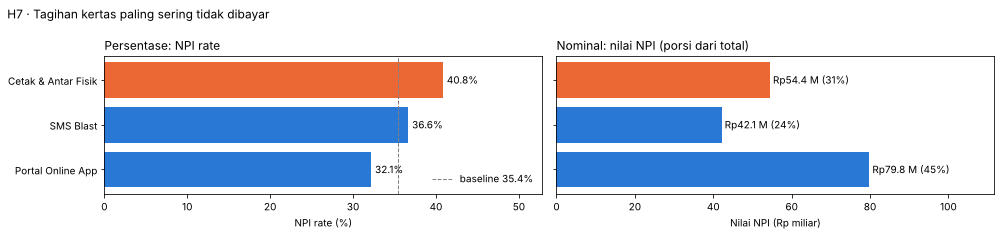

In [ ]:
tabel_h7 = npi_per("billing_channel")
display(tabel_h7)
uji_hipotesis("H7", "billing_channel", "Cetak & Antar Fisik", "Portal Online App")
grafik_npi(tabel_h7, "H7 · Tagihan kertas paling sering tidak dibayar")

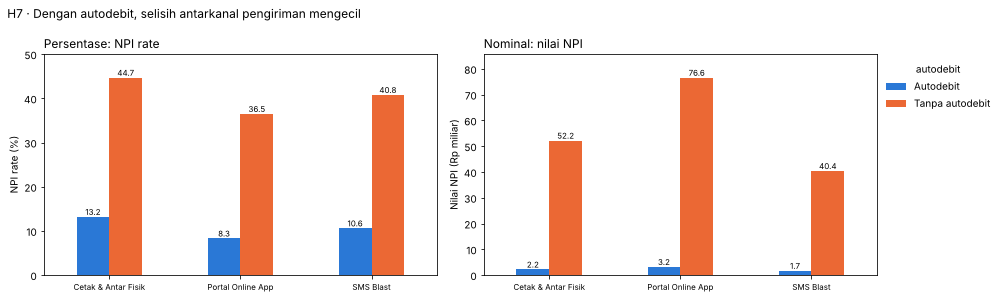

autodebit,Autodebit,Tanpa autodebit
billing_channel,,
Cetak & Antar Fisik,13.2,44.7
Portal Online App,8.3,36.5
SMS Blast,10.6,40.8


In [ ]:
grafik_dua_dimensi("billing_channel", "autodebit", "H7 · Dengan autodebit, selisih antarkanal pengiriman mengecil")


**H7 didukung data dengan efek sedang (sebelum pengendalian).** Cetak & Antar Fisik **40,81%**, SMS Blast **36,62%**, dan Portal Online App **32,15%** (selisih **+8,66 poin**; CI 95% 8,31–9,05). Kanal tagihan terkait dengan tipe pemilik, hunian, dan autodebit: pada invoice autodebit, NPI seluruh kanal turun ke 8,3–13,2%. Karena itu, perpindahan ke portal **tidak dapat diasumsikan** menghasilkan penurunan penuh sebesar 8,66 poin (diuji pada 5.9).

### H8 · Unit dengan tarif IPL tinggi memiliki NPI lebih tinggi
Kelompok tarif ditentukan dari data: tarif **di atas median** tarif seluruh invoice dibandingkan dengan tarif di bawah atau sama dengan median.


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
Rp350.000,317803,11735,110733,34.84,48.82,27.7
Rp500.000,337947,12531,117324,34.72,70.01,39.7
Rp850.000,64077,2588,24977,38.98,24.82,14.1
Rp1.500.000,49151,2027,19511,39.70,32.69,18.5


H8: Tarif tinggi (> Rp500.000) 39.29% vs Tarif standar (<= Rp500.000) 34.78%
    selisih = 4.51 poin (CI 95% 3.83 s.d. 5.23) | Cramer V = 0.033 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek kecil


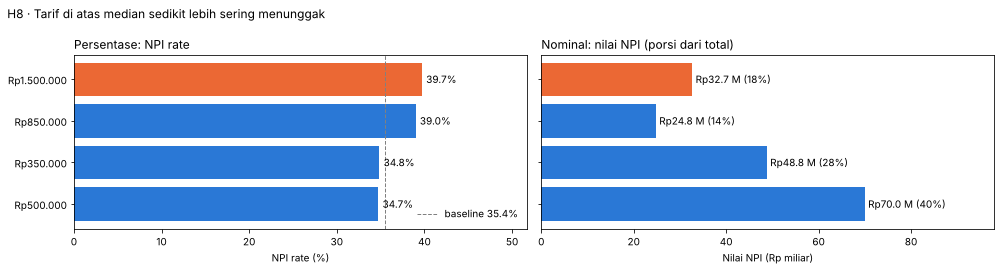

In [ ]:
# Tarif tinggi = tarif di atas median tarif seluruh invoice (ambang diturunkan dari data)
median_tarif = df["ipl_base_fee"].median()
tarif_teks = f"{median_tarif:,.0f}".replace(",", ".")              # format ribuan Indonesia
label_tinggi, label_standar = f"Tarif tinggi (> Rp{tarif_teks})", f"Tarif standar (<= Rp{tarif_teks})"
df["kelompok_tarif"] = np.where(df["ipl_base_fee"] > median_tarif, label_tinggi, label_standar)

tabel_tarif = npi_per("ipl_base_fee").sort_index()
tabel_tarif.index = ["Rp" + f"{x:,.0f}".replace(",", ".") for x in tabel_tarif.index]
display(tabel_tarif)
uji_hipotesis("H8", "kelompok_tarif", label_tinggi, label_standar)
grafik_npi(tabel_tarif, "H8 · Tarif di atas median sedikit lebih sering menunggak")


**H8 didukung data, tetapi efeknya kecil (+4,51 poin).** Tarif Rp850 ribu dan Rp1,5 juta memiliki NPI 38,98–39,70%, dibandingkan 34,72–34,84% pada tarif Rp350–500 ribu (CI 95% 3,83–5,23; Cramér's V 0,033). Kemampuan bayar (*affordability*) baru dapat dievaluasi apabila data pendapatan pemilik tersedia.

### H9 · Tagihan dengan jarak ke jatuh tempo yang pendek memiliki NPI lebih tinggi
Ambang pendek/panjang ditentukan dari **median** jarak `billing_month` ke `due_date`.


Jarak billing_month ke due_date: 32 - 45 hari | median: 39.0 hari


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
kelompok_jatuh_tempo,,,,,,
Pendek (<= 39 hari),384783,28823,136437,35.46,88.15,50.0
Panjang (> 39 hari),384195,28807,136108,35.43,88.19,50.0


H9: Pendek (<= 39 hari) 35.46% vs Panjang (> 39 hari) 35.43%
    selisih = 0.03 poin (CI 95% -0.13 s.d. 0.24) | Cramer V = 0.000 | p-value 0.776 | n = 768,978 invoice, 28,881 unit | Tidak didukung data


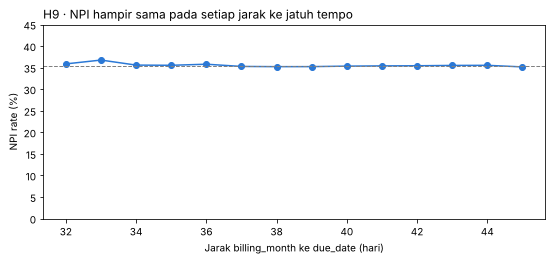

In [ ]:
df["jarak_jatuh_tempo"] = (df["due_date"] - df["billing_month"]).dt.days
median_jarak = df["jarak_jatuh_tempo"].median()                    # ambang pendek/panjang diturunkan dari data
print("Jarak billing_month ke due_date:", df["jarak_jatuh_tempo"].min(), "-", df["jarak_jatuh_tempo"].max(),
      "hari | median:", median_jarak, "hari")

label_pendek, label_panjang = f"Pendek (<= {median_jarak:.0f} hari)", f"Panjang (> {median_jarak:.0f} hari)"
df["kelompok_jatuh_tempo"] = np.where(df["jarak_jatuh_tempo"] <= median_jarak, label_pendek, label_panjang)
display(npi_per("kelompok_jatuh_tempo"))
uji_hipotesis("H9", "kelompok_jatuh_tempo", label_pendek, label_panjang)

npi_per_jarak = df.groupby("jarak_jatuh_tempo")["is_npi"].mean() * 100
plt.figure(figsize=(9, 3.5))
plt.plot(npi_per_jarak.index, npi_per_jarak.values, color=BIRU, marker="o")
plt.axhline(npi_total, color="gray", linestyle="--", linewidth=1)
plt.ylim(0, 45)
plt.title("H9 · NPI hampir sama pada setiap jarak ke jatuh tempo", loc="left")
plt.xlabel("Jarak billing_month ke due_date (hari)")
plt.ylabel("NPI rate (%)")
plt.show()


**H9 tidak didukung data.** Jarak ke jatuh tempo (32–45 hari) tidak membedakan NPI (35,46% vs 35,43%; selisih 0,03 poin; CI 95% −0,13 s.d. 0,24; p-value 0,776). Kesimpulan ini berlaku untuk rentang jarak yang ada pada data (32–45 hari); kebijakan jatuh tempo di luar rentang tersebut tidak dapat dinilai.


## 5.5 Komponen C · Kawasan / Cluster
### H11 · Cluster New Phase memiliki NPI lebih tinggi dibandingkan Established

,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
launch_phase,,,,,,
2021-2023 (New Phase),277368,12494,111129,40.07,72.84,41.3
2018-2020 (Established),491610,16387,161416,32.83,103.50,58.7


H11: 2021-2023 (New Phase) 40.07% vs 2018-2020 (Established) 32.83%
    selisih = 7.24 poin (CI 95% 6.75 s.d. 7.70) | Cramer V = 0.073 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek sedang


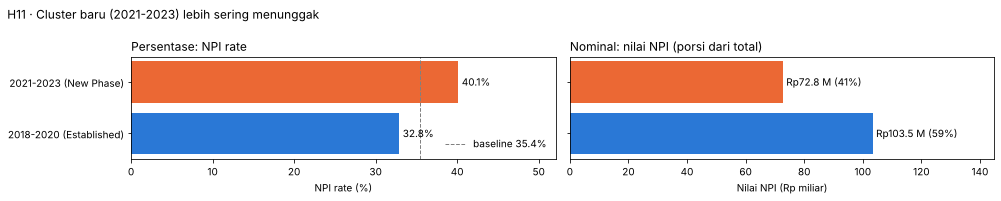

In [ ]:
tabel_h11 = npi_per("launch_phase")
display(tabel_h11)
uji_hipotesis("H11", "launch_phase", "2021-2023 (New Phase)", "2018-2020 (Established)")
grafik_npi(tabel_h11, "H11 · Cluster baru (2021-2023) lebih sering menunggak")

,is_vacant,is_autodebit_enrolled
launch_phase,,
2018-2020 (Established),24.5,14.8
2021-2023 (New Phase),23.5,13.6


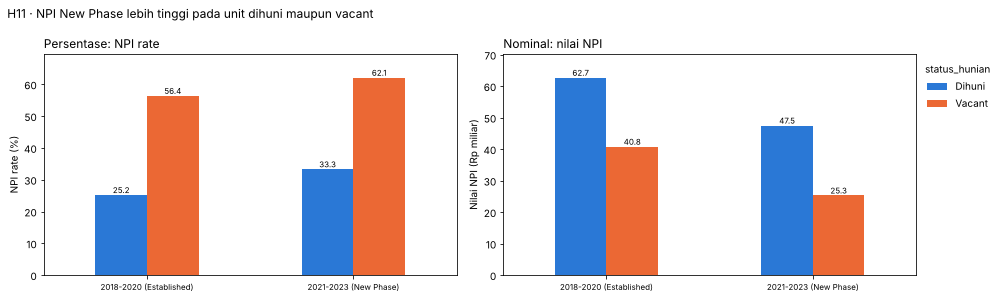

status_hunian,Dihuni,Vacant
launch_phase,,
2018-2020 (Established),25.2,56.4
2021-2023 (New Phase),33.3,62.1


In [ ]:
# Apakah karena cluster baru memiliki lebih banyak unit vacant atau invoice tanpa autodebit?
display((df.groupby("launch_phase")[["is_vacant", "is_autodebit_enrolled"]].mean() * 100).round(1))
grafik_dua_dimensi("launch_phase", "status_hunian", "H11 · NPI New Phase lebih tinggi pada unit dihuni maupun vacant")


**H11 didukung data dengan efek sedang.** New Phase **40,07%** dibandingkan Established **32,83%** (selisih **+7,24 poin**; CI 95% 6,75–7,70). Proporsi invoice unit vacant (23,5% vs 24,5%) dan autodebit (13,6% vs 14,8%) pada kedua fase hampir sama, tetapi NPI New Phase tetap lebih tinggi pada unit dihuni (33,3% vs 25,2%) maupun vacant (62,1% vs 56,4%). Kemungkinan terdapat faktor khas cluster baru yang tidak tercatat pada data, misalnya warga yang belum terbiasa membayar IPL atau tahap serah terima.

### H12 · Cluster yang dikelola dari Regional Hub memiliki NPI lebih tinggi


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
management_office_distance_category,,,,,,
Regional Hub,277191,10588,103610,37.38,68.56,38.9
Onsite,491787,18293,168935,34.35,107.78,61.1


H12: Regional Hub 37.38% vs Onsite 34.35%
    selisih = 3.03 poin (CI 95% 2.51 s.d. 3.49) | Cramer V = 0.030 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek kecil


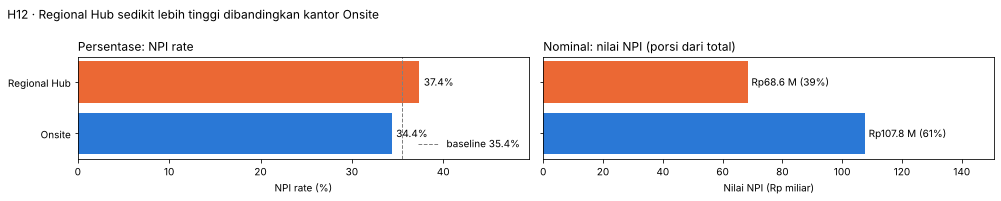

In [ ]:
tabel_h12 = npi_per("management_office_distance_category")
display(tabel_h12)
uji_hipotesis("H12", "management_office_distance_category", "Regional Hub", "Onsite")
grafik_npi(tabel_h12, "H12 · Regional Hub sedikit lebih tinggi dibandingkan kantor Onsite")


**H12 didukung data, tetapi efeknya kecil (+3,03 poin).** Regional Hub **37,38%** dibandingkan Onsite **34,35%** (CI 95% 2,51–3,49). Bagian 5.9 menunjukkan apakah selisih ini dijelaskan oleh faktor lain.

### H13 · Tunggakan terkonsentrasi: ≤ 20% cluster menyumbang ≥ 50% nilai tunggakan
Brief §6 menanyakan apakah kesimpulan pada level township tetap sama pada level yang lebih rinci. Karena itu tunggakan dilihat bertingkat: **township → cluster → unit**. H13 diukur sebagai **metrik konsentrasi** dengan ambang dari rumusan hipotesis (20% cluster dan 50% nilai), bukan sebagai uji signifikansi.


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
township_name,,,,,,
Deltamas,89804,3400,32590,36.29,18.70,10.6
NavaPark,28741,1389,10422,36.26,13.81,7.8
BSD City,227190,8695,82163,36.16,53.91,30.6
Kota Wisata,227433,8317,79417,34.92,52.70,29.9
Grand Wisata,195810,7080,67953,34.70,37.22,21.1


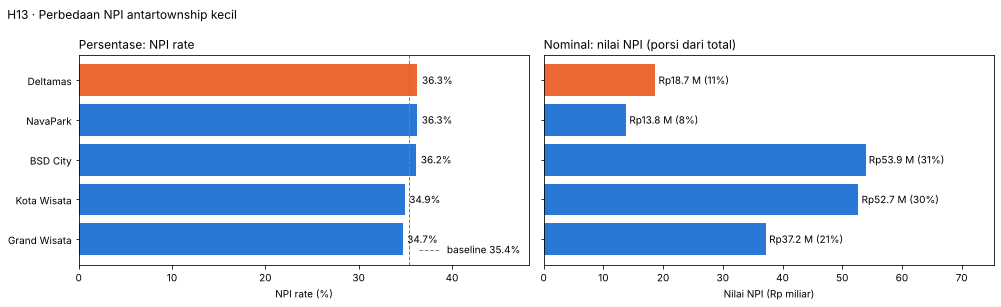

In [ ]:
tabel_township = npi_per("township_name")
display(tabel_township)
grafik_npi(tabel_township, "H13 · Perbedaan NPI antartownship kecil")

In [ ]:
# H13 adalah METRIK KONSENTRASI (bukan uji signifikansi): ambang 20% cluster dan 50% tunggakan berasal dari rumusan hipotesis
tunggak = df[df["is_npi"] == 1]

tunggakan_cluster = tunggak.groupby("cluster_id")["nilai_npi"].sum().sort_values(ascending=False)
kumulatif_cluster = tunggakan_cluster.cumsum() / tunggakan_cluster.sum() * 100
jumlah_cluster = len(tunggakan_cluster)
cluster_50 = (kumulatif_cluster < 50).sum() + 1                       # cluster pertama yang membuat kumulatif >= 50%
porsi_top20_cluster = kumulatif_cluster.iloc[int(jumlah_cluster * 0.2) - 1]

tunggakan_unit = (tunggak.groupby("unit_id")
                  .agg(tagihan_npi=("is_npi", "sum"), nilai_tunggakan=("nilai_npi", "sum"))
                  .sort_values("nilai_tunggakan", ascending=False))
tunggakan_unit["persen_kumulatif"] = tunggakan_unit["nilai_tunggakan"].cumsum() / tunggakan_unit["nilai_tunggakan"].sum() * 100
jumlah_unit = len(units_clean)                                       # denominator: seluruh unit
unit_dengan_npi = len(tunggakan_unit)                                 # unit yang memiliki minimal satu invoice NPI
unit_50 = (tunggakan_unit["persen_kumulatif"] < 50).sum() + 1
porsi_top20_unit = tunggakan_unit["persen_kumulatif"].iloc[int(jumlah_unit * 0.2) - 1]

print(f"Cluster untuk 50% tunggakan: {cluster_50} dari {jumlah_cluster} ({cluster_50 / jumlah_cluster * 100:.1f}%)")
print(f"Porsi 20% cluster teratas  : {porsi_top20_cluster:.1f}%")
print(f"Unit yang memiliki NPI     : {unit_dengan_npi:,} dari {jumlah_unit:,} unit")
print(f"Unit untuk 50% tunggakan   : {unit_50:,} ({unit_50 / jumlah_unit * 100:.1f}% seluruh unit; "
      f"{unit_50 / unit_dengan_npi * 100:.1f}% unit yang memiliki NPI)")
print(f"Porsi 20% unit teratas     : {porsi_top20_unit:.1f}%")

hasil_uji.append(["H13", "20% cluster teratas", "ambang 50% tunggakan", round(porsi_top20_cluster, 2), 50,
                  np.nan, np.nan, np.nan, np.nan, np.nan, len(tunggak),
                  "Tidak didukung data (metrik konsentrasi)"])

Cluster untuk 50% tunggakan: 40 dari 111 (36.0%)
Porsi 20% cluster teratas  : 30.3%
Unit yang memiliki NPI     : 28,120 dari 28,881 unit
Unit untuk 50% tunggakan   : 6,771 (23.4% seluruh unit; 24.1% unit yang memiliki NPI)
Porsi 20% unit teratas     : 45.3%


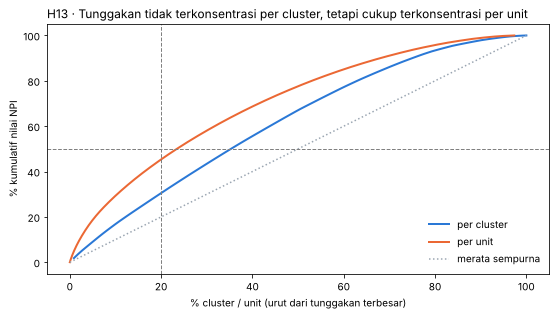

In [ ]:
# Kurva kumulatif: sumbu x = % cluster atau % unit (urut dari tunggakan terbesar)
x_cluster = np.arange(1, jumlah_cluster + 1) / jumlah_cluster * 100
x_unit = np.arange(1, len(tunggakan_unit) + 1) / jumlah_unit * 100

plt.figure(figsize=(9, 4.5))
plt.plot(x_cluster, kumulatif_cluster.values, color=BIRU, linewidth=2, label="per cluster")
plt.plot(x_unit, tunggakan_unit["persen_kumulatif"].values, color=ORANYE, linewidth=2, label="per unit")
plt.plot([0, 100], [0, 100], color=ABU, linestyle=":", label="merata sempurna")
plt.axhline(50, color="gray", linestyle="--", linewidth=1)
plt.axvline(20, color="gray", linestyle="--", linewidth=1)
plt.title("H13 · Tunggakan tidak terkonsentrasi per cluster, tetapi cukup terkonsentrasi per unit", loc="left")
plt.xlabel("% cluster / unit (urut dari tunggakan terbesar)")
plt.ylabel("% kumulatif nilai NPI")
plt.legend(frameon=False)
plt.show()


**H13 tidak didukung data pada level cluster.** 50% nilai NPI tersebar di **40 dari 111 cluster (36,0%)**, dan 20% cluster teratas hanya menyumbang **30,3%**. Perbedaan NPI antartownship juga kecil (34,70–36,29%).

Pada level **unit**, tunggakan lebih terkonsentrasi: dari 28.881 unit, **28.120 unit** memiliki minimal satu invoice NPI, dan **6.771 unit** (23,4% seluruh unit; 24,1% unit yang memiliki NPI) menyumbang 50% nilai NPI; 20% unit teratas menyumbang **45,3%**. Dengan demikian, prioritas penagihan sebaiknya disusun **per unit**, bukan per township atau cluster.


## 5.6 Komponen D · Penagih (Tim Collection)
### H14 · Aksi Telepon lebih sering diikuti pelunasan dibandingkan SMS dan Surat
**Definisi outcome:** unit analisis adalah **invoice**, bukan baris aksi, karena satu invoice dapat menerima beberapa aksi. Aksi dinyatakan berhasil apabila invoice **benar-benar dibayar menurut billing** (`payment_date`) dalam **30 hari setelah aksi pertama** (jendela operasional yang diusulkan). `response_status = "Lunas Setelah Kontak"` adalah sinyal dari log Collection yang harus direkonsiliasi, bukan bukti pembayaran.

In [ ]:
# Ringkas aksi ke tingkat invoice: tanggal dan jenis aksi PERTAMA serta jumlah aksi
aksi_invoice = (actions.sort_values("action_date").groupby("invoice_id")
                .agg(aksi_pertama=("action_date", "first"), jenis_aksi_pertama=("action_type", "first"),
                     jumlah_aksi=("action_id", "count"), respon_terakhir=("response_status", "last")))
aksi_invoice = aksi_invoice.join(df.set_index("invoice_id")[["payment_status", "payment_date"]], how="inner")

# Outcome: dibayar menurut billing, setelah aksi pertama, paling lambat 30 hari kemudian
aksi_invoice["lunas_30_hari"] = ((aksi_invoice["payment_date"] > aksi_invoice["aksi_pertama"]) &
                                 (aksi_invoice["payment_date"] <= aksi_invoice["aksi_pertama"] + pd.Timedelta(days=30)))
print(f"Invoice yang pernah ditagih: {len(aksi_invoice):,} | rata-rata {aksi_invoice.jumlah_aksi.mean():.2f} aksi per invoice")
print("Status billing invoice yang ditagih:", aksi_invoice["payment_status"].value_counts().to_dict())
display(aksi_invoice.groupby("jenis_aksi_pertama").agg(jumlah_invoice=("lunas_30_hari", "size"),
                                                        lunas_30_hari_persen=("lunas_30_hari", "mean")).mul([1, 100]).round(2))

# Uji hanya dijalankan apabila outcome bervariasi; jika tidak, hasilnya dicatat sebagai belum dapat diuji
if aksi_invoice["lunas_30_hari"].nunique() < 2:
    print("H14 BELUM DAPAT DIUJI: tidak ada invoice yang tercatat dibayar setelah aksi (outcome konstan).")
    hasil_uji.append(["H14", "Telepon (invoice lunas <= 30 hari)", "SMS + Surat", np.nan, np.nan, np.nan,
                      np.nan, np.nan, np.nan, np.nan, len(aksi_invoice), "Belum dapat diuji"])

Invoice yang pernah ditagih: 82,806 | rata-rata 1.53 aksi per invoice
Status billing invoice yang ditagih: {'Overdue': 82806}


,jumlah_invoice,lunas_30_hari_persen
jenis_aksi_pertama,,
Telepon,82806,0.0


H14 BELUM DAPAT DIUJI: tidak ada invoice yang tercatat dibayar setelah aksi (outcome konstan).


response_status,Janji Bayar,Lunas Setelah Kontak,Sengketa,Tidak Respon
action_type,,,,
SMS,25.5,5.0,8.8,60.7
Surat,24.4,5.2,7.1,63.2
Telepon,26.4,4.1,9.3,60.1


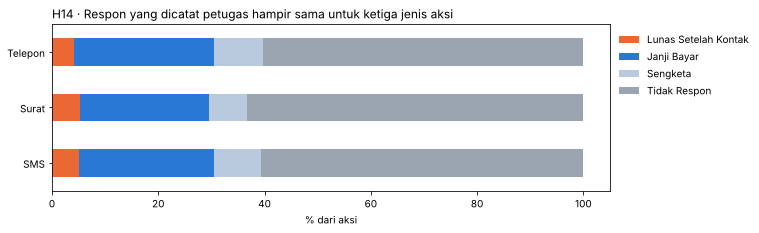

In [ ]:
# Sinyal dari log Collection (bukan bukti pembayaran): distribusi respon per jenis aksi, tingkat AKSI
respon = (pd.crosstab(actions["action_type"], actions["response_status"], normalize="index") * 100).round(1)
display(respon)

ax = respon[["Lunas Setelah Kontak", "Janji Bayar", "Sengketa", "Tidak Respon"]].plot(
    kind="barh", stacked=True, figsize=(10, 3), color=[ORANYE, BIRU, "#b9c9de", ABU])
ax.set_xlabel("% dari aksi")
ax.set_ylabel("")
ax.set_title("H14 · Respon yang dicatat petugas hampir sama untuk ketiga jenis aksi", loc="left")
ax.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.show()

Invoice bermasalah yang pernah ditagih: 30.4%
payment_status
Overdue    42.7
Unpaid      0.0
Name: pernah_ditagih, dtype: float64


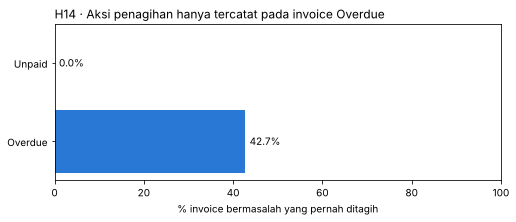

In [ ]:
# Cakupan penagihan: berapa invoice bermasalah yang pernah ditagih?
df["pernah_ditagih"] = df["invoice_id"].isin(actions["invoice_id"])
bermasalah = df[df["is_npi"] == 1]
cakupan = (bermasalah.groupby("payment_status")["pernah_ditagih"].mean() * 100).round(1)
print(f"Invoice bermasalah yang pernah ditagih: {bermasalah.pernah_ditagih.mean() * 100:.1f}%")
print(cakupan)

plt.figure(figsize=(8, 2.8))
plt.barh(cakupan.index, cakupan.values, color=[BIRU, ORANYE])
for i, v in enumerate(cakupan.values):
    plt.text(v + 1, i, f"{v:.1f}%", va="center")
plt.xlim(0, 100)
plt.title("H14 · Aksi penagihan hanya tercatat pada invoice Overdue", loc="left")
plt.xlabel("% invoice bermasalah yang pernah ditagih")
plt.show()


**H14 belum dapat diuji.** Seluruh 82.806 invoice yang pernah ditagih berstatus **Overdue** pada snapshot, sehingga **tidak ada satu pun yang tercatat dibayar setelah aksi** (outcome konstan) dan seluruh aksi pertama tercatat sebagai Telepon. Kondisi ini **bukan bukti bahwa penagihan tidak efektif**, melainkan menunjukkan bahwa log Collection hanya memuat invoice yang masih menunggak dan belum tersinkron dengan pembayaran.

Sebagai **sinyal** dari log petugas (bukan bukti pembayaran), respon ketiga jenis aksi hampir sama: sekitar 60% tidak direspons dan 4–5% tercatat "Lunas Setelah Kontak". Perbedaan Telepon (4,1%) dengan SMS (5,0%) dan Surat (5,2%) bahkan berlawanan dengan arah hipotesis.

**Cakupan:** hanya **30,4%** invoice bermasalah yang pernah ditagih (Overdue 42,7%; Unpaid 0%). Angka Unpaid 0% kemungkinan berasal dari **aturan proses** (aksi hanya dicatat untuk status Overdue), sehingga SOP pencatatan perlu dikonfirmasi sebelum disimpulkan sebagai kegagalan cakupan.


## 5.7 Komponen E · Sistem & Data Tagihan
### H16 · Tagihan dengan input meteran Manual lebih sering tidak dibayar

,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
water_meter_input_method,,,,,,
Otomatis,166244,12449,66719,40.13,43.73,24.8
Manual,602734,28768,205826,34.15,132.61,75.2


H16: Manual 34.15% vs Otomatis 40.13%
    selisih = -5.98 poin (CI 95% -6.36 s.d. -5.58) | Cramer V = 0.051 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Tidak didukung data


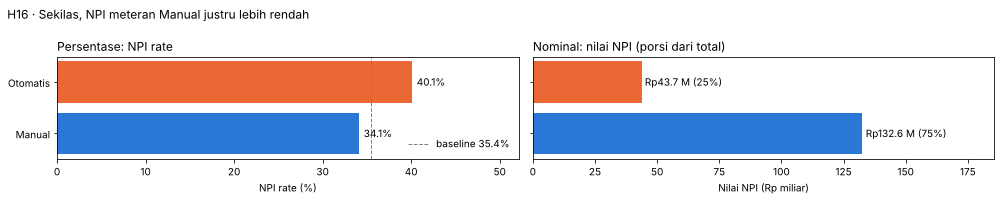

In [ ]:
tabel_h16 = npi_per("water_meter_input_method")
display(tabel_h16)
uji_hipotesis("H16", "water_meter_input_method", "Manual", "Otomatis")
grafik_npi(tabel_h16, "H16 · Sekilas, NPI meteran Manual justru lebih rendah")

water_meter_input_method,Manual,Otomatis
launch_phase,,
2018-2020 (Established),491610,0
2021-2023 (New Phase),111124,166244


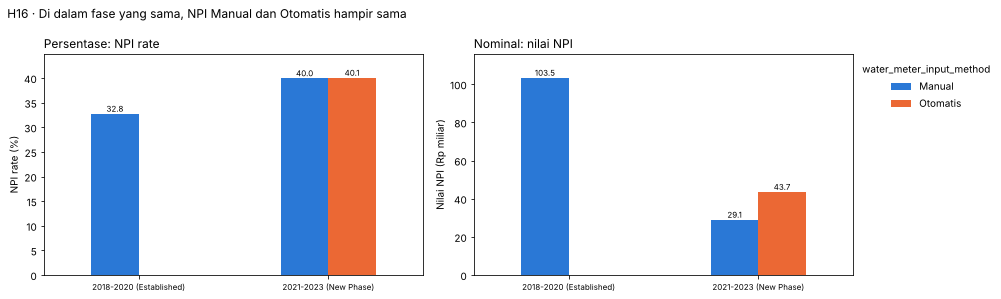

water_meter_input_method,Manual,Otomatis
launch_phase,,
2018-2020 (Established),32.8,NaN
2021-2023 (New Phase),40.0,40.1


,jumlah_tagihan,tagihan_npi,npi_rate
flag_validasi_air,,,
False,761749,270071,35.45
True,7229,2474,34.22


In [ ]:
# Pemeriksaan faktor pengganggu: pada fase cluster mana meteran Otomatis dipasang?
display(pd.crosstab(df["launch_phase"], df["water_meter_input_method"]))
display(grafik_dua_dimensi("launch_phase", "water_meter_input_method", "H16 · Di dalam fase yang sama, NPI Manual dan Otomatis hampir sama"))
display(npi_per("flag_validasi_air")[["jumlah_tagihan", "tagihan_npi", "npi_rate"]])


**H16 tidak didukung data.** Sekilas, NPI input Manual (34,15%) justru lebih rendah dibandingkan Otomatis (40,13%). Namun meteran Otomatis **hanya terpasang di cluster New Phase**, dan di dalam New Phase NPI Manual dan Otomatis hampir sama (40,0% vs 40,1%). Perbedaan awal disebabkan oleh fase cluster (**faktor pengganggu**). Invoice dengan air yang perlu validasi juga tidak memiliki NPI lebih tinggi (34,22% vs 35,45%).

Kesimpulan yang tepat adalah **"tidak ada bukti bahwa input Manual berasosiasi dengan NPI yang lebih tinggi setelah stratifikasi sederhana"**. Hal ini **tidak berarti** meteran air tidak berdampak: kesalahan input meteran tetap memengaruhi validitas nominal tagihan dan memicu sengketa (H17).

### H17 · Tagihan yang disengketakan lebih sering tidak dibayar


Jumlah sengketa seluruhnya          : 23,928
Sengketa pada invoice utama         : 15,556 (8,372 pada salinan tagihan ganda)
Invoice utama yang disengketakan    : 15,556
Nominal koreksi pada invoice utama  : Rp33,719,795,000


,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan
sengketa,,,,,,
Disengketakan,15556,12019,6652,42.76,4.21,2.4
Tidak disengketakan,753422,28881,265893,35.29,172.13,97.6


H17: Disengketakan 42.76% vs Tidak disengketakan 35.29%
    selisih = 7.47 poin (CI 95% 6.68 s.d. 8.21) | Cramer V = 0.022 | p-value < 0.001 | n = 768,978 invoice, 28,881 unit | Didukung data - efek sedang


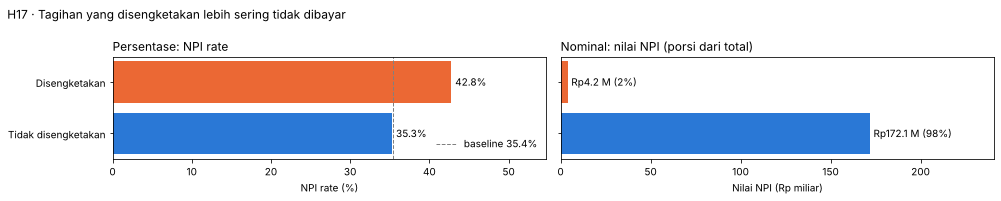

In [ ]:
# Tiga ukuran berbeda: jumlah sengketa, jumlah invoice utama yang terdampak, dan nominal yang dikoreksi
sengketa_utama = disputes[disputes["invoice_id"].isin(df["invoice_id"])]
df["sengketa"] = np.where(df["invoice_id"].isin(disputes["invoice_id"]), "Disengketakan", "Tidak disengketakan")
print(f"Jumlah sengketa seluruhnya          : {len(disputes):,}")
print(f"Sengketa pada invoice utama         : {len(sengketa_utama):,} ({len(disputes) - len(sengketa_utama):,} pada salinan tagihan ganda)")
print(f"Invoice utama yang disengketakan    : {sengketa_utama.invoice_id.nunique():,}")
print(f"Nominal koreksi pada invoice utama  : Rp{sengketa_utama.amount_adjusted.sum():,.0f}")

tabel_h17 = npi_per("sengketa")
display(tabel_h17)
uji_hipotesis("H17", "sengketa", "Disengketakan", "Tidak disengketakan")
grafik_npi(tabel_h17, "H17 · Tagihan yang disengketakan lebih sering tidak dibayar")

resolution_status,Dibatalkan - Tagihan Salah,Diproses,Ditolak - Tagihan Sah,jumlah
dispute_reason,,,,
Duplikat Tagihan,81.9,10.1,7.9,16767
Kesalahan Nominal Lainnya,29.5,14.9,55.6,2871
Pemakaian Air Tidak Wajar,68.8,10.3,20.9,1932
Sudah Bayar Tapi Tercatat Belum Lunas,29.5,16.8,53.7,2358


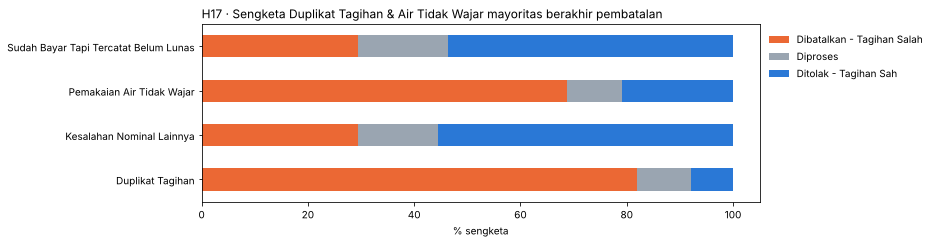

In [ ]:
# Bagaimana hasil sengketa per alasan?
hasil_sengketa = (pd.crosstab(disputes["dispute_reason"], disputes["resolution_status"], normalize="index") * 100).round(1)
display(hasil_sengketa.assign(jumlah=disputes["dispute_reason"].value_counts()))

ax = hasil_sengketa.plot(kind="barh", stacked=True, figsize=(10, 3.2), color=[ORANYE, ABU, BIRU])
ax.set_xlabel("% sengketa")
ax.set_ylabel("")
ax.set_title("H17 · Sengketa Duplikat Tagihan & Air Tidak Wajar mayoritas berakhir pembatalan", loc="left")
ax.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.show()


**H17 didukung data dengan efek sedang, tetapi arah hubungannya belum jelas.** Invoice yang disengketakan memiliki NPI **42,76%** dibandingkan **35,29%** (selisih **+7,47 poin**; CI 95% 6,68–8,21). Sengketa dapat diajukan **karena** invoice sudah bermasalah, sehingga hubungannya dapat berjalan dua arah.

Tiga ukuran perlu dibedakan: **23.928 sengketa** seluruhnya; **15.556 sengketa pada invoice utama** (8.372 lainnya diajukan pada salinan tagihan ganda); dan **nominal koreksi Rp33,72 miliar** pada invoice utama. Porsi nominal NPI invoice yang disengketakan hanya **Rp4,21 miliar (2,4%)**, sehingga masalah ini lebih tepat ditangani melalui perbaikan sistem daripada penagihan. Sengketa **Duplikat Tagihan** (81,9% dibatalkan) dan **Pemakaian Air Tidak Wajar** (68,8%) mayoritas berakhir pembatalan, sehingga sebagian keluhan warga berasal dari kesalahan sistem.

### H18 · Tagihan ganda membuat NPI terlihat lebih tinggi
H18 disajikan sebagai **rekonsiliasi sebelum/sesudah** penerapan aturan duplikasi, bukan sebagai uji kausal atau perbandingan dua kelompok.


,jumlah_invoice,invoice_npi,npi_rate (%),nominal_npi_bruto (Rp miliar)
Sebelum aturan duplikasi (raw),807427,298426,36.96,246.40
Salinan yang dikeluarkan,38449,25881,NaN,21.76
Sesudah aturan duplikasi,768978,272545,35.44,224.64


Pasangan Paid + Paid (indikasi pembayaran ganda): 12,568 | Rp11.07 miliar
Sengketa Duplikat Tagihan: 16,767 | diajukan pada salinan: 8,372


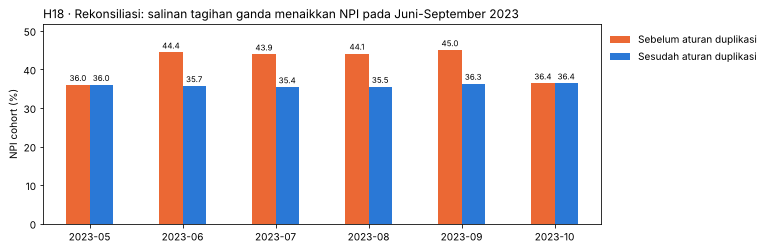

In [ ]:
# H18 disajikan sebagai REKONSILIASI sebelum/sesudah aturan duplikasi, bukan uji kausal
salinan = billings_clean[billings_clean["flag_duplikat_terbit"]]
salinan_npi = salinan[salinan["is_npi"] == 1]
rekonsiliasi = pd.DataFrame({
    "jumlah_invoice": [len(billings_clean), len(salinan), len(df)],
    "invoice_npi": [billings_clean["is_npi"].sum(), salinan["is_npi"].sum(), df["is_npi"].sum()],
    "npi_rate (%)": [npi_awal, np.nan, npi_total],
    "nominal_npi_bruto (Rp miliar)": [billings_clean["nilai_npi_bruto"].sum() / 1e9, salinan["nilai_npi_bruto"].sum() / 1e9,
                                      df["nilai_npi_bruto"].sum() / 1e9],
}, index=["Sebelum aturan duplikasi (raw)", "Salinan yang dikeluarkan", "Sesudah aturan duplikasi"]).round(2)
display(rekonsiliasi)

# Pasangan yang KEDUANYA Paid: indikasi pembayaran ganda yang perlu dicocokkan dengan mutasi bank
paid_ganda = kombinasi_status[kombinasi_status == "Paid + Paid"].index
nominal_paid_ganda = ganda.groupby(kunci)["total_amount"].first().loc[paid_ganda].sum()
sengketa_dup = disputes[disputes["dispute_reason"] == "Duplikat Tagihan"]
print(f"Pasangan Paid + Paid (indikasi pembayaran ganda): {len(paid_ganda):,} | Rp{nominal_paid_ganda / 1e9:,.2f} miliar")
pada_salinan = sengketa_dup["invoice_id"].isin(salinan["invoice_id"]).sum()
print(f"Sengketa Duplikat Tagihan: {len(sengketa_dup):,} | diajukan pada salinan: {pada_salinan:,}")
hasil_uji.append(["H18", "Sebelum aturan duplikasi", "Sesudah aturan duplikasi", round(npi_awal, 2), round(npi_total, 2),
                  round(npi_awal - npi_total, 2), np.nan, np.nan, np.nan, np.nan, len(billings_clean), "Rekonsiliasi (bukan uji)"])

# NPI per cohort sebelum dan sesudah salinan dikeluarkan pada bulan sekitar periode tagihan ganda
sebelum = billings_clean.groupby(billings_clean["billing_month"].dt.strftime("%Y-%m"))["is_npi"].mean() * 100
sesudah = df.groupby(df["billing_month"].dt.strftime("%Y-%m"))["is_npi"].mean() * 100
bulan = ["2023-05", "2023-06", "2023-07", "2023-08", "2023-09", "2023-10"]
banding = pd.DataFrame({"Sebelum aturan duplikasi": sebelum[bulan], "Sesudah aturan duplikasi": sesudah[bulan]}).round(1)

ax = banding.plot(kind="bar", figsize=(10, 3.6), color=[ORANYE, BIRU], rot=0)
for wadah in ax.containers:
    ax.bar_label(wadah, fmt="%.1f", fontsize=8, padding=2)
ax.set_ylabel("NPI cohort (%)")
ax.set_xlabel("")
ax.margins(y=0.15)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("H18 · Rekonsiliasi: salinan tagihan ganda menaikkan NPI pada Juni-September 2023", loc="left")
plt.show()


**Hasil rekonsiliasi H18.** Penerapan aturan duplikasi menurunkan NPI agregat dari **36,96%** menjadi **35,44%** (−1,52 poin). Salinan yang dikeluarkan berjumlah **38.449 invoice**, **25.881** di antaranya berstatus NPI dengan nominal bruto **Rp21,76 miliar**, yaitu nominal tagihan yang tercatat ganda dan tidak mewakili kewajiban tambahan. Dampak terbesarnya ada pada **kepercayaan warga dan rekonsiliasi keuangan**: **8.372** sengketa "Duplikat Tagihan" diajukan pada salinan, dan **12.568 pasangan Paid + Paid (±Rp11,07 miliar)** menunjukkan indikasi pembayaran ganda yang harus dicocokkan dengan mutasi bank sebelum diputuskan pengembalian dana atau kreditnya.


## 5.8 Ringkasan Pengujian Hipotesis
p-value disesuaikan dengan **koreksi Holm** karena banyak hipotesis diuji sekaligus. H13, H14, dan H18 tidak memiliki p-value karena masing-masing berupa metrik konsentrasi, uji yang tidak dapat dijalankan, dan rekonsiliasi.

In [ ]:
ringkasan = pd.DataFrame(hasil_uji, columns=["kode", "kelompok_uji", "pembanding", "nilai_uji", "nilai_pembanding",
                                              "selisih_poin", "ci_bawah", "ci_atas", "cramer_v", "p_value", "n_invoice", "status"])

# Koreksi Holm: p-value terkecil dikali m, berikutnya dikali (m - 1), dan seterusnya, lalu dibuat tidak menurun
ada_p = ringkasan["p_value"].notna()
p = ringkasan.loc[ada_p, "p_value"].to_numpy()
urut = np.argsort(p)
p_holm = np.empty_like(p)
p_holm[urut] = np.minimum(np.maximum.accumulate((len(p) - np.arange(len(p))) * p[urut]), 1)
ringkasan.loc[ada_p, "p_holm"] = p_holm
ringkasan["p_holm"] = ringkasan["p_holm"].map(lambda x: "-" if pd.isna(x) else format_p(x))
ringkasan["p_value"] = ringkasan["p_value"].map(lambda x: "-" if pd.isna(x) else format_p(x))

ringkasan = ringkasan.sort_values("selisih_poin", ascending=False).reset_index(drop=True)
ringkasan

,kode,kelompok_uji,pembanding,nilai_uji,nilai_pembanding,selisih_poin,ci_bawah,ci_atas,cramer_v,p_value,n_invoice,status,p_holm
0,H1,Vacant,Dihuni,58.43,28.11,30.32,29.92,30.72,0.271,< 0.001,768978,Didukung data - efek besar,< 0.001
1,H6,Tanpa autodebit,Autodebit,39.71,9.93,29.78,29.52,30.04,0.218,< 0.001,768978,Didukung data - efek besar,< 0.001
2,H2,Luar Kota/Negeri,Dalam Kota,49.93,27.88,22.05,21.61,22.52,0.219,< 0.001,768978,Didukung data - efek besar,< 0.001
3,H3,Tanpa nomor,"Ada nomor, terverifikasi",44.24,32.33,11.91,11.17,12.58,0.100,< 0.001,663252,Didukung data - efek sedang,< 0.001
4,H7,Cetak & Antar Fisik,Portal Online App,40.81,32.15,8.66,8.31,9.05,0.086,< 0.001,592076,Didukung data - efek sedang,< 0.001
5,H17,Disengketakan,Tidak disengketakan,42.76,35.29,7.47,6.68,8.21,0.022,< 0.001,768978,Didukung data - efek sedang,< 0.001
6,H11,2021-2023 (New Phase),2018-2020 (Established),40.07,32.83,7.24,6.75,7.70,0.073,< 0.001,768978,Didukung data - efek sedang,< 0.001
7,H8,Tarif tinggi (> Rp500.000),Tarif standar (<= Rp500.000),39.29,34.78,4.51,3.83,5.23,0.033,< 0.001,768978,Didukung data - efek kecil,< 0.001
8,H12,Regional Hub,Onsite,37.38,34.35,3.03,2.51,3.49,0.030,< 0.001,768978,Didukung data - efek kecil,< 0.001
9,H18,Sebelum aturan duplikasi,Sesudah aturan duplikasi,36.96,35.44,1.52,NaN,NaN,NaN,-,807427,Rekonsiliasi (bukan uji),-


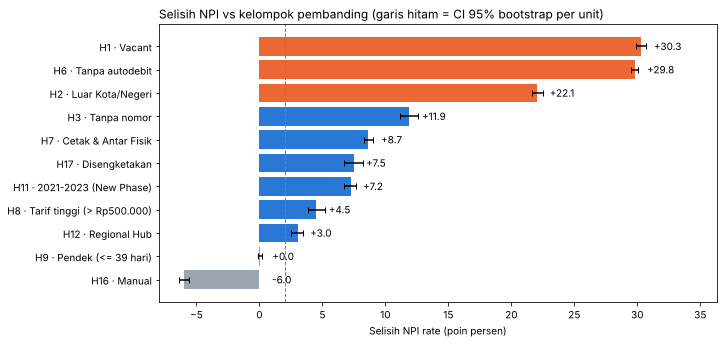

In [ ]:
# Peringkat selisih NPI beserta interval kepercayaan (hanya hipotesis yang diuji dengan dua kelompok)
grafik = ringkasan[ringkasan["ci_bawah"].notna()].sort_values("selisih_poin")
warna = [ORANYE if s >= 20 else (BIRU if s >= BATAS_SELISIH else ABU) for s in grafik["selisih_poin"]]
label = grafik["kode"] + " · " + grafik["kelompok_uji"]
galat = [grafik["selisih_poin"] - grafik["ci_bawah"], grafik["ci_atas"] - grafik["selisih_poin"]]

plt.figure(figsize=(10, 5))
plt.barh(label, grafik["selisih_poin"], color=warna, xerr=galat, ecolor="black", capsize=3)
plt.axvline(BATAS_SELISIH, color="gray", linestyle="--", linewidth=1)
for i, v in enumerate(grafik["selisih_poin"]):
    plt.text(max(v, 0) + 1, i, f"+{v:.1f}" if v >= 0 else f"{v:.1f}", va="center")
plt.title("Selisih NPI vs kelompok pembanding (garis hitam = CI 95% bootstrap per unit)", loc="left")
plt.xlabel("Selisih NPI rate (poin persen)")
plt.xlim(min(grafik["selisih_poin"].min() - 2, -2), grafik["selisih_poin"].max() + 6)
plt.show()


| Status | Hipotesis | Arti |
|---|---|---|
| **Didukung data – efek besar (≥ 20 poin)** | H1 vacant, H6 tanpa autodebit, H2 domisili jauh | Kandidat utama dasar rekomendasi |
| **Didukung data – efek sedang (5–20 poin)** | H3 kontak, H7 cetak fisik, H17 sengketa, H11 New Phase | Pendukung; diperiksa terhadap faktor pengganggu (5.9) |
| **Didukung data – efek kecil (2–5 poin)** | H8 tarif tinggi, H12 Regional Hub | Dicatat, bukan prioritas |
| **Rekonsiliasi** | H18 tagihan ganda (−1,52 poin) | Temuan kualitas billing, bukan penyebab tunggakan |
| **Tidak didukung data** | H9 jatuh tempo, H16 meteran Manual, H13 konsentrasi cluster | Tidak dijadikan dasar keputusan |
| **Belum dapat diuji** | H14 jenis aksi penagihan | Memerlukan bukti pembayaran hasil aksi |

Seluruh hipotesis yang didukung data tetap signifikan setelah **koreksi Holm**, dan interval kepercayaan bootstrap per unit tidak mencakup nol. Namun, signifikansi tidak sama dengan besar manfaat bisnis: keputusan didasarkan pada selisih poin, besar efek, dan nominal.


### Perbandingan Nominal dan Persentase Hipotesis yang Didukung Data
Tabel berikut menambahkan **nominal** untuk setiap hipotesis yang didukung data: jumlah invoice bermasalah (`tagihan_npi`) dan nilai NPI analisis (Rp miliar), baik untuk kelompok uji maupun pembanding. H18 tidak dimasukkan karena merupakan rekonsiliasi sebelum/sesudah, bukan perbandingan dua kelompok yang setara.

In [ ]:
nominal = pd.DataFrame(hasil_nominal, columns=["kode", "kelompok_uji", "pembanding",
                                               "tagihan_npi_uji", "npi_uji (%)", "tunggakan_uji (Rp M)",
                                               "tagihan_npi_pembanding", "npi_pembanding (%)", "tunggakan_pembanding (Rp M)",
                                               "selisih (poin)", "status"])
didukung = nominal[nominal["status"].str.startswith("Didukung")].copy()
didukung["porsi_tunggakan_uji (%)"] = (didukung["tunggakan_uji (Rp M)"] / (nilai_tunggakan / 1e9) * 100).round(1)
didukung = didukung.sort_values("selisih (poin)", ascending=False).reset_index(drop=True)
display(didukung.drop(columns="status"))

,kode,kelompok_uji,pembanding,tagihan_npi_uji,npi_uji (%),tunggakan_uji (Rp M),tagihan_npi_pembanding,npi_pembanding (%),tunggakan_pembanding (Rp M),selisih (poin),porsi_tunggakan_uji (%)
0,H1,Vacant,Dihuni,108646,58.43,66.10,163899,28.11,110.24,30.32,37.5
1,H6,Tanpa autodebit,Autodebit,261598,39.71,169.28,10947,9.93,7.06,29.78,96.0
2,H2,Luar Kota/Negeri,Dalam Kota,131640,49.93,89.39,140905,27.88,86.95,22.05,50.7
3,H3,Tanpa nomor,"Ada nomor, terverifikasi",58522,44.24,39.50,171667,32.33,108.99,11.91,22.4
4,H7,Cetak & Antar Fisik,Portal Online App,82117,40.81,54.43,125652,32.15,79.79,8.66,30.9
5,H17,Disengketakan,Tidak disengketakan,6652,42.76,4.21,265893,35.29,172.13,7.47,2.4
6,H11,2021-2023 (New Phase),2018-2020 (Established),111129,40.07,72.84,161416,32.83,103.50,7.24,41.3
7,H8,Tarif tinggi (> Rp500.000),Tarif standar (<= Rp500.000),44488,39.29,57.51,228057,34.78,118.83,4.51,32.6
8,H12,Regional Hub,Onsite,103610,37.38,68.56,168935,34.35,107.78,3.03,38.9


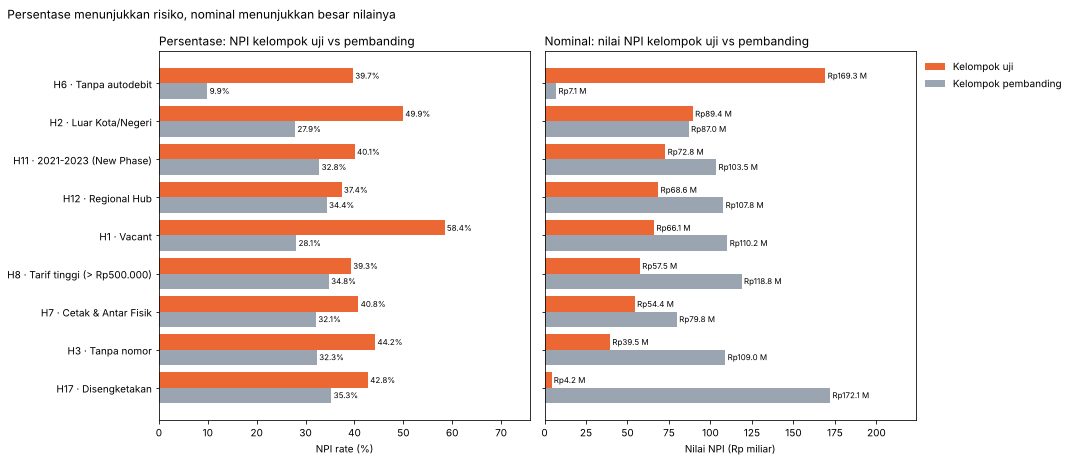

In [ ]:
# Grafik: kiri = persentase, kanan = nominal
grafik_nominal = didukung.sort_values("tunggakan_uji (Rp M)")
label = grafik_nominal["kode"] + " · " + grafik_nominal["kelompok_uji"]
posisi = np.arange(len(grafik_nominal))

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
pengaturan = [(ax[0], "npi_uji (%)", "npi_pembanding (%)", "NPI rate (%)", "{:.1f}%"),
              (ax[1], "tunggakan_uji (Rp M)", "tunggakan_pembanding (Rp M)", "Nilai NPI (Rp miliar)", "Rp{:.1f} M")]
for a, kolom_uji, kolom_banding, satuan, format_label in pengaturan:
    a.barh(posisi + 0.2, grafik_nominal[kolom_uji], height=0.4, color=ORANYE, label="Kelompok uji")
    a.barh(posisi - 0.2, grafik_nominal[kolom_banding], height=0.4, color=ABU, label="Kelompok pembanding")
    for i, (u, b) in enumerate(zip(grafik_nominal[kolom_uji], grafik_nominal[kolom_banding])):
        a.text(u, i + 0.2, " " + format_label.format(u), va="center", fontsize=8)
        a.text(b, i - 0.2, " " + format_label.format(b), va="center", fontsize=8)
    a.set_xlim(0, max(grafik_nominal[kolom_uji].max(), grafik_nominal[kolom_banding].max()) * 1.3)
    a.set_xlabel(satuan)
ax[0].set_yticks(posisi)
ax[0].set_yticklabels(label)
ax[0].set_title("Persentase: NPI kelompok uji vs pembanding", loc="left")
ax[1].set_title("Nominal: nilai NPI kelompok uji vs pembanding", loc="left")
ax[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Persentase menunjukkan risiko, nominal menunjukkan besar nilainya", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()


**Insight perbandingan nominal dan persentase:**
- **Urutan prioritas berubah apabila dilihat dari nominal.** Dari sisi persentase, unit vacant (H1) paling berisiko (**58,43%**). Dari sisi nominal, **invoice tanpa autodebit (H6)** jauh paling besar: **Rp169,28 miliar atau 96,0%** dari nilai NPI analisis, karena 85,7% invoice belum memakai autodebit. H6 merupakan satu-satunya hipotesis yang besar pada **kedua** ukuran.
- **H1 vacant:** NPI dua kali lipat, tetapi nominalnya **Rp66,10 miliar (37,5%)**; unit dihuni justru menyumbang **Rp110,24 miliar**. Penagihan tidak cukup hanya berfokus pada unit vacant.
- **H2 pemilik jauh:** **Rp89,39 miliar (50,7%)**, sedikit lebih besar daripada pemilik Dalam Kota (Rp86,95 miliar), padahal jumlah invoice-nya jauh lebih sedikit.
- **H11 New Phase (Rp72,84 M), H12 Regional Hub (Rp68,56 M), H8 tarif tinggi (Rp57,51 M), dan H7 cetak fisik (Rp54,43 M):** nominalnya besar karena kelompoknya besar, tetapi selisih persentasenya kecil–sedang. Bagian nominal yang benar-benar terkait dengan faktor tersebut jauh lebih kecil daripada angka nominalnya.
- **H3 tanpa nomor:** **Rp39,50 miliar (22,4%)**, cukup besar untuk program verifikasi kontak.
- **H17 sengketa:** persentasenya tinggi (42,76%), tetapi nominalnya hanya **Rp4,21 miliar (2,4%)**.

Catatan: kolom porsi **tidak dapat dijumlahkan** antarhipotesis karena kelompoknya tumpang tindih (satu invoice dapat sekaligus vacant, milik pemilik jauh, dan tanpa autodebit). Untuk H3 dan H7, pembandingnya hanya satu kategori, sehingga nominal uji + pembanding tidak sama dengan total.


## 5.9 Pengendalian Faktor Pengganggu
Beberapa faktor saling berkaitan (misalnya pemilik luar kota lebih sering memiliki unit vacant). Untuk memeriksa apakah setiap faktor tetap berasosiasi dengan NPI setelah faktor lain disamakan, dihitung **selisih terkendali**: selisih NPI dihitung **di dalam setiap kombinasi faktor lain (strata)**, kemudian dirata-ratakan dengan bobot jumlah invoice pada strata tersebut. Apabila selisih terkendali jauh lebih kecil daripada selisih awal, sebagian besar selisih awal dijelaskan oleh faktor lain.

In [ ]:
# Faktor biner (1 = kelompok yang diduga berisiko)
faktor = {
    "H1 Vacant": df["is_vacant"] == 1,
    "H2 Pemilik luar kota/negeri": df["owner_domicile"] != "Dalam Kota",
    "H3 Kontak belum terverifikasi/kosong": df["status_kontak"] != "Ada nomor, terverifikasi",
    "H6 Tanpa autodebit": df["is_autodebit_enrolled"] == 0,
    "H7 Cetak & Antar Fisik": df["billing_channel"] == "Cetak & Antar Fisik",
    "H11 Cluster New Phase": df["launch_phase"] == "2021-2023 (New Phase)",
    "H12 Regional Hub": df["management_office_distance_category"] == "Regional Hub",
}
data_faktor = pd.DataFrame(faktor).astype(int)
data_faktor["is_npi"] = df["is_npi"].to_numpy()

def selisih_terkendali(nama):
    # Selisih NPI di dalam setiap strata faktor lain, dirata-ratakan dengan bobot jumlah invoice
    pengendali = [f for f in faktor if f != nama]
    t = data_faktor.groupby(pengendali + [nama])["is_npi"].agg(["mean", "size"]).unstack(nama).dropna()
    beda = t[("mean", 1)] - t[("mean", 0)]
    bobot = t[("size", 1)] + t[("size", 0)]
    return (beda * bobot).sum() / bobot.sum() * 100

kendali = pd.DataFrame({
    "selisih_awal (poin)": [(data_faktor.loc[data_faktor[f] == 1, "is_npi"].mean()
                             - data_faktor.loc[data_faktor[f] == 0, "is_npi"].mean()) * 100 for f in faktor],
    "selisih_terkendali (poin)": [selisih_terkendali(f) for f in faktor],
}, index=list(faktor)).round(2)
kendali["porsi_tersisa (%)"] = (kendali["selisih_terkendali (poin)"] / kendali["selisih_awal (poin)"] * 100).round(0)
kendali.sort_values("selisih_terkendali (poin)", ascending=False)

,selisih_awal (poin),selisih_terkendali (poin),porsi_tersisa (%)
H6 Tanpa autodebit,29.78,26.59,89.0
H1 Vacant,30.32,23.28,77.0
H2 Pemilik luar kota/negeri,22.04,10.14,46.0
H11 Cluster New Phase,7.23,7.00,97.0
H12 Regional Hub,3.03,0.34,11.0
H3 Kontak belum terverifikasi/kosong,10.05,0.24,2.0
H7 Cetak & Antar Fisik,7.26,-0.02,-0.0



**Insight pengendalian faktor pengganggu:**
- **Faktor yang tetap kuat:** tanpa autodebit (**+26,59 poin**, 89% selisih awal tersisa), vacant (**+23,28 poin**, 77%), dan cluster New Phase (**+7,00 poin**, 97%). Ketiganya berasosiasi dengan NPI secara mandiri.
- **Pemilik luar kota/negeri** tetap berasosiasi (**+10,14 poin**), tetapi lebih dari separuh selisih awalnya (22,04 poin) dijelaskan oleh faktor lain, terutama status vacant.
- **Kontak, kanal cetak fisik, dan Regional Hub hampir hilang** setelah dikendalikan (+0,24; −0,02; +0,34 poin). Selisih awal ketiganya terutama mencerminkan komposisi pemilik: unit tanpa kontak dan penerima tagihan kertas lebih sering vacant, milik pemilik jauh, atau tidak autodebit.
- **Implikasi keputusan:** dasar prioritas risiko adalah **autodebit, status vacant, domisili, dan fase cluster**. Verifikasi kontak tetap penting sebagai **prasyarat keterjangkauan** bagi tim Collection, tetapi tidak dapat diharapkan menurunkan NPI dengan sendirinya. Hal yang sama berlaku untuk perpindahan kanal tagihan.
- Selisih terkendali tetap merupakan asosiasi; faktor yang tidak tercatat (misalnya kemampuan bayar) masih dapat berpengaruh.


# 6.0 EDA Sesuai Stakeholder
Hipotesis yang didukung data pada Tahap 5 didalami lebih lanjut sesuai kebutuhan setiap stakeholder (1.2).

## 6.1 Head of Township Management: profil risiko dan target NPI
### 6.1.1 Skor risiko gabungan
Skor 0–4 disusun dari empat faktor yang **tetap berasosiasi dengan NPI setelah faktor lain dikendalikan** (bagian 5.9): **vacant (H1)**, **pemilik luar kota/negeri (H2)**, **tanpa autodebit (H6)**, dan **cluster New Phase (H11)**. Status kontak tidak dimasukkan karena selisihnya hampir hilang setelah dikendalikan; kontak tetap dipakai sebagai syarat **keterjangkauan** pada daftar kerja Collection (6.2.2).

Setiap faktor diberi **bobot sama** (1 poin) agar skor mudah dijelaskan kepada petugas dan tidak bergantung pada model yang belum tervalidasi. Skor ini bersifat **heuristik**, bukan model prediktif; konsistensinya diuji pada dua periode yang berbeda.

,jumlah_tagihan,jumlah_unit,tagihan_npi,npi_rate,tunggakan_Rp_miliar,porsi_tunggakan,persen_tagihan
skor_risiko,,,,,,,
0,52037,9589,2566,4.93,1.61,0.9,6.8
1,277447,20244,65563,23.63,41.74,23.7,36.1
2,254315,16344,95384,37.51,62.31,35.3,33.1
3,141088,7488,79446,56.31,51.46,29.2,18.3
4,44091,2191,29586,67.10,19.22,10.9,5.7


Invoice skor 3-4: 24.1% invoice, nilai NPI Rp70.7 miliar (40.1%)


,Cohort 2022-2023,Cohort 2024
skor_risiko,,
0,4.8,5.0
1,23.1,24.4
2,36.9,38.2
3,56.1,56.6
4,66.1,68.0


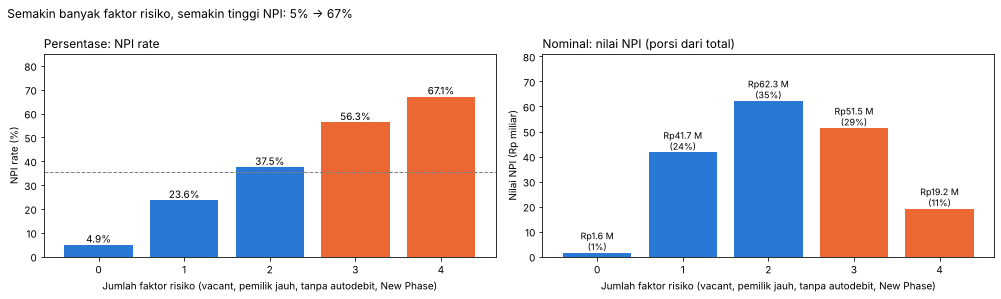

In [ ]:
df["skor_risiko"] = ((df["is_vacant"] == 1).astype(int)
                     + (df["owner_domicile"] != "Dalam Kota").astype(int)
                     + (df["is_autodebit_enrolled"] == 0).astype(int)
                     + (df["launch_phase"] == "2021-2023 (New Phase)").astype(int))

tabel_skor = npi_per("skor_risiko").sort_index()
tabel_skor["persen_tagihan"] = (tabel_skor["jumlah_tagihan"] / len(df) * 100).round(1)
display(tabel_skor)

skor_tinggi = df["skor_risiko"] >= 3
nilai_skor_tinggi = df.loc[skor_tinggi, "nilai_npi"].sum()
print(f"Invoice skor 3-4: {skor_tinggi.mean() * 100:.1f}% invoice, nilai NPI Rp{nilai_skor_tinggi / 1e9:,.1f} miliar "
      f"({nilai_skor_tinggi / nilai_tunggakan * 100:.1f}%)")

# Uji konsistensi pada dua periode: cohort matang 2022-2023 vs cohort matang 2024
periode = np.where(df["billing_month"].dt.year <= 2023, "Cohort 2022-2023", "Cohort 2024")
konsistensi_skor = (df[df["cohort_matang"]].groupby([periode[df["cohort_matang"]], "skor_risiko"])["is_npi"].mean()
                    .unstack(0) * 100).round(1)
display(konsistensi_skor)

warna = [ORANYE if i >= 3 else BIRU for i in tabel_skor.index]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(tabel_skor.index.astype(str), tabel_skor["npi_rate"], color=warna)
for i, v in enumerate(tabel_skor["npi_rate"]):
    ax[0].text(i, v + 1, f"{v:.1f}%", ha="center")
ax[0].axhline(npi_total, color="gray", linestyle="--", linewidth=1)
ax[0].set_ylim(0, 85)
ax[0].set_title("Persentase: NPI rate", loc="left")
ax[0].set_ylabel("NPI rate (%)")

ax[1].bar(tabel_skor.index.astype(str), tabel_skor["tunggakan_Rp_miliar"], color=warna)
for i, (v, p) in enumerate(zip(tabel_skor["tunggakan_Rp_miliar"], tabel_skor["porsi_tunggakan"])):
    ax[1].text(i, v + 1, f"Rp{v:.1f} M\n({p:.0f}%)", ha="center", fontsize=9)
ax[1].set_ylim(0, tabel_skor["tunggakan_Rp_miliar"].max() * 1.3)
ax[1].set_title("Nominal: nilai NPI (porsi dari total)", loc="left")
ax[1].set_ylabel("Nilai NPI (Rp miliar)")
for a in ax:
    a.set_xlabel("Jumlah faktor risiko (vacant, pemilik jauh, tanpa autodebit, New Phase)")
npi_skor_0, npi_skor_4 = tabel_skor["npi_rate"].iloc[0], tabel_skor["npi_rate"].iloc[-1]
fig.suptitle(f"Semakin banyak faktor risiko, semakin tinggi NPI: {npi_skor_0:.0f}% -> {npi_skor_4:.0f}%",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()


NPI naik bertahap dari **4,93%** (tanpa faktor risiko) sampai **67,10%** (keempat faktor). Pola ini **konsisten pada dua periode** (cohort matang 2022–2023 dan 2024 memberikan NPI per skor yang hampir sama), sehingga skor tidak hanya berlaku pada satu periode. Invoice dengan skor 3–4 mencakup **24,1%** invoice, tetapi menyumbang **Rp70,7 miliar (40,1%)** nilai NPI. Secara nominal, **skor 2** menyumbang nilai terbesar (**Rp62,31 miliar; 35,3%**) karena jumlah invoice-nya banyak. Skor tinggi dipakai untuk menentukan **urutan** penanganan, sedangkan invoice skor rendah ditangani melalui program massal seperti autodebit.


### 6.1.2 Simulasi target NPI: program autodebit
Autodebit adalah faktor dengan selisih terbesar yang paling mudah ditindaklanjuti. Simulasi disusun dengan prinsip berikut:
- **Populasi sasaran = unit**, bukan invoice historis: unit yang **tidak autodebit pada bulan tagihan terakhirnya** (*eligible accounts*). Sebagian unit (`PORSI_BERALIH`) dipilih acak sebagai unit yang beralih ke autodebit.
- **Periode dasar = enam cohort matang terakhir**, sehingga hasilnya berupa NPI tagihan baru per bulan.
- **Besar efek = selisih terkendali** (5.9), bukan selisih mentah, karena sebagian selisih mentah dijelaskan faktor lain dan pemilik yang memilih autodebit kemungkinan memang lebih disiplin (*self-selection*).
- **Tiga tingkat keberhasilan** (25%, 50%, 100% dari efek terkendali yang benar-benar terjadi). Skenario 100% adalah batas atas.
- Hasil rupiah disebut **nominal NPI yang berpotensi dicegah**, bukan kas tambahan, sampai terbukti melalui pilot. Biaya insentif, biaya kanal, dan kapasitas tim belum tersedia sehingga manfaat bersih belum dapat dihitung.

Periode dasar: 2024-06 s.d. 2024-11 | 28,548 invoice/bulan | NPI 37.24%
Unit eligible: 24,754 | unit yang diasumsikan beralih: 6,188 (5,288 invoice/bulan)
Adopsi autodebit unit saat ini: 14.3% -> 35.7% apabila program berjalan
Efek autodebit yang dipakai: selisih terkendali 26.59 poin (selisih mentah 29.78 poin)


,npi_sesudah (%),penurunan (poin),invoice_dicegah_per_bulan,nominal_dicegah_per_bulan (Rp miliar)
tingkat,,,,
konservatif,36.01,1.23,351.51,0.23
dasar,34.78,2.46,703.02,0.46
optimistis,32.32,4.93,1406.03,0.93


Agar NPI tagihan baru kembali ke 30.14% (rata-rata 6 cohort matang pertama) pada skenario dasar, diperlukan 72% unit eligible beralih ke autodebit


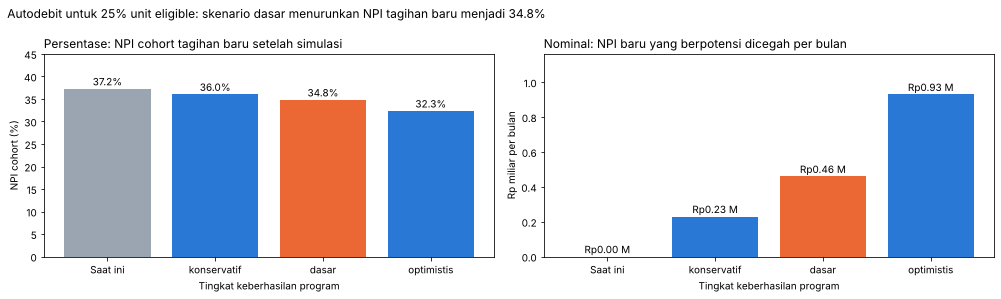

In [ ]:
# PARAMETER ANALISIS (asumsi, bukan angka dari data)
PORSI_BERALIH = 0.25                                              # porsi unit eligible yang diasumsikan beralih ke autodebit
TINGKAT_BERHASIL = {"konservatif": 0.25, "dasar": 0.50, "optimistis": 1.00}

# Periode dasar: enam cohort matang terakhir
bulan_dasar = cohort[cohort["matang"]].index[-6:]
dasar = df[df["billing_month"].isin(bulan_dasar)]
jumlah_bulan = len(bulan_dasar)
npi_dasar = dasar["is_npi"].mean() * 100

# Unit eligible: tidak autodebit pada bulan tagihan terakhirnya
autodebit_terakhir = df.sort_values("billing_month").groupby("unit_id")["is_autodebit_enrolled"].last()
unit_eligible = autodebit_terakhir[autodebit_terakhir == 0].index.to_series()
unit_beralih = unit_eligible.sample(frac=PORSI_BERALIH, random_state=42)
sasaran = dasar["unit_id"].isin(unit_beralih) & (dasar["is_autodebit_enrolled"] == 0)

efek_autodebit = kendali.loc["H6 Tanpa autodebit", "selisih_terkendali (poin)"] / 100      # dari bagian 5.9
rata_nominal_npi = dasar.loc[dasar["is_npi"] == 1, "nilai_npi"].mean()                       # rata-rata nominal per invoice NPI

hasil_simulasi = []
for label, tingkat in TINGKAT_BERHASIL.items():
    dicegah = tingkat * efek_autodebit * sasaran.sum()           # jumlah invoice NPI yang berpotensi dicegah (periode dasar)
    turun = dicegah / len(dasar) * 100
    hasil_simulasi.append({"tingkat": label, "npi_sesudah (%)": npi_dasar - turun, "penurunan (poin)": turun,
                           "invoice_dicegah_per_bulan": dicegah / jumlah_bulan,
                           "nominal_dicegah_per_bulan (Rp miliar)": dicegah * rata_nominal_npi / jumlah_bulan / 1e9})
simulasi = pd.DataFrame(hasil_simulasi).set_index("tingkat").round(2)

print(f"Periode dasar: {bulan_dasar[0]:%Y-%m} s.d. {bulan_dasar[-1]:%Y-%m} | {len(dasar) / jumlah_bulan:,.0f} invoice/bulan | NPI {npi_dasar:.2f}%")
print(f"Unit eligible: {len(unit_eligible):,} | unit yang diasumsikan beralih: {len(unit_beralih):,} "
      f"({sasaran.sum() / jumlah_bulan:,.0f} invoice/bulan)")
print(f"Adopsi autodebit unit saat ini: {(autodebit_terakhir == 1).mean() * 100:.1f}% -> "
      f"{((autodebit_terakhir == 1).sum() + len(unit_beralih)) / len(autodebit_terakhir) * 100:.1f}% apabila program berjalan")
efek_mentah = kendali.loc["H6 Tanpa autodebit", "selisih_awal (poin)"]
print(f"Efek autodebit yang dipakai: selisih terkendali {efek_autodebit * 100:.2f} poin (selisih mentah {efek_mentah:.2f} poin)")
display(simulasi)

target_npi = simulasi.loc["dasar", "npi_sesudah (%)"]          # target usulan = hasil skenario dasar

# Pembanding ambisius dari data: porsi unit yang harus beralih agar NPI tagihan baru kembali ke level 6 cohort matang pertama
penurunan_per_porsi = simulasi.loc["dasar", "penurunan (poin)"] / PORSI_BERALIH
porsi_dibutuhkan = (npi_dasar - awal) / penurunan_per_porsi
print(f"Agar NPI tagihan baru kembali ke {awal:.2f}% (rata-rata 6 cohort matang pertama) pada skenario dasar, "
      f"diperlukan {porsi_dibutuhkan:.0%} unit eligible beralih ke autodebit")
label = ["Saat ini"] + list(simulasi.index)
nilai = [npi_dasar] + list(simulasi["npi_sesudah (%)"])
nominal_dicegah = [0] + list(simulasi["nominal_dicegah_per_bulan (Rp miliar)"])
warna = [ABU, BIRU, ORANYE, BIRU]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(label, nilai, color=warna)
for i, v in enumerate(nilai):
    ax[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax[0].set_ylim(0, 45)
ax[0].set_title("Persentase: NPI cohort tagihan baru setelah simulasi", loc="left")
ax[0].set_ylabel("NPI cohort (%)")
ax[1].bar(label, nominal_dicegah, color=warna)
for i, v in enumerate(nominal_dicegah):
    ax[1].text(i, v + 0.02, f"Rp{v:.2f} M", ha="center")
ax[1].set_ylim(0, max(nominal_dicegah) * 1.25)
ax[1].set_title("Nominal: NPI baru yang berpotensi dicegah per bulan", loc="left")
ax[1].set_ylabel("Rp miliar per bulan")
for a in ax:
    a.set_xlabel("Tingkat keberhasilan program")
fig.suptitle(f"Autodebit untuk {PORSI_BERALIH:.0%} unit eligible: skenario dasar menurunkan NPI tagihan baru menjadi {target_npi:.1f}%",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()


**Hasil simulasi:**
- Pada periode dasar (Juni–November 2024; 28.548 invoice per bulan), NPI tagihan baru sebesar **37,24%**. Terdapat **24.754 unit eligible**; apabila 25% di antaranya (6.188 unit) beralih ke autodebit, adopsi unit naik dari **14,3% menjadi 35,7%**.
- Dengan efek terkendali 26,59 poin, NPI tagihan baru turun **1,23 poin** (konservatif), **2,46 poin** (dasar), atau **4,93 poin** (optimistis), dengan nominal NPI baru yang berpotensi dicegah **Rp0,23–0,93 miliar per bulan** (skenario dasar **Rp0,46 miliar per bulan**).
- **Target usulan:** NPI tagihan baru **≤ 34,8%** pada akhir kuartal kedua (skenario dasar), dengan rentang 36,0% (konservatif) hingga 32,3% (optimistis). Target ini berstatus **usulan** dan perlu disetujui manajemen setelah pilot serta validasi biaya dan kapasitas.
- Mengembalikan NPI tagihan baru ke level awal (30,14%) hanya melalui autodebit memerlukan sekitar **72% unit eligible** beralih pada skenario dasar. Target di bawah 30% karenanya **tidak realistis** apabila hanya mengandalkan autodebit dalam dua kuartal.

**Problem statement SMART final:**
> *Head of Township Management perlu menurunkan NPI tagihan IPL baru di 5 township Sinarmas Land dari **37,24%** menjadi **≤ 34,8%** (usulan, skenario dasar) dalam **2 kuartal ke depan**, dengan memprioritaskan program autodebit untuk unit yang belum autodebit serta penagihan terfokus pada unit vacant milik pemilik yang jauh. Baseline NPI seluruh invoice adalah **35,44%**.*


## 6.2 Tim Collection: unit yang ditagih lebih dahulu
### 6.2.1 Nilai dan umur tunggakan (P2)
Umur tunggakan dihitung dari **tanggal jatuh tempo sampai `TANGGAL_SNAPSHOT`** (bagian 3.4), bukan dari jatuh tempo paling akhir pada data. Invoice NPI yang jatuh temponya setelah tanggal snapshot dikelompokkan sebagai **"Belum jatuh tempo"**; umur 0 hari berarti jatuh tempo tepat pada tanggal snapshot dan termasuk kelompok 0–30 hari.

,jumlah_tagihan,nilai_bruto_miliar,nilai_npi_miliar,persen_nilai
kelompok_umur,,,,
Belum jatuh tempo,0,0.0,0.0,0.0
0-30 hari,10622,9.0,7.0,4.0
31-90 hari,21443,17.3,14.1,8.0
91-180 hari,31886,25.5,21.0,11.9
181-365 hari,61778,51.1,40.8,23.1
> 365 hari,146816,121.8,93.5,53.0


Nilai NPI analisis: Rp176,340,722,000 | lebih dari 90 hari: 88.0% | lebih dari 365 hari: Rp93.5 miliar


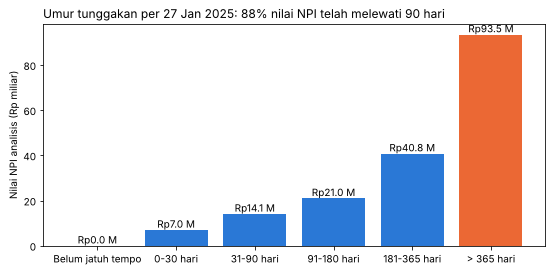

In [ ]:
tunggak = df[df["is_npi"] == 1].copy()
batas_umur = [-1, 30, 90, 180, 365, np.inf]
label_umur = ["0-30 hari", "31-90 hari", "91-180 hari", "181-365 hari", "> 365 hari"]
tunggak["kelompok_umur"] = pd.cut(tunggak["umur_tunggakan_hari"], bins=batas_umur, labels=label_umur).astype(str)
tunggak.loc[tunggak["umur_tunggakan_hari"].isna(), "kelompok_umur"] = "Belum jatuh tempo"
urutan_umur = ["Belum jatuh tempo"] + label_umur

umur = tunggak.groupby("kelompok_umur").agg(jumlah_tagihan=("invoice_id", "count"),
                                            nilai_bruto=("nilai_npi_bruto", "sum"),
                                            nilai_npi=("nilai_npi", "sum")).reindex(urutan_umur, fill_value=0)
umur["nilai_bruto_miliar"] = (umur["nilai_bruto"] / 1e9).round(1)
umur["nilai_npi_miliar"] = (umur["nilai_npi"] / 1e9).round(1)
umur["persen_nilai"] = (umur["nilai_npi"] / umur["nilai_npi"].sum() * 100).round(1)
display(umur[["jumlah_tagihan", "nilai_bruto_miliar", "nilai_npi_miliar", "persen_nilai"]])
lebih_90 = umur.loc[["91-180 hari", "181-365 hari", "> 365 hari"], "persen_nilai"].sum()
lebih_365 = umur.loc["> 365 hari", "nilai_npi"]
print(f"Nilai NPI analisis: Rp{umur.nilai_npi.sum():,.0f} | lebih dari 90 hari: {lebih_90:.1f}% | "
      f"lebih dari 365 hari: Rp{lebih_365 / 1e9:.1f} miliar")

plt.figure(figsize=(9, 4))
warna = [ORANYE if l == "> 365 hari" else BIRU for l in umur.index]
plt.bar(umur.index, umur["nilai_npi_miliar"], color=warna)
for i, v in enumerate(umur["nilai_npi_miliar"]):
    plt.text(i, v + 1, f"Rp{v:.1f} M", ha="center")
plt.title(f"Umur tunggakan per {TANGGAL_SNAPSHOT:%d %b %Y}: {lebih_90:.0f}% nilai NPI telah melewati 90 hari", loc="left")
plt.ylabel("Nilai NPI analisis (Rp miliar)")
plt.show()


**Jawaban P2:** nominal NPI analisis sebesar **Rp176,34 miliar** (bruto Rp224,64 miliar). Tidak ada invoice NPI yang belum jatuh tempo pada tanggal snapshot. **88,0%** nilai telah melewati 90 hari, dan **Rp93,5 miliar (53,0%)** telah berumur lebih dari 1 tahun.

Angka ini merupakan **nominal *aging* tagihan bermasalah**, bukan kerugian permanen dan bukan kas yang pasti tertagih. Karena pada data tidak teramati pembayaran lebih dari 22 hari setelah jatuh tempo, pemulihan tunggakan lama tidak dapat diasumsikan dalam perencanaan cashflow; tingkat pemulihan per umur perlu ditetapkan bersama Finance dengan mempertimbangkan sengketa, biaya penagihan, dan kebijakan penghapusan piutang.


### 6.2.2 Daftar kerja unit prioritas
Daftar disusun **satu baris per unit** dan setiap unit masuk ke **satu tier** saja (urutan kondisi = urutan prioritas). Unit prioritas adalah unit dengan nominal NPI terbesar yang bersama-sama mencakup 50% nilai NPI (H13). Keterjangkauan kontak menentukan apakah unit dapat langsung ditagih atau perlu verifikasi terlebih dahulu.

| Tier | Kriteria | Aksi utama |
|---|---|---|
| 1 | Unit prioritas (50% nilai NPI) dengan kontak terverifikasi | Penagihan langsung melalui kanal digital; tindak lanjut khusus untuk "Janji Bayar" |
| 2 | Unit prioritas dengan kontak kosong atau belum terverifikasi | Verifikasi kontak oleh tim CS, kemudian penagihan |
| 3 | Unit lain yang memiliki NPI dan tidak autodebit pada bulan terakhir | Kampanye autodebit |
| 4 | Unit lainnya | Pemantauan rutin |

Nominal pada daftar ini adalah **nominal NPI milik unit sasaran**, bukan jumlah yang diperkirakan dapat dipulihkan.

In [ ]:
# Ringkasan per unit: 1 baris = 1 unit
profil_unit = df.sort_values("billing_month").groupby("unit_id").agg(
    cluster_id=("cluster_id", "first"),
    township_name=("township_name", "first"),
    skor_risiko=("skor_risiko", "last"),                      # skor pada bulan tagihan terakhir
    autodebit_terakhir=("is_autodebit_enrolled", "last"),
    status_kontak=("status_kontak", "first"),
    tagihan_npi=("is_npi", "sum"),
    nilai_npi=("nilai_npi", "sum"),
    umur_tunggakan_maks=("umur_tunggakan_hari", "max"),
    pernah_ditagih=("pernah_ditagih", "any"),
)
unit_prioritas = tunggakan_unit.head(unit_50).index                    # unit yang mencakup 50% nilai NPI (H13)
prioritas = profil_unit.index.isin(unit_prioritas)
terverifikasi = profil_unit["status_kontak"] == "Ada nomor, terverifikasi"

kondisi = [prioritas & terverifikasi,
           prioritas & ~terverifikasi,
           (profil_unit["tagihan_npi"] > 0) & (profil_unit["autodebit_terakhir"] == 0)]
nama_tier = ["1. Prioritas, kontak terverifikasi", "2. Prioritas, verifikasi kontak dulu", "3. Kampanye autodebit"]
profil_unit["tier"] = np.select(kondisi, nama_tier, default="4. Pemantauan rutin")
profil_unit["tanggal_snapshot"] = TANGGAL_SNAPSHOT.date()

ringkasan_tier = profil_unit.groupby("tier").agg(jumlah_unit=("nilai_npi", "size"),
                                                 nilai_npi_miliar=("nilai_npi", "sum"),
                                                 umur_maks_median_hari=("umur_tunggakan_maks", "median"),
                                                 pernah_ditagih_persen=("pernah_ditagih", "mean"))
ringkasan_tier["nilai_npi_miliar"] /= 1e9
ringkasan_tier["porsi_nilai (%)"] = ringkasan_tier["nilai_npi_miliar"] / ringkasan_tier["nilai_npi_miliar"].sum() * 100
ringkasan_tier["pernah_ditagih_persen"] *= 100
display(ringkasan_tier.round(1))

# Daftar kerja disimpan TANPA nama dan nomor telepon pemilik (data pribadi diambil dari sistem saat eksekusi)
profil_unit.sort_values(["tier", "nilai_npi"], ascending=[True, False]).to_csv("data/unit_prioritas.csv")
print("Daftar kerja tersimpan: data/unit_prioritas.csv |", len(profil_unit), "unit")

,jumlah_unit,nilai_npi_miliar,umur_maks_median_hari,pernah_ditagih_persen,porsi_nilai (%)
tier,,,,,
"1. Prioritas, kontak terverifikasi",3743,46.7,835.0,96.4,26.5
"2. Prioritas, verifikasi kontak dulu",3028,41.5,841.0,97.2,23.5
3. Kampanye autodebit,18076,75.5,713.0,68.4,42.8
4. Pemantauan rutin,4034,12.7,714.0,52.1,7.2


Daftar kerja tersimpan: data/unit_prioritas.csv | 28881 unit


,Unit prioritas,Semua unit
Unit vacant,49.7,24.2
Pemilik luar kota/negeri,64.9,34.6
Tanpa nomor kontak,27.1,17.2
Tidak autodebit (bulan terakhir),90.0,85.7


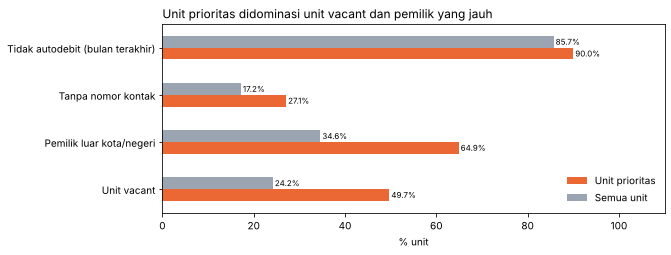

In [ ]:
# Profil unit prioritas dibandingkan seluruh unit
unit_info = units_clean.set_index("unit_id")
profil = pd.DataFrame({
    "Unit prioritas": [unit_info.loc[unit_prioritas, "is_vacant"].mean() * 100,
                       (unit_info.loc[unit_prioritas, "owner_domicile"] != "Dalam Kota").mean() * 100,
                       (~unit_info.loc[unit_prioritas, "punya_kontak"]).mean() * 100,
                       (profil_unit.loc[unit_prioritas, "autodebit_terakhir"] == 0).mean() * 100],
    "Semua unit":     [unit_info["is_vacant"].mean() * 100,
                       (unit_info["owner_domicile"] != "Dalam Kota").mean() * 100,
                       (~unit_info["punya_kontak"]).mean() * 100,
                       (profil_unit["autodebit_terakhir"] == 0).mean() * 100]},
    index=["Unit vacant", "Pemilik luar kota/negeri", "Tanpa nomor kontak", "Tidak autodebit (bulan terakhir)"]).round(1)
display(profil)

ax = profil.plot(kind="barh", figsize=(9, 3.4), color=[ORANYE, ABU])
for wadah in ax.containers:
    ax.bar_label(wadah, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xlim(0, 110)
ax.set_xlabel("% unit")
ax.set_title("Unit prioritas didominasi unit vacant dan pemilik yang jauh", loc="left")
ax.legend(frameon=False)
plt.show()


**Insight:**
- **6.771 unit prioritas** memegang 50% nilai NPI (**Rp88,2 miliar**, nominal milik unit sasaran). Unit tersebut terbagi menjadi **3.743 unit** yang dapat langsung ditagih (kontak terverifikasi; Rp46,7 miliar) dan **3.028 unit** yang memerlukan verifikasi kontak terlebih dahulu (Rp41,5 miliar).
- Hampir seluruh unit prioritas **pernah ditagih** (96–97%) dan median umur tunggakan terlamanya sekitar **835–841 hari**. Artinya, masalah unit prioritas bukan sekadar belum ditagih, melainkan tunggakan lama yang memerlukan program pemulihan khusus.
- **18.076 unit** masuk tier kampanye autodebit dengan nilai NPI **Rp75,5 miliar** (42,8%), sehingga pencegahan melalui autodebit tetap menjadi program massal yang utama.
- Unit prioritas didominasi unit vacant (49,7% vs 24,2% seluruh unit) dan pemilik luar kota/negeri (64,9% vs 34,6%).
- Daftar kerja disimpan ke `data/unit_prioritas.csv` **tanpa nama dan nomor telepon pemilik**, beserta tanggal snapshot. Status hunian, kontak, dan autodebit perlu diperbarui sebelum daftar didistribusikan.


### 6.2.3 Cakupan penagihan per skor risiko

,% pernah ditagih
skor_risiko,
0,24.7
1,25.3
2,28.2
3,34.5
4,38.0


pernah_ditagih,Pernah ditagih,Belum pernah ditagih
skor_risiko,,
0,0.4,1.2
1,10.9,30.8
2,18.1,44.3
3,18.3,33.2
4,7.5,11.7


Nilai NPI yang belum pernah ditagih: Rp121.2 miliar dari Rp176.3 miliar (69%)
   di antaranya berstatus Unpaid: Rp49.7 miliar


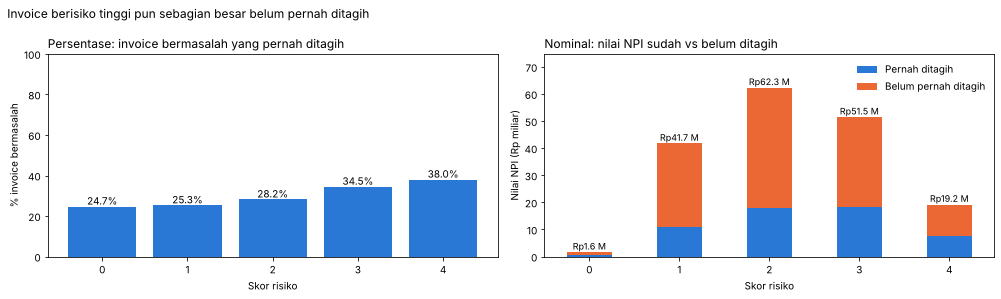

In [ ]:
cakupan_skor = (df[df["is_npi"] == 1].groupby("skor_risiko")["pernah_ditagih"].mean() * 100).round(1)
display(cakupan_skor.to_frame("% pernah ditagih"))

# Nominal: nilai NPI yang sudah dan belum pernah ditagih per skor risiko
cakupan_rp = pd.crosstab(df["skor_risiko"], df["pernah_ditagih"], values=df["nilai_npi"], aggfunc="sum") / 1e9
cakupan_rp = cakupan_rp.rename(columns={True: "Pernah ditagih", False: "Belum pernah ditagih"})[["Pernah ditagih", "Belum pernah ditagih"]]
display(cakupan_rp.round(1))
belum_ditagih = cakupan_rp["Belum pernah ditagih"].sum()
print(f"Nilai NPI yang belum pernah ditagih: Rp{belum_ditagih:.1f} miliar dari Rp{cakupan_rp.values.sum():.1f} miliar "
      f"({belum_ditagih / cakupan_rp.values.sum() * 100:.0f}%)")
nilai_unpaid = df.loc[df["payment_status"] == "Unpaid", "nilai_npi"].sum()
print(f"   di antaranya berstatus Unpaid: Rp{nilai_unpaid / 1e9:.1f} miliar")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(cakupan_skor.index.astype(str), cakupan_skor.values, color=BIRU)
for i, v in enumerate(cakupan_skor.values):
    ax[0].text(i, v + 1, f"{v:.1f}%", ha="center")
ax[0].set_ylim(0, 100)
ax[0].set_title("Persentase: invoice bermasalah yang pernah ditagih", loc="left")
ax[0].set_ylabel("% invoice bermasalah")

cakupan_rp.plot(kind="bar", stacked=True, ax=ax[1], color=[BIRU, ORANYE], rot=0)
for i, total in enumerate(cakupan_rp.sum(axis=1)):
    ax[1].text(i, total + 1, f"Rp{total:.1f} M", ha="center", fontsize=9)
ax[1].set_ylim(0, cakupan_rp.sum(axis=1).max() * 1.2)
ax[1].set_title("Nominal: nilai NPI sudah vs belum ditagih", loc="left")
ax[1].set_ylabel("Nilai NPI (Rp miliar)")
ax[1].legend(frameon=False)
for a in ax:
    a.set_xlabel("Skor risiko")
fig.suptitle("Invoice berisiko tinggi pun sebagian besar belum pernah ditagih", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()


Cakupan penagihan naik sedikit pada invoice berisiko tinggi (24,7% pada skor 0 → 38,0% pada skor 4), tetapi tetap rendah. Secara nominal, **Rp121,2 miliar (69%)** nilai NPI **belum pernah ditagih**, termasuk **Rp49,7 miliar** berstatus Unpaid yang tidak pernah tercatat dalam log aksi. Sebelum disimpulkan sebagai kegagalan cakupan, SOP pencatatan aksi perlu dikonfirmasi (H14).


## 6.3 Tim Finance: metode bayar, autodebit, dan rekonsiliasi

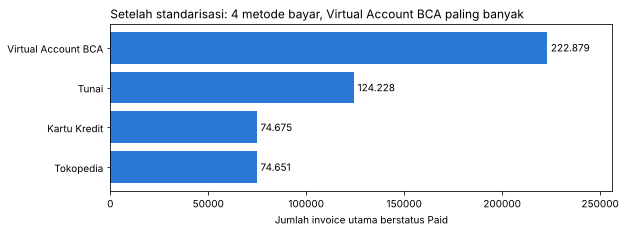

,porsi (%)
payment_method,
Virtual Account BCA,44.90
Tunai,25.02
Kartu Kredit,15.04
Tokopedia,15.04


In [ ]:
metode = df.loc[df["payment_status"] == "Paid", "payment_method"].value_counts()
plt.figure(figsize=(9, 3))
plt.barh(metode.index[::-1], metode.values[::-1], color=BIRU)
for i, v in enumerate(metode.values[::-1]):
    plt.text(v + 2000, i, f"{v:,}".replace(",", "."), va="center")
plt.xlim(0, metode.max() * 1.15)
plt.title("Setelah standarisasi: 4 metode bayar, Virtual Account BCA paling banyak", loc="left")
plt.xlabel("Jumlah invoice utama berstatus Paid")
plt.show()
(metode / metode.sum() * 100).round(2).to_frame("porsi (%)")

,% invoice autodebit,% unit autodebit (bulan terakhir)
Dalam Kota,17.0,16.9
Luar Kota,10.4,10.7
Luar Negeri,5.0,4.0
Dihuni,16.0,15.9
Vacant,9.2,9.4


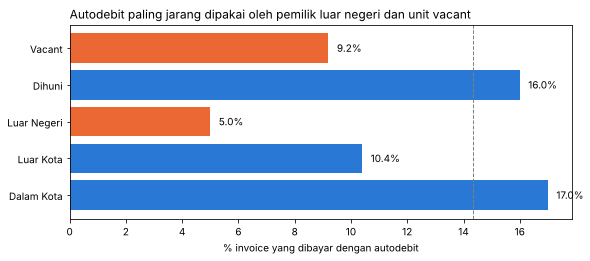

In [ ]:
# Pada segmen mana autodebit masih jarang dipakai? (porsi invoice dan porsi unit pada bulan tagihan terakhir)
unit_terakhir = profil_unit.join(units_clean.set_index("unit_id")[["owner_domicile", "is_vacant"]])
adopsi = pd.concat([
    pd.DataFrame({"% invoice autodebit": df.groupby("owner_domicile")["is_autodebit_enrolled"].mean() * 100,
                  "% unit autodebit (bulan terakhir)": unit_terakhir.groupby("owner_domicile")["autodebit_terakhir"].mean() * 100}),
    pd.DataFrame({"% invoice autodebit": df.groupby("status_hunian")["is_autodebit_enrolled"].mean() * 100,
                  "% unit autodebit (bulan terakhir)": unit_terakhir.groupby(unit_terakhir["is_vacant"].map({0: "Dihuni", 1: "Vacant"}))["autodebit_terakhir"].mean() * 100}),
]).round(1)
display(adopsi)

plt.figure(figsize=(9, 3.5))
warna = [ORANYE if v < 10 else BIRU for v in adopsi["% invoice autodebit"]]
plt.barh(adopsi.index, adopsi["% invoice autodebit"], color=warna)
for i, v in enumerate(adopsi["% invoice autodebit"]):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.axvline(df["is_autodebit_enrolled"].mean() * 100, color="gray", linestyle="--", linewidth=1)
plt.title("Autodebit paling jarang dipakai oleh pemilik luar negeri dan unit vacant", loc="left")
plt.xlabel("% invoice yang dibayar dengan autodebit")
plt.show()

In [ ]:
# Rekonsiliasi sengketa: nominal koreksi TIDAK otomatis mengurangi NPI, karena bergantung pada status invoice-nya
koreksi = sengketa_utama.merge(df[["invoice_id", "payment_status", "total_amount"]], on="invoice_id", validate="one_to_one")
koreksi["batal_penuh"] = (koreksi["resolution_status"] == "Dibatalkan - Tagihan Salah") & (koreksi["amount_adjusted"] >= koreksi["total_amount"])
rekon_sengketa = koreksi.pivot_table(index="resolution_status", columns="payment_status", values="amount_adjusted",
                                     aggfunc="sum", fill_value=0) / 1e9
display(rekon_sengketa.round(2))

batal_npi = koreksi[koreksi["batal_penuh"] & koreksi["payment_status"].isin(["Unpaid", "Overdue"])]
batal_paid = koreksi[koreksi["batal_penuh"] & (koreksi["payment_status"] == "Paid")]
daftar_rekon = pd.DataFrame({
    "jumlah": [len(batal_npi), len(batal_paid), len(paid_ganda)],
    "nominal_Rp_miliar": [batal_npi["total_amount"].sum() / 1e9, batal_paid["total_amount"].sum() / 1e9, nominal_paid_ganda / 1e9],
    "tindak_lanjut": ["Tutup status NPI apabila pembatalan disahkan", "Periksa kewajiban pengembalian dana/kredit",
                      "Cocokkan dengan mutasi bank sebelum pengembalian dana"],
}, index=["Invoice NPI yang telah dibatalkan penuh", "Invoice Paid yang telah dibatalkan penuh",
          "Pasangan tagihan ganda Paid + Paid"]).round(2)
daftar_rekon

payment_status,Overdue,Paid,Unpaid
resolution_status,,,
Dibatalkan - Tagihan Salah,9.25,21.78,2.7
Diproses,0.00,0.00,0.0
Ditolak - Tagihan Sah,0.00,0.00,0.0


,jumlah,nominal_Rp_miliar,tindak_lanjut
Invoice NPI yang telah dibatalkan penuh,3795,11.94,Tutup status NPI apabila pembatalan disahkan
Invoice Paid yang telah dibatalkan penuh,5953,21.78,Periksa kewajiban pengembalian dana/kredit
Pasangan tagihan ganda Paid + Paid,12568,11.07,Cocokkan dengan mutasi bank sebelum pengembali...



**Insight:**
- Setelah standarisasi, metode bayar invoice utama berstatus Paid tinggal 4 kategori: **Virtual Account BCA (44,90%)**, **Tunai (25,02%)**, **Kartu Kredit (15,04%)**, dan **Tokopedia (15,04%)**. Tabel `mapping_metode` pada 4.9 dapat langsung diusulkan sebagai **master data** dengan kode standar dan validasi saat input.
- Autodebit paling jarang dipakai oleh segmen dengan NPI tertinggi: pemilik **Luar Negeri (5,0% invoice; 4,0% unit pada bulan terakhir)**, **Luar Kota (10,4%)**, dan **unit vacant (9,2%)**. Segmen ini menjadi sasaran utama kampanye autodebit.
- **Nominal koreksi sengketa tidak otomatis mengurangi NPI.** Koreksi pada invoice utama tersebar pada invoice Paid (Rp21,78 miliar), Overdue (Rp9,25 miliar), dan Unpaid (Rp2,70 miliar). Daftar rekonsiliasi Finance: **3.795 invoice NPI** yang telah dibatalkan penuh (Rp11,94 miliar; statusnya belum diperbarui), **5.953 invoice Paid** yang telah dibatalkan penuh (Rp21,78 miliar; potensi kewajiban pengembalian dana atau kredit), dan **12.568 pasangan Paid + Paid** (Rp11,07 miliar).


## 6.4 Tim IT/ERP: kesalahan data yang perlu diperbaiki
Temuan diurutkan berdasarkan **dampak nominal**, kemudian jumlah baris dan jumlah unit yang terdampak. Status temuan dibedakan antara **kesalahan data** dan **kebijakan yang perlu dikonfirmasi**.

,jumlah_baris,jumlah_unit,status_temuan,nominal_Rp_miliar
temuan,,,,
Air di atas batas wajar (Manual),3789,3314,Perlu validasi meter,149.87
Salinan tagihan ganda (pola 9xxxx),38449,21877,Kesalahan data,21.76
Pasangan ganda Paid + Paid,12568,10092,Perlu rekonsiliasi,11.07
Paid terlambat tanpa denda,46656,21888,Kebijakan perlu dikonfirmasi,0.00
Tanggal bayar sebelum periode tagihan,11236,8809,Kesalahan data,0.00
Respon Lunas Setelah Kontak tidak sinkron,5580,5162,Sinkronisasi sistem,0.00
Nomor kontak kosong,4978,4978,Kelengkapan data,0.00
Air negatif (Manual),3824,3389,Kesalahan data,0.00


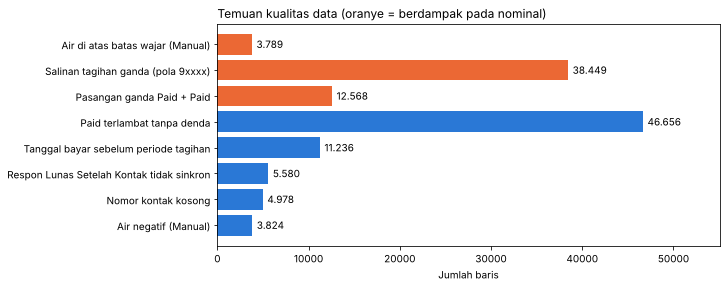

In [ ]:
air_tinggi = billings_clean["air_tidak_wajar"]
temuan = pd.DataFrame([
    ["Salinan tagihan ganda (pola 9xxxx)", len(salinan), salinan["nilai_npi_bruto"].sum(), salinan["unit_id"].nunique(), "Kesalahan data"],
    ["Pasangan ganda Paid + Paid", len(paid_ganda), nominal_paid_ganda, len(paid_ganda.get_level_values("unit_id").unique()), "Perlu rekonsiliasi"],
    ["Air di atas batas wajar (Manual)", air_tinggi.sum(), billings_clean.loc[air_tinggi, "komponen_air"].sum(),
     billings_clean.loc[air_tinggi, "unit_id"].nunique(), "Perlu validasi meter"],
    ["Air negatif (Manual)", billings_clean["air_negatif"].sum(), 0, billings_clean.loc[billings_clean["air_negatif"], "unit_id"].nunique(), "Kesalahan data"],
    ["Tanggal bayar sebelum periode tagihan", billings_clean["bayar_sebelum_periode"].sum(), 0,
     billings_clean.loc[billings_clean["bayar_sebelum_periode"], "unit_id"].nunique(), "Kesalahan data"],
    ["Respon Lunas Setelah Kontak tidak sinkron", lunas_tidak_sinkron.sum(), 0, cek_aksi.loc[lunas_tidak_sinkron, "unit_id"].nunique(), "Sinkronisasi sistem"],
    ["Nomor kontak kosong", units["contact_number"].isna().sum(), 0, units["contact_number"].isna().sum(), "Kelengkapan data"],
    ["Paid terlambat tanpa denda", (paid_telat & (billings["late_fee_penalty"] == 0)).sum(), 0,
     billings.loc[paid_telat, "unit_id"].nunique(), "Kebijakan perlu dikonfirmasi"],
], columns=["temuan", "jumlah_baris", "nominal_Rp", "jumlah_unit", "status_temuan"]).set_index("temuan")
temuan["nominal_Rp_miliar"] = (temuan.pop("nominal_Rp") / 1e9).round(2)
temuan = temuan.sort_values(["nominal_Rp_miliar", "jumlah_baris"], ascending=False)
display(temuan)

plt.figure(figsize=(9, 4))
warna = [ORANYE if v > 0 else BIRU for v in temuan["nominal_Rp_miliar"]]
plt.barh(temuan.index[::-1], temuan["jumlah_baris"][::-1], color=warna[::-1])
for i, v in enumerate(temuan["jumlah_baris"][::-1]):
    plt.text(v + 500, i, f"{v:,}".replace(",", "."), va="center")
plt.xlim(0, temuan["jumlah_baris"].max() * 1.18)
plt.title("Temuan kualitas data (oranye = berdampak pada nominal)", loc="left")
plt.xlabel("Jumlah baris")
plt.show()


**Insight:**
- Berdasarkan **dampak nominal**, temuan terbesar adalah **pemakaian air di atas batas wajar** (3.789 invoice; komponen air **Rp149,87 miliar** pada seluruh status), diikuti **salinan tagihan ganda** (38.449 invoice; nominal NPI bruto pada salinan **Rp21,76 miliar**) dan **pasangan Paid + Paid** (Rp11,07 miliar).
- Berdasarkan **jumlah baris**, temuan terbesar adalah **Paid terlambat tanpa denda (46.656)**, tetapi statusnya adalah **kebijakan yang perlu dikonfirmasi**, karena tidak ada satu pun invoice Paid yang memiliki denda.
- Air negatif dan di atas batas wajar (3.824 + 3.789 invoice) tidak terbukti berasosiasi dengan NPI (H16), tetapi tetap perlu validasi input karena memengaruhi nominal tagihan dan memicu sengketa.


## 6.5 Ringkasan Visual

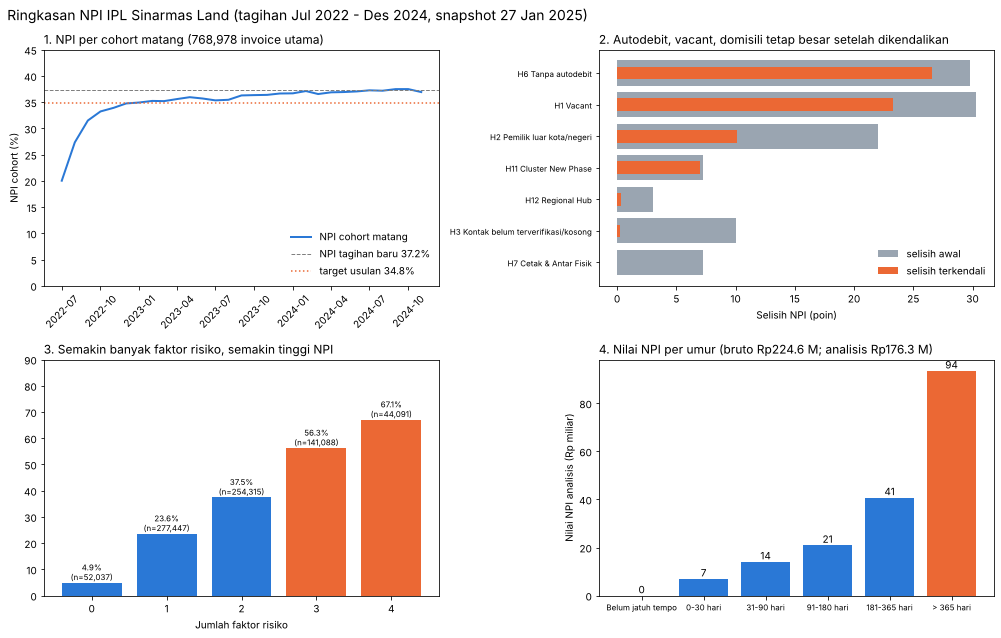

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

ax[0, 0].plot(matang.index, matang["npi_cohort"], color=BIRU, linewidth=2, label="NPI cohort matang")
ax[0, 0].axhline(npi_dasar, color="gray", linestyle="--", linewidth=1, label=f"NPI tagihan baru {npi_dasar:.1f}%")
ax[0, 0].axhline(target_npi, color=ORANYE, linestyle=":", linewidth=1.5, label=f"target usulan {target_npi:.1f}%")
ax[0, 0].legend(frameon=False, loc="lower right")
ax[0, 0].set_ylim(0, 45)
ax[0, 0].tick_params(axis="x", rotation=45)
ax[0, 0].set_title(f"1. NPI per cohort matang ({len(df):,} invoice utama)", loc="left")
ax[0, 0].set_ylabel("NPI cohort (%)")

terkendali = kendali.sort_values("selisih_terkendali (poin)")
ax[0, 1].barh(terkendali.index, terkendali["selisih_awal (poin)"], color=ABU, label="selisih awal")
ax[0, 1].barh(terkendali.index, terkendali["selisih_terkendali (poin)"], color=ORANYE, height=0.4, label="selisih terkendali")
ax[0, 1].tick_params(axis="y", labelsize=8)
ax[0, 1].legend(frameon=False, loc="lower right")
ax[0, 1].set_title("2. Autodebit, vacant, domisili tetap besar setelah dikendalikan", loc="left")
ax[0, 1].set_xlabel("Selisih NPI (poin)")

warna = [ORANYE if i >= 3 else BIRU for i in tabel_skor.index]
ax[1, 0].bar(tabel_skor.index.astype(str), tabel_skor["npi_rate"], color=warna)
for i, (v, n) in enumerate(zip(tabel_skor["npi_rate"], tabel_skor["jumlah_tagihan"])):
    ax[1, 0].text(i, v + 1, f"{v:.1f}%\n(n={n:,})", ha="center", fontsize=8)
ax[1, 0].set_ylim(0, 90)
ax[1, 0].set_title("3. Semakin banyak faktor risiko, semakin tinggi NPI", loc="left")
ax[1, 0].set_xlabel("Jumlah faktor risiko")

warna = [ORANYE if l == "> 365 hari" else BIRU for l in umur.index]
ax[1, 1].bar(umur.index, umur["nilai_npi_miliar"], color=warna)
for i, v in enumerate(umur["nilai_npi_miliar"]):
    ax[1, 1].text(i, v + 1, f"{v:.0f}", ha="center")
ax[1, 1].tick_params(axis="x", labelsize=8)
ax[1, 1].set_title(f"4. Nilai NPI per umur (bruto Rp{npi_bruto / 1e9:.1f} M; analisis Rp{nilai_tunggakan / 1e9:.1f} M)", loc="left")
ax[1, 1].set_ylabel("Nilai NPI analisis (Rp miliar)")

plt.suptitle(f"Ringkasan NPI IPL Sinarmas Land (tagihan Jul 2022 - Des 2024, snapshot {TANGGAL_SNAPSHOT:%d %b %Y})", fontsize=14, x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 6.6 Menjawab Pertanyaan Pemantik Brief
Brief §6 memuat 6 pertanyaan pemantik. Sebagian telah terjawab pada Tahap 4–6; bagian ini melengkapi yang belum dan merangkum seluruhnya.

| # | Pertanyaan pemantik | Dijawab di |
|---|---|---|
| 1 | Karakteristik apa yang membedakan unit dengan riwayat pembayaran baik dari yang bermasalah? | 5.3–5.5, 5.9, 6.1.1, **6.6.1** |
| 2 | Apakah kesimpulan di level agregat (township) tetap konsisten di level yang lebih detail (cluster, periode)? | H13, **6.6.2** |
| 3 | Bagaimana pola pemakaian air berhubungan dengan karakteristik unit, dan apakah semua nilai ekstrem layak dianggap kesalahan data? | 4.6, **6.6.3** |
| 4 | Apakah upaya penagihan menunjukkan hubungan dengan perubahan status pembayaran berikutnya? | H14, 6.2.3, **6.6.4** |
| 5 | Data apa yang masih kurang untuk menjawab problem statement? | 2.3, **6.6.5** |
| 6 | Sejauh mana sengketa berujung koreksi, dan apakah polanya konsisten di semua alasan? | H17, 6.3, **6.6.6** |

### 6.6.1 Unit dengan riwayat pembayaran baik vs bermasalah
Analisis pada Tahap 5 dilakukan per **invoice**. Di sini setiap **unit** dikelompokkan berdasarkan persentase tagihannya yang tidak dibayar, kemudian karakteristik ketiga kelompok dibandingkan. Ambang 20% dan 50% merupakan parameter pengelompokan.

In [ ]:
# Ringkas data per unit: 1 baris = 1 unit
per_unit = df.groupby("unit_id").agg(
    npi_unit=("is_npi", "mean"),                       # persentase tagihan unit yang tidak dibayar
    autodebit=("is_autodebit_enrolled", "mean"),       # persentase tagihan yang dibayar dengan autodebit
    is_vacant=("is_vacant", "first"),                   # "first" karena nilainya sama pada seluruh tagihan unit tersebut
    owner_domicile=("owner_domicile", "first"),
    punya_kontak=("punya_kontak", "first"),
    launch_phase=("launch_phase", "first"),
)
per_unit["kelompok"] = pd.cut(per_unit["npi_unit"], bins=[-0.01, 0.2, 0.5, 1.0],
                              labels=["Lancar (NPI <= 20%)", "Kadang menunggak (20-50%)", "Bermasalah (NPI > 50%)"])
print(per_unit["kelompok"].value_counts().sort_index())

profil_kelompok = per_unit.groupby("kelompok", observed=False).agg(
    unit_vacant=("is_vacant", "mean"),
    pemilik_jauh=("owner_domicile", lambda x: (x != "Dalam Kota").mean()),
    tanpa_nomor=("punya_kontak", lambda x: (~x.astype(bool)).mean()),
    cluster_new_phase=("launch_phase", lambda x: x.str.contains("New Phase").mean()),
    autodebit=("autodebit", "mean"),
) * 100
profil_kelompok.round(1)

kelompok
Lancar (NPI <= 20%)           8239
Kadang menunggak (20-50%)    13846
Bermasalah (NPI > 50%)        6796
Name: count, dtype: int64


,unit_vacant,pemilik_jauh,tanpa_nomor,cluster_new_phase,autodebit
kelompok,,,,,
Lancar (NPI <= 20%),1.3,10.4,10.5,32.1,19.2
Kadang menunggak (20-50%),15.7,31.1,15.6,44.9,14.2
Bermasalah (NPI > 50%),69.5,70.8,28.8,53.4,8.2


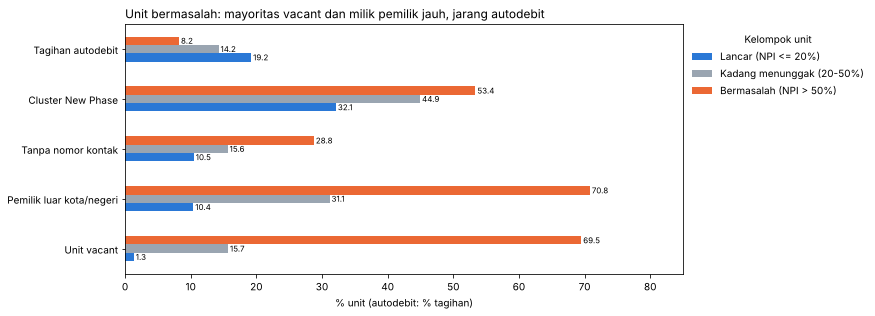

In [ ]:
label_rapi = {"unit_vacant": "Unit vacant", "pemilik_jauh": "Pemilik luar kota/negeri", "tanpa_nomor": "Tanpa nomor kontak",
              "cluster_new_phase": "Cluster New Phase", "autodebit": "Tagihan autodebit"}
ax = profil_kelompok.rename(columns=label_rapi).T.plot(kind="barh", figsize=(10, 4.5), color=[BIRU, ABU, ORANYE])
for wadah in ax.containers:
    ax.bar_label(wadah, fmt="%.1f", fontsize=8, padding=2)
ax.set_xlim(0, 85)
ax.set_xlabel("% unit (autodebit: % tagihan)")
ax.set_title("Unit bermasalah: mayoritas vacant dan milik pemilik jauh, jarang autodebit", loc="left")
ax.legend(title="Kelompok unit", frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()


**Jawaban:** dari 28.881 unit, **8.239 unit lancar** (NPI ≤ 20%) dan **6.796 unit bermasalah** (NPI > 50%). Perbedaan keduanya sangat jelas:
- **Unit vacant:** 1,3% pada kelompok lancar vs **69,5%** pada kelompok bermasalah.
- **Pemilik luar kota/luar negeri:** 10,4% vs **70,8%**.
- **Tanpa nomor kontak:** 10,5% vs **28,8%**; **cluster New Phase:** 32,1% vs 53,4%.
- **Autodebit:** 19,2% tagihan pada unit lancar vs hanya **8,2%** pada unit bermasalah.

Hasil pada level unit sejalan dengan hasil pada level invoice (H1, H2, H3, H6, H11): unit bermasalah umumnya **unit kosong milik pemilik yang jauh dan tidak memakai autodebit**.


### 6.6.2 Apakah kesimpulan konsisten pada setiap township dan setiap tahun?

In [ ]:
df["tahun"] = df["billing_month"].dt.year
df["pemilik_jauh"] = np.where(df["owner_domicile"] == "Dalam Kota", "Dalam Kota", "Luar Kota/Negeri")

def selisih_per(kolom_pecah, kolom_faktor, berisiko, pembanding):
    # Selisih NPI kelompok berisiko vs pembanding, dihitung terpisah untuk setiap township atau tahun
    tabel = df.pivot_table(index=kolom_pecah, columns=kolom_faktor, values="is_npi", aggfunc="mean") * 100
    return (tabel[berisiko] - tabel[pembanding]).round(1)

for pecah in ["township_name", "tahun"]:
    konsistensi = pd.DataFrame({
        "Vacant - Dihuni": selisih_per(pecah, "status_hunian", "Vacant", "Dihuni"),
        "Tanpa - Dengan autodebit": selisih_per(pecah, "autodebit", "Tanpa autodebit", "Autodebit"),
        "Luar Kota/Negeri - Dalam Kota": selisih_per(pecah, "pemilik_jauh", "Luar Kota/Negeri", "Dalam Kota"),
    })
    print(f"Selisih NPI (poin persen) per {pecah}:")
    display(konsistensi)

Selisih NPI (poin persen) per township_name:


,Vacant - Dihuni,Tanpa - Dengan autodebit,Luar Kota/Negeri - Dalam Kota
township_name,,,
BSD City,29.7,30.2,21.9
Deltamas,29.7,29.9,21.7
Grand Wisata,30.6,29.5,22.2
Kota Wisata,30.7,29.7,22.1
NavaPark,33.1,29.1,26.2


Selisih NPI (poin persen) per tahun:


,Vacant - Dihuni,Tanpa - Dengan autodebit,Luar Kota/Negeri - Dalam Kota
tahun,,,
2022,29.8,26.8,21.7
2023,30.8,29.8,22.1
2024,30.1,30.8,22.1


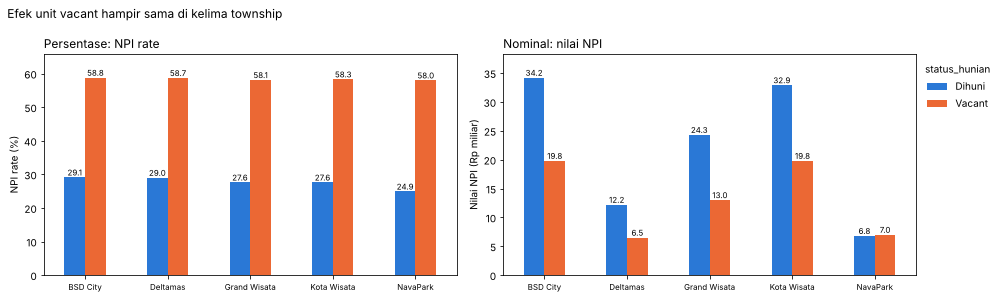

status_hunian,Dihuni,Vacant
tahun,,
2022,23.1,52.9
2023,28.4,59.1
2024,29.7,59.9


In [ ]:
grafik_dua_dimensi("township_name", "status_hunian", "Efek unit vacant hampir sama di kelima township")
(df.pivot_table(index="tahun", columns="status_hunian", values="is_npi", aggfunc="mean") * 100).round(1)


**Jawaban:** ya, kesimpulannya **konsisten**.
- Pada **kelima township**, NPI unit vacant selalu sekitar 29,7–33,1 poin lebih tinggi daripada unit dihuni, invoice tanpa autodebit sekitar 29,1–30,2 poin lebih tinggi, dan pemilik jauh sekitar 21,7–26,2 poin lebih tinggi.
- Pada **setiap tahun cohort** (2022, 2023, 2024) polanya sama. NPI seluruh kelompok naik dari 2022 ke 2024, tetapi selisih antarkelompok tetap besar.
- Pada level **cluster**, tunggakan tidak terkonsentrasi (H13), sedangkan pada level **unit** cukup terkonsentrasi (6.771 unit = 50% nilai NPI).

Secara **nominal**, nilai NPI terbesar terdapat di **BSD City (Rp53,91 M)** dan **Kota Wisata (Rp52,70 M)** karena jumlah unitnya paling banyak. Masalahnya bukan pada township atau periode tertentu, melainkan pada **karakteristik unit dan pemiliknya**, dan polanya bertahan sepanjang waktu.


### 6.6.3 Pemakaian air dan karakteristik unit
Nilai yang perlu validasi (negatif dan di atas batas wajar) dikeluarkan terlebih dahulu agar pola pemakaian normal terlihat.

In [ ]:
air_wajar = df[~df["flag_validasi_air"]].copy()

print("Median pemakaian air (m3) per kelompok:")
for kolom in ["status_hunian", "unit_type", "cluster_category"]:
    display(air_wajar.groupby(kolom)["water_usage_m3"].median().to_frame("median_m3"))

air_wajar["kelompok_luas"] = pd.qcut(air_wajar["unit_size_m2"], 4, labels=["Kecil", "Sedang", "Besar", "Sangat besar"])
display(air_wajar.groupby("kelompok_luas", observed=False)["water_usage_m3"].median().to_frame("median_m3"))
print("Korelasi luas unit dengan pemakaian air:", round(air_wajar["water_usage_m3"].corr(air_wajar["unit_size_m2"]), 2))

Median pemakaian air (m3) per kelompok:


,median_m3
status_hunian,
Dihuni,17.7
Vacant,1.5


,median_m3
unit_type,
Ruko,19.3
Rumah Tapak,14.7


,median_m3
cluster_category,
Commercial Ruko,19.3
Industrial/Commercial,47.0
Middle Residential,14.2
Premium Residential,26.0


,median_m3
kelompok_luas,
Kecil,12.1
Sedang,14.0
Besar,15.8
Sangat besar,20.3


Korelasi luas unit dengan pemakaian air: 0.38


In [ ]:
# Invoice dengan pemakaian 0 m3: berasal dari unit mana?
nol = df[df["water_usage_m3"] == 0]
print(f"Invoice dengan air 0 m3: {len(nol)} | dari unit vacant: {nol.is_vacant.mean() * 100:.1f}% "
      f"(porsi vacant pada seluruh invoice: {df.is_vacant.mean() * 100:.1f}%)")

# Apakah nilai di atas batas wajar menumpuk pada jenis unit tertentu? Porsinya dibandingkan dengan seluruh invoice
ekstrem = df[df["air_tidak_wajar"]]
banding = pd.DataFrame({
    "air > batas wajar (%)": ekstrem["cluster_category"].value_counts(normalize=True) * 100,
    "seluruh invoice (%)": df["cluster_category"].value_counts(normalize=True) * 100,
})
banding.loc["Unit vacant"] = [ekstrem["is_vacant"].mean() * 100, df["is_vacant"].mean() * 100]
banding.round(1)

Invoice dengan air 0 m3: 32726 | dari unit vacant: 93.6% (porsi vacant pada seluruh invoice: 24.2%)


,air > batas wajar (%),seluruh invoice (%)
cluster_category,,
Middle Residential,81.8,82.9
Premium Residential,12.5,11.9
Commercial Ruko,5.4,4.7
Industrial/Commercial,0.3,0.4
Unit vacant,24.6,24.2


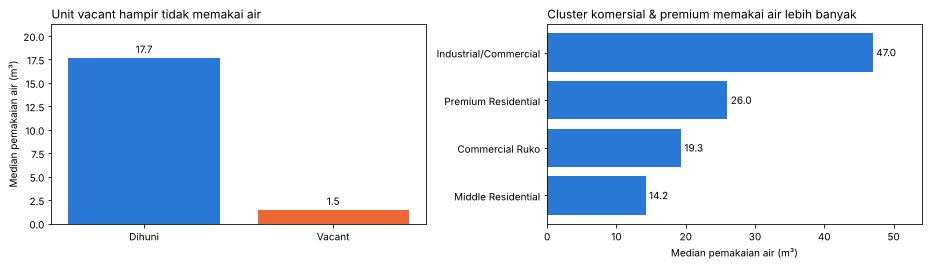

In [ ]:
median_hunian = air_wajar.groupby("status_hunian")["water_usage_m3"].median()
median_kategori = air_wajar.groupby("cluster_category")["water_usage_m3"].median().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(median_hunian.index, median_hunian.values, color=[BIRU, ORANYE])
for i, v in enumerate(median_hunian.values):
    ax[0].text(i, v + 0.5, f"{v:.1f}", ha="center")
ax[0].set_ylim(0, median_hunian.max() * 1.2)
ax[0].set_title("Unit vacant hampir tidak memakai air", loc="left")
ax[0].set_ylabel("Median pemakaian air (m³)")

ax[1].barh(median_kategori.index, median_kategori.values, color=BIRU)
for i, v in enumerate(median_kategori.values):
    ax[1].text(v + 0.5, i, f"{v:.1f}", va="center")
ax[1].set_xlim(0, median_kategori.max() * 1.15)
ax[1].set_title("Cluster komersial & premium memakai air lebih banyak", loc="left")
ax[1].set_xlabel("Median pemakaian air (m³)")
plt.tight_layout()
plt.show()


**Jawaban:**
- **Pemakaian air sangat berkaitan dengan karakteristik unit.** Unit dihuni memakai median **17,7 m³**, sedangkan unit vacant hanya **1,5 m³**. Pemakaian juga naik sesuai luas unit (korelasi 0,38) dan lebih tinggi di cluster Industrial/Commercial (47,0 m³), Premium (26,0 m³), dan Ruko (19,3 m³) dibandingkan Middle Residential (14,2 m³).
- **93,6% invoice dengan air 0 m³ berasal dari unit vacant**, sehingga nilai 0 merupakan pola yang wajar, bukan kesalahan.
- **Tidak semua nilai ekstrem merupakan kesalahan.** Nilai 47–97,8 m³ masih wajar (sesuai meteran Otomatis dan cluster komersial). Nilai yang **perlu validasi** adalah nilai negatif dan di atas 97,8 m³, karena: (1) seluruhnya berasal dari input Manual, (2) tidak ada nilai antara 97,8 dan 504 m³, dan (3) porsinya per kategori cluster dan per status vacant **hampir sama dengan porsi pada seluruh invoice**. Nilai tersebut muncul acak dan tidak mengikuti karakteristik unit, sehingga polanya **konsisten dengan salah input**. Kepastian akhirnya tetap memerlukan log atau foto meter.


### 6.6.4 Apakah penagihan berhubungan dengan pembayaran bulan berikutnya?
Untuk setiap invoice **Overdue**, diperiksa apakah invoice unit yang sama **pada bulan berikutnya** dibayar. Agar urutan waktu benar, hanya aksi yang terjadi **sebelum periode tagihan bulan berikutnya dimulai** yang dipakai sebagai informasi penagihan. Respon yang dicatat petugas tetap diperlakukan sebagai sinyal, bukan bukti pembayaran.

In [ ]:
# Aksi diberi tanggal awal periode tagihan bulan berikutnya, lalu hanya aksi sebelum tanggal tersebut yang dipakai
aksi_waktu = actions.merge(df[["invoice_id", "billing_month"]], on="invoice_id", validate="many_to_one")
aksi_waktu = aksi_waktu[aksi_waktu["action_date"] < aksi_waktu["billing_month"] + pd.DateOffset(months=1)]
print(f"Aksi yang terjadi sebelum periode tagihan berikutnya: {len(aksi_waktu):,} dari {len(actions):,}")

aksi_per_invoice = aksi_waktu.sort_values("action_date").groupby("invoice_id").agg(
    jumlah_aksi=("action_id", "count"), respon_terakhir=("response_status", "last"))
overdue = df[df["payment_status"] == "Overdue"][["invoice_id", "unit_id", "billing_month", "status_hunian"]]
overdue = overdue.merge(aksi_per_invoice, on="invoice_id", how="left", validate="one_to_one")
overdue["ditagih"] = np.where(overdue["jumlah_aksi"].notna(), "Ditagih", "Tidak ditagih")

# Invoice bulan berikutnya untuk unit yang sama: billing_month digeser mundur 1 bulan agar dapat dipasangkan
bulan_depan = df[["unit_id", "billing_month", "is_npi"]].copy()
bulan_depan["billing_month"] = bulan_depan["billing_month"] - pd.DateOffset(months=1)
bulan_depan = bulan_depan.rename(columns={"is_npi": "npi_bulan_depan"})
overdue = overdue.merge(bulan_depan, on=["unit_id", "billing_month"], how="inner", validate="one_to_one")

print("Invoice Overdue yang memiliki invoice bulan berikutnya:", len(overdue))
display((overdue.groupby("ditagih")["npi_bulan_depan"].mean() * 100).round(1).to_frame("% tidak dibayar bulan depan"))
display((overdue.groupby(["status_hunian", "ditagih"])["npi_bulan_depan"].mean() * 100).round(1).unstack())
respon_bulan_depan = (overdue.groupby("respon_terakhir")["npi_bulan_depan"].mean() * 100).round(1).sort_values()
respon_bulan_depan.to_frame("% tidak dibayar bulan depan")

Aksi yang terjadi sebelum periode tagihan berikutnya: 109,115 dari 126,772
Invoice Overdue yang memiliki invoice bulan berikutnya: 186415


,% tidak dibayar bulan depan
ditagih,
Ditagih,72.4
Tidak ditagih,71.2


ditagih,Ditagih,Tidak ditagih
status_hunian,,
Dihuni,67.3,67.4
Vacant,78.0,77.4


,% tidak dibayar bulan depan
respon_terakhir,
Lunas Setelah Kontak,0.0
Janji Bayar,61.5
Tidak Respon,83.1
Sengketa,84.2


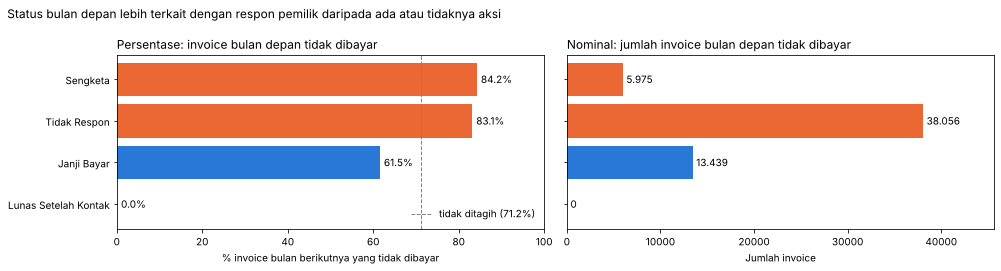

In [ ]:
npi_tidak_ditagih = overdue[overdue["ditagih"] == "Tidak ditagih"]["npi_bulan_depan"].mean() * 100
nominal_bulan_depan = overdue.groupby("respon_terakhir")["npi_bulan_depan"].sum()[respon_bulan_depan.index]
warna = [BIRU if v < npi_tidak_ditagih else ORANYE for v in respon_bulan_depan.values]   # oranye = lebih buruk dari tidak ditagih

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
ax[0].barh(respon_bulan_depan.index, respon_bulan_depan.values, color=warna)
for i, v in enumerate(respon_bulan_depan.values):
    ax[0].text(v + 1, i, f"{v:.1f}%", va="center")
ax[0].axvline(npi_tidak_ditagih, color="gray", linestyle="--", linewidth=1, label=f"tidak ditagih ({npi_tidak_ditagih:.1f}%)")
ax[0].set_xlim(0, 100)
ax[0].legend(frameon=False, loc="lower right")
ax[0].set_title("Persentase: invoice bulan depan tidak dibayar", loc="left")
ax[0].set_xlabel("% invoice bulan berikutnya yang tidak dibayar")

ax[1].barh(nominal_bulan_depan.index, nominal_bulan_depan.values, color=warna)
for i, v in enumerate(nominal_bulan_depan.values):
    ax[1].text(v + nominal_bulan_depan.max() * 0.01, i, f"{v:,}".replace(",", "."), va="center")
ax[1].set_xlim(0, nominal_bulan_depan.max() * 1.2)
ax[1].set_title("Nominal: jumlah invoice bulan depan tidak dibayar", loc="left")
ax[1].set_xlabel("Jumlah invoice")
fig.suptitle("Status bulan depan lebih terkait dengan respon pemilik daripada ada atau tidaknya aksi", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()


**Jawaban:**
- Setelah urutan waktu dijaga (109.115 dari 126.772 aksi terjadi sebelum periode tagihan berikutnya), **penagihan belum menunjukkan hubungan dengan pembayaran bulan berikutnya.** Invoice bulan depan dari unit yang ditagih tetap tidak dibayar **72,4%**, hampir sama dengan unit yang tidak ditagih (**71,2%**). Polanya sama pada unit dihuni maupun vacant.
- Perbedaan baru terlihat menurut **respon pemilik**: pemilik dengan respon terakhir "Lunas Setelah Kontak" membayar seluruh invoice bulan berikutnya (0% tidak dibayar), "Janji Bayar" 61,5%, sedangkan "Tidak Respon" (83,1%) dan "Sengketa" (84,2%) lebih buruk daripada rata-rata.
- Artinya, yang lebih menentukan adalah **apakah pemilik berhasil diajak berkomunikasi hingga berkomitmen**, bukan sekadar menerima aksi. Hal ini mendukung penagihan melalui kanal yang dapat direspons dan tindak lanjut khusus untuk "Janji Bayar".
- **Keterbatasan:** hubungan ini bukan sebab-akibat, karena pemilik yang mau merespons kemungkinan memang lebih disiplin; invoice yang ditagih juga berbeda karakteristiknya dari yang tidak ditagih. Respon "Lunas Setelah Kontak" tidak sinkron dengan billing (4.7), sehingga hanya dapat dipakai sebagai sinyal.


### 6.6.5 Data yang masih kurang
| Data yang dibutuhkan | Untuk menjawab | Alasan | Sumber yang mungkin |
|---|---|---|---|
| Tanggal ekstraksi/snapshot resmi | P2, aging | Menggantikan asumsi `TANGGAL_SNAPSHOT` | Log ekstraksi tim IT/ERP |
| Riwayat perubahan status pembayaran per invoice | P1, H14 | Mengukur NPI operasional bulanan dan *roll-rate*, bukan hanya status terakhir | Sistem billing |
| Bukti pembayaran hasil aksi Collection (tanggal & nominal) | H14, 6.6.4 | Efektivitas penagihan yang sebenarnya | Sinkronisasi actions dengan billings |
| SOP pencatatan aksi (mengapa hanya invoice Overdue yang tercatat) | H14 | Memastikan cakupan penagihan yang rendah bukan akibat aturan pencatatan | Tim Collection |
| Mutasi bank / data *payment gateway* | H18, 6.3 | Merekonsiliasi pasangan Paid + Paid dan invoice yang telah dibatalkan | Tim Finance |
| Kebijakan denda dan toleransi keterlambatan | 4.7, 6.4 | Menilai apakah "Paid terlambat tanpa denda" merupakan kesalahan | Tim Finance |
| Log/foto meter air dan aturan batas pemakaian per jenis unit | 4.6, 6.6.3 | Memvalidasi invoice di atas batas wajar sebelum dikoreksi | Estate Ops |
| Biaya program, insentif autodebit, dan kapasitas petugas | 6.1.2, 7.2 | Menghitung manfaat bersih program | Finance & Collection |
| Alasan tidak membayar dan kepuasan layanan | H4, H5 | Membuktikan penyebab, bukan hanya hubungan | Survei pemilik, catatan call center |
| Riwayat waktu pengiriman pengingat | H10 | Menguji pengingat tanpa *reverse causality* | Sistem notifikasi |
| Riwayat kepemilikan dan status sewa unit | H1, H2 | Unit vacant dapat saja sedang disewakan atau dijual | Data legal/marketing |
| Anggaran operasional dan subsidi perusahaan induk | 1.1 | Mengukur risiko cashflow yang sebenarnya | Tim Finance |

### 6.6.6 Sengketa dan koreksi tagihan

In [ ]:
selesai = disputes[disputes["resolution_status"] != "Diproses"]
ringkas_sengketa = selesai.groupby("dispute_reason").agg(
    jumlah=("dispute_id", "count"),
    persen_dibatalkan=("resolution_status", lambda x: (x == "Dibatalkan - Tagihan Salah").mean() * 100),
    rata_hari_selesai=("days_to_resolve", "mean"),
    total_koreksi_Rp_miliar=("amount_adjusted", lambda x: x.sum() / 1e9),
).round(1).sort_values("persen_dibatalkan", ascending=False)
jumlah_diproses = (disputes["resolution_status"] == "Diproses").sum()
print(f"Total nilai koreksi sengketa selesai: Rp{selesai.amount_adjusted.sum():,.0f} "
      f"(pada invoice utama: Rp{koreksi.amount_adjusted.sum():,.0f})")
print(f"Sengketa masih Diproses: {jumlah_diproses:,}")
ringkas_sengketa

Total nilai koreksi sengketa selesai: Rp39,688,189,500 (pada invoice utama: Rp33,719,795,000)
Sengketa masih Diproses: 2,722


,jumlah,persen_dibatalkan,rata_hari_selesai,total_koreksi_Rp_miliar
dispute_reason,,,,
Duplikat Tagihan,15069,91.2,5.1,12.2
Pemakaian Air Tidak Wajar,1733,76.7,5.2,26.5
Sudah Bayar Tapi Tercatat Belum Lunas,1961,35.4,5.1,0.5
Kesalahan Nominal Lainnya,2443,34.7,5.1,0.6



**Jawaban:**
- Sengketa **cukup sering berujung koreksi**, tetapi **tidak konsisten antaralasan**. Duplikat Tagihan (**91,2%** dari sengketa selesai) dan Pemakaian Air Tidak Wajar (**76,7%**) mayoritas dibatalkan karena tagihannya memang salah, sedangkan Sudah Bayar Tapi Tercatat Belum Lunas (35,4%) dan Kesalahan Nominal Lainnya (34,7%) lebih sering ditolak.
- Total koreksi sengketa selesai sekitar **Rp39,69 miliar** (Rp33,72 miliar pada invoice utama). **Rp26,5 miliar** di antaranya berasal dari sengketa air tidak wajar, karena nilai tagihan air yang salah sangat besar. Nominal ini **tidak otomatis mengurangi NPI**, karena sebagian koreksi terjadi pada invoice yang telah Paid (6.3).
- Rata-rata penyelesaian sekitar **5 hari** untuk seluruh alasan, sedangkan **2.722 sengketa** masih berstatus Diproses. Kasus sengketa air yang berlarut berminggu-minggu sebagaimana disebut brief tidak terlihat pada sengketa yang telah selesai.



# 7.0 Kesimpulan & Rekomendasi
## 7.1 Kesimpulan
**Status hipotesis:**
| Status | Hipotesis |
|---|---|
| Didukung data, efek besar dan tetap kuat setelah dikendalikan | **H6** tanpa autodebit (39,71% vs 9,93%; terkendali +26,59 poin), **H1** vacant (58,43% vs 28,11%; +23,28 poin), **H2** pemilik jauh (49,93% vs 27,88%; +10,14 poin) |
| Didukung data, efek sedang | **H11** New Phase (+7,24; terkendali +7,00 poin), **H17** disengketakan (+7,47 poin; arah hubungan belum jelas) |
| Didukung data sebelum pengendalian, hampir hilang setelah dikendalikan | **H3** tanpa kontak, **H7** cetak fisik, **H12** Regional Hub |
| Didukung data, efek kecil | **H8** tarif tinggi (+4,51 poin) |
| Rekonsiliasi kualitas data | **H18** tagihan ganda (−1,52 poin pada NPI agregat) |
| Tidak didukung data | **H9** jatuh tempo, **H16** meteran Manual (faktor pengganggu: fase cluster), **H13** konsentrasi cluster |
| Belum dapat diuji | **H14** jenis aksi penagihan (outcome konstan) |
| Tidak dapat diuji dengan data yang tersedia | H4, H5, H10, H15 |

**Menjawab problem statement SMART dan tujuan analisis:**
1. **Baseline NPI 35,44%** (per 27 Januari 2025); NPI tagihan baru (enam cohort matang terakhir) **37,24%**. Target usulan: **≤ 34,8%** NPI tagihan baru dalam 2 kuartal (skenario dasar program autodebit), menunggu pengesahan manajemen setelah pilot.
2. **Segmen penyumbang tunggakan:** bukan township atau cluster tertentu, melainkan **invoice tanpa autodebit, unit vacant, pemilik luar kota/luar negeri, dan cluster New Phase**. Invoice dengan keempat faktor tersebut memiliki NPI 67,10%, dan **6.771 unit** memegang separuh nilai NPI.
3. **Nominal tagihan bermasalah:** bruto **Rp224,64 miliar**, nominal analisis **Rp176,34 miliar** setelah komponen air yang perlu validasi dipisahkan; 88,0% telah melewati 90 hari dan Rp93,5 miliar lebih dari 1 tahun. Angka ini bukan kerugian permanen dan bukan kas yang pasti tertagih.
4. **Standar metode bayar:** Virtual Account BCA, Tunai, Kartu Kredit, dan Tokopedia.
5. **Kualitas data:** salinan tagihan ganda, pemakaian air yang perlu validasi, tanggal bayar tidak logis, status Collection yang tidak sinkron, kontak kosong, serta kebijakan denda yang perlu dikonfirmasi.
6. **Pertanyaan pemantik (6.6):** unit bermasalah umumnya vacant (69,5%) dan milik pemilik jauh (70,8%); polanya konsisten pada seluruh township dan tahun; pemakaian air mengikuti karakteristik unit, sedangkan nilai di atas batas wajar muncul acak; penagihan baru berhubungan dengan pembayaran bulan berikutnya apabila pemilik merespons; sengketa air menyumbang Rp26,5 miliar dari Rp39,69 miliar koreksi.

**Ketercapaian tujuan analisis brief:**

| No | Tujuan analisis (brief) | Status | Bukti dari pengolahan data | Bagian | Yang masih memerlukan validasi |
|---|---|---|---|---|---|
| 1 | Mengidentifikasi karakteristik & segmen unit/kawasan penyumbang tunggakan sebagai dasar prioritas tim Collection | ✅ **Tercapai** | Faktor yang tetap kuat setelah dikendalikan: tanpa autodebit, vacant, pemilik jauh, New Phase. Daftar kerja **6.771 unit prioritas** (50% nilai NPI) dalam tier yang saling eksklusif. | 5.3–5.9, 6.1.1, 6.2.2, 6.6.1–6.6.2 | Dari sisi **kawasan**, tidak ada township/cluster yang dominan; status unit perlu diperbarui sebelum daftar didistribusikan. |
| 2 | Mengestimasi potensi pendapatan yang tertahan/hilang akibat tunggakan berkepanjangan | ⚠️ **Tercapai sebagai estimasi awal** | Nominal bruto Rp224,64 miliar dan analisis Rp176,34 miliar; 88,0% > 90 hari; Rp93,5 miliar > 1 tahun. Potensi NPI baru yang dapat dicegah ±Rp0,46 miliar/bulan (skenario dasar). | 5.1, 6.1.2, 6.2.1, 7.2 | Nominal bersih setelah rekonsiliasi sengketa dan tagihan ganda, tingkat pemulihan per umur, nilai yang dihapuskan, dan realisasi kas. |
| 3 | Merumuskan skema standarisasi pencatatan metode pembayaran untuk tim Finance | ✅ **Tercapai** | 9 variasi → **4 kategori standar** (tabel `mapping_metode`), dengan pemeriksaan label yang belum terpetakan. | 4.5, 4.9, 6.3 | Konfirmasi Finance apakah terdapat metode lain di luar data ini. |
| 4 | Mengevaluasi kualitas data tagihan untuk tim IT/ERP | ✅ **Tercapai** | Kelengkapan (4.978 unit tanpa kontak), konsistensi antartabel (0 orphan), dan kesalahan input (38.449 salinan, 3.824/3.789 anomali air, 11.236 tanggal bayar tidak logis, 5.580 status tidak sinkron), diurutkan menurut dampak nominal. | 4.2–4.8, 6.4, 6.6.5 | Penyebab teknis di sistem ERP perlu ditelusuri bersama tim IT/ERP. |
| – | Catatan brief: merumuskan **baseline dan target terukur** | ✅ **Tercapai (target berstatus usulan)** | Baseline **35,44%**; NPI tagihan baru 37,24% → target usulan **≤ 34,8%** dalam 2 kuartal. | 5.1, 6.1.2, 7.3 | Pengesahan manajemen setelah pilot, biaya program, dan kapasitas tim. |

Kesimpulannya, **tujuan eksplorasi awal tercapai**; estimasi kas, nominal bersih, dan efektivitas intervensi masih membutuhkan validasi melalui rekonsiliasi Finance dan pilot terkontrol.


## 7.2 Estimasi Dampak Tindakan
Dampak dihitung pada **periode dasar** (enam cohort matang terakhir) sebagai **NPI tagihan baru yang berpotensi dicegah per bulan**. Besar efek memakai **selisih terkendali** (5.9), sehingga asosiasi yang sama tidak dihitung dua kali oleh beberapa tindakan, dan dampak gabungan dapat dijumlahkan sebagai pendekatan. Porsi berubah dan tingkat keberhasilan (skenario dasar 50%) merupakan parameter.

In [ ]:
def potensi(nama, nama_faktor, sasaran, porsi_berubah, tingkat=TINGKAT_BERHASIL["dasar"]):
    # Potensi penurunan NPI tagihan baru apabila sebagian invoice sasaran berubah perilaku sebesar efek terkendali
    efek = max(kendali.loc[nama_faktor, "selisih_terkendali (poin)"], 0) / 100
    dicegah = tingkat * porsi_berubah * sasaran.sum() * efek
    return {"tindakan": nama, "invoice_sasaran_per_bulan": sasaran.sum() / jumlah_bulan, "porsi_berubah": f"{porsi_berubah:.0%}",
            "efek_awal (poin)": kendali.loc[nama_faktor, "selisih_awal (poin)"], "efek_terkendali (poin)": efek * 100,
            "penurunan_npi (poin)": dicegah / len(dasar) * 100,
            "nominal_dicegah_per_bulan (Rp juta)": dicegah * rata_nominal_npi / jumlah_bulan / 1e6}

dampak = pd.DataFrame([
    potensi(f"Autodebit untuk {PORSI_BERALIH:.0%} unit eligible", "H6 Tanpa autodebit",
            dasar["unit_id"].isin(unit_eligible) & (dasar["is_autodebit_enrolled"] == 0), PORSI_BERALIH),
    potensi("Pindahkan 50% tagihan Cetak Fisik ke Portal", "H7 Cetak & Antar Fisik",
            dasar["billing_channel"] == "Cetak & Antar Fisik", 0.50),
    potensi("Lengkapi & verifikasi 50% kontak yang belum terverifikasi", "H3 Kontak belum terverifikasi/kosong",
            dasar["status_kontak"] != "Ada nomor, terverifikasi", 0.50),
]).set_index("tindakan")
dampak.loc["Gabungan ketiga tindakan"] = [np.nan, "-", np.nan, np.nan,
                                          dampak["penurunan_npi (poin)"].sum(), dampak["nominal_dicegah_per_bulan (Rp juta)"].sum()]
tingkat_dasar = TINGKAT_BERHASIL["dasar"]
print(f"Skenario dasar (tingkat keberhasilan {tingkat_dasar:.0%}); NPI periode dasar {npi_dasar:.2f}%")
dampak.round(2)

Skenario dasar (tingkat keberhasilan 50%); NPI periode dasar 37.24%


,invoice_sasaran_per_bulan,porsi_berubah,efek_awal (poin),efek_terkendali (poin),penurunan_npi (poin),nominal_dicegah_per_bulan (Rp juta)
tindakan,,,,,,
Autodebit untuk 25% unit eligible,21119.17,25%,29.78,26.59,2.46,462.26
Pindahkan 50% tagihan Cetak Fisik ke Portal,7504.83,50%,7.26,0.00,0.00,0.00
Lengkapi & verifikasi 50% kontak yang belum terverifikasi,8867.17,50%,10.05,0.24,0.02,3.50
Gabungan ketiga tindakan,NaN,-,NaN,NaN,2.48,465.76



**Insight estimasi dampak:**
- Pada skenario dasar, **program autodebit** untuk 25% unit eligible berpotensi menurunkan NPI tagihan baru sekitar **2,46 poin** dan mencegah sekitar **Rp462 juta** NPI baru per bulan.
- **Perpindahan kanal ke Portal** dan **verifikasi kontak** hampir tidak menurunkan NPI apabila memakai efek terkendali (0,00 dan 0,02 poin), karena selisih awalnya dijelaskan oleh faktor lain (5.9). Kedua tindakan tetap bermanfaat untuk **keterjangkauan dan efisiensi biaya**, tetapi tidak boleh dijanjikan sebagai penurun NPI.
- Dampak gabungan ketiga tindakan sekitar **2,48 poin** (±Rp466 juta per bulan). Seluruh angka adalah **nominal NPI yang berpotensi dicegah**, bukan kas tambahan, dan belum dikurangi biaya program.



## 7.3 Rekomendasi (Actor + Action + Time + Impact)
| Actor | Action | Time | Impact / KPI | Batasan |
|---|---|---|---|---|
| **Head of Township Management** | Menyetujui **pilot** autodebit dan penagihan unit prioritas dengan **grup kontrol**, beserta target interim, pemilik program, biaya, dan review bulanan | Bulan pertama; evaluasi tiap akhir kuartal | NPI tagihan baru, nominal NPI baru, kas yang benar-benar diterima, biaya program, manfaat bersih | Target ≤ 34,8% adalah usulan hingga hasil pilot dan tanggal snapshot resmi tervalidasi |
| **Tim Finance & Collection** | Menjalankan **kampanye autodebit** untuk 24.754 unit eligible, dengan sasaran utama pemilik luar kota/luar negeri dan unit vacant | Kuartal 1–2 | Adopsi autodebit unit 14,3% → 35,7% (25% unit eligible); NPI tagihan baru turun ±2,5 poin (skenario dasar) | Efek autodebit adalah asosiasi (*self-selection*); biaya insentif perlu dibandingkan dengan ±Rp0,46 miliar/bulan NPI yang berpotensi dicegah |
| **Tim Collection** | Menagih **3.743 unit Tier 1** terlebih dahulu melalui kanal digital dan menindaklanjuti setiap "Janji Bayar"; menyiapkan **program pemulihan/cicilan** untuk tunggakan lebih dari 1 tahun | Kuartal 1–2 | *Collection rate* 30/60/90 hari dan nominal yang benar-benar tertagih dari Rp88,2 miliar nominal NPI unit prioritas | Janji bayar dibedakan dari kas yang diterima; tunggakan > 22 hari belum pernah teramati dilunasi |
| **Tim CS** | Memverifikasi kontak **3.028 unit Tier 2**, kemudian 4.978 unit tanpa nomor | Kuartal 1 (enam minggu pertama) | Porsi unit dengan kontak terverifikasi (baseline 69,0%), tingkat respons | Verifikasi kontak meningkatkan keterjangkauan, bukan penurunan NPI secara langsung (5.9) |
| **Tim Finance** | Menetapkan **4 kode metode bayar** sebagai master data dengan validasi input; merekonsiliasi 12.568 pasangan Paid + Paid, 3.795 invoice NPI dan 5.953 invoice Paid yang telah dibatalkan penuh; mengonfirmasi definisi Unpaid/Overdue dan kebijakan denda | Kuartal 1 | Jumlah metode tak dikenal = 0; nominal yang belum direkonsiliasi; rasio invoice tidak sinkron | Pengembalian dana hanya setelah dicocokkan dengan mutasi bank |
| **Tim IT/ERP** | Menerapkan aturan **satu invoice per unit per bulan**, validasi input meter (konfirmasi apabila di luar 0–97,8 m³ untuk input Manual), sinkronisasi status Collection dan sengketa ke billing, penyimpanan riwayat status dan tanggal ekstraksi | Kuartal 1–2 | Jumlah salinan baru = 0; jumlah kasus air di luar aturan; jumlah status/tanggal tidak logis | Batas air 97,8 m³ memerlukan aturan operasional resmi per jenis unit |
| **Estate Ops** | Menginvestigasi 3.789 invoice air di atas batas wajar dengan log/foto meter dan mempercepat peralihan ke meter Otomatis | Kuartal 1–2 | Seluruh kasus memiliki hasil verifikasi; tingkat pembatalan sengketa air | Pemakaian air tidak dikoreksi otomatis ke median tanpa bukti meter |

**Target yang dibedakan menurut jenisnya:**
| Jenis target | Indikator | Baseline dari data | Target usulan akhir kuartal 2 |
|---|---|---|---|
| Kualitas data | Salinan tagihan ganda baru; metode bayar di luar kode master; anomali air tanpa status investigasi | 38.449 salinan; 9 variasi penulisan; 7.613 invoice | 0; 4 kode baku; 0 |
| Operasional (*leading indicator*) | Unit dengan kontak terverifikasi; cakupan invoice NPI yang pernah ditagih; adopsi autodebit unit | 69,0%; 30,4%; 14,3% | Naik bertahap; naik bertahap; ≥ 35,7% |
| Bisnis | NPI tagihan baru (cohort matang); nominal NPI baru per bulan | 37,24%; ±Rp6,9 miliar per cohort | ≤ 34,8%; turun sesuai hasil pilot |
| Finansial | Piutang berstatus NPI, saldo setelah koreksi sah, kas masuk, piutang yang dihapuskan | Bruto Rp224,64 miliar; analisis Rp176,34 miliar | Ditetapkan Finance setelah rekonsiliasi |

**Narasi rekomendasi:**
1. **Head of Township Management** agar **pada bulan pertama** menyetujui pilot autodebit dan penagihan terfokus dengan grup kontrol, sehingga dampak sebenarnya dapat diukur sebelum target resmi ditetapkan.
2. **Tim Finance dan Collection** agar **selama kuartal 1–2** menjalankan kampanye autodebit bagi unit yang belum autodebit, dengan sasaran utama pemilik jauh dan unit vacant, untuk **menurunkan NPI tagihan baru sekitar 2,5 poin pada skenario dasar**.
3. **Tim Collection** agar **selama 2 kuartal ke depan** menagih unit prioritas Tier 1 terlebih dahulu dan menyiapkan program pemulihan tunggakan lama, untuk **memulihkan sebagian nominal NPI milik unit prioritas**.
4. **Tim CS** agar **dalam kuartal pertama** memverifikasi kontak unit prioritas Tier 2, untuk **menjangkau pemilik yang selama ini tidak dapat dihubungi**.
5. **Tim Finance dan IT/ERP** agar **dalam kuartal pertama** menuntaskan rekonsiliasi dan perbaikan sistem billing, untuk **membuat angka NPI akurat, mencegah tagihan ganda, dan mengurangi sengketa warga**.



## 7.4 Keterbatasan & Tindak Lanjut
- **Status per snapshot:** data hanya menyimpan status terakhir; NPI cohort bukan NPI operasional bulanan. Tanggal snapshot (27 Januari 2025) merupakan **asumsi** dari kejadian terakhir pada data dan perlu dikonfirmasi dengan log ekstraksi.
- **Asosiasi, bukan sebab-akibat:** pengendalian faktor (5.9) hanya mencakup faktor yang tercatat. Program autodebit dan penagihan sebaiknya **diuji coba** pada sebagian unit dan dibandingkan dengan unit yang tidak ditawari program.
- **Keputusan analitis yang belum disahkan:** aturan invoice utama (pola 9xxxx), batas wajar air 97,8 m³, dan pemisahan komponen air perlu disahkan oleh IT/ERP, Estate Ops, dan Finance.
- **Efektivitas Collection belum dapat diukur:** log aksi hanya memuat invoice Overdue dan belum tersinkron dengan pembayaran; Kunjungan Lapangan tidak tercatat.
- **Nominal bukan kas:** nominal NPI adalah tagihan bermasalah; nilai bersih setelah koreksi sengketa, tagihan ganda, dan pembayaran yang belum tertaut memerlukan rekonsiliasi per invoice.
- H4, H5, H10, dan H15 tidak dapat diuji; daftar data yang perlu dikumpulkan tercantum pada **6.6.5**.



## 7.5 Metodologi, Asumsi, dan Tindak Lanjut Review
**Sumber dan reproduksibilitas**
- Sumber data: lima snapshot CSV mentah hasil `SELECT *` dari database `sinarmasland` (`sml_clusters_raw.csv`, `sml_units_raw.csv`, `sml_ipl_billings_raw.csv`, `sml_collection_actions_raw.csv`, `sml_payment_disputes_raw.csv`); periode tagihan Juli 2022 – Desember 2024.
- Kode koneksi dan ekstraksi diarsipkan sebagai komentar; notebook dijalankan dari kernel bersih secara berurutan (*Restart & Run All*) tanpa mengekstrak ulang database.
- Data pribadi (nama dan nomor telepon) disamarkan pada output, dan daftar kerja Collection disimpan tanpa data pribadi.

**Asumsi dan parameter analisis**
| Asumsi / parameter | Nilai | Dasar |
|---|---|---|
| Tanggal snapshot | 27 Januari 2025 | Kejadian terakhir pada data (maksimum `payment_date`, `action_date`, `dispute_date`) |
| Invoice utama | Invoice non-9xxxx pada pasangan unit-bulan | Bukti pada 4.4 (nominal identik, tidak ada pembayaran yang hanya tercatat pada salinan) |
| Batas wajar air | 97,8 m³ | Celah kosong 97,8–504 m³ dan maksimum meteran Otomatis |
| Batas cohort matang | Jatuh tempo + 22 hari | Pembayaran paling terlambat yang teramati |
| Ambang relevansi selisih | 2 / 5 / 20 poin | Parameter penerjemahan selisih menjadi prioritas bisnis |
| Bootstrap per unit | 300 ulangan, `seed=42` | Interval kepercayaan yang memperhitungkan invoice berulang per unit |
| Tingkat keberhasilan program | 25% / 50% / 100% | Konservatif, dasar, dan batas atas |
| Porsi unit beralih ke autodebit | 25% unit eligible | Skenario program autodebit |
| Jendela outcome penagihan | 30 hari setelah aksi pertama | Satu siklus tagihan bulanan |

**Tindak lanjut hasil review**
| Isu review | Perbaikan pada notebook |
|---|---|
| Ekstraksi bercampur dengan analisis; urutan eksekusi tidak berurutan | Ekstraksi diarsipkan; analisis membaca snapshot CSV mentah dan dijalankan ulang dari kernel bersih |
| Tanggal acuan aging memakai jatuh tempo maksimum | `TANGGAL_SNAPSHOT` dari kejadian terakhir pada data; kategori "Belum jatuh tempo" berdasarkan `due_date > TANGGAL_SNAPSHOT` |
| Duplikat hanya diperiksa pada baris kedua dan langsung dihapus | Investigasi dengan `keep=False`, bukti pasangan, penanda dan alasan eksklusi, serta rekonsiliasi sebelum/sesudah |
| Seluruh invoice air > 100 m³ dikeluarkan dari nominal; air negatif tetap ikut | Nominal bruto dipertahankan; hanya komponen air invoice beranomali yang dipisahkan sebagai nominal perlu validasi |
| Label "terbukti" dan p-value 0; tidak ada koreksi multiple testing | Status "didukung data", CI bootstrap per unit, Cramér's V, p-value "< 0,001", dan koreksi Holm |
| Faktor saling berkaitan belum diuji bersamaan | Selisih terkendali dengan stratifikasi faktor lain (5.9) |
| Label tren bulanan | Disajikan sebagai NPI per cohort pada snapshot dengan pemeriksaan kematangan cohort |
| Outcome Collection memakai respon petugas | Outcome per invoice berdasarkan `payment_date` dalam 30 hari setelah aksi; urutan waktu dijaga pada 6.6.4 |
| Simulasi "kas tambahan" dari invoice historis | Populasi unit eligible, efek terkendali, tiga tingkat keberhasilan, dan istilah "NPI yang berpotensi dicegah" |
| Nominal koreksi sengketa langsung dianggap pengurang NPI | Rekonsiliasi koreksi per status invoice (6.3) |
| Nomor kontak tampil utuh di output | Nomor dan nama pemilik disamarkan; daftar prioritas tanpa data pribadi |
